In [36]:
import os
import shutil
import warnings

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

import kagglehub


In [37]:


# Download latest version
path = kagglehub.dataset_download("yelp-dataset/yelp-dataset")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\iscap\.cache\kagglehub\datasets\yelp-dataset\yelp-dataset\versions\4


-------------------------------------------

In [38]:

files = os.listdir(path)
print("Files in dataset:", files)

target_path = os.getcwd() #instead of defining the target path with the open locel path, I just used the folder where the notebook is. So that we dont need to change each time when we receive a new commit. More efficient to work together

# Create the destination directory if it does not exist
os.makedirs(target_path, exist_ok=True)

# Loop through and move each file/folder
for file_name in os.listdir(path):
    src_file = os.path.join(path, file_name)
    dst_file = os.path.join(target_path, file_name)

    shutil.move(src_file, dst_file)
    print(f"Moved: {file_name}")

print("\nAll files moved successfully!")

Files in dataset: []

All files moved successfully!


-------------------------------------------

In [39]:
# Get all .json files in the folder

json_files = [f for f in os.listdir(target_path) if f.endswith(".json")]

for file_name in json_files:
    file_path = os.path.join(target_path, file_name)

    print("=" * 70)
    print(f" FILE: {file_name}")
    print("=" * 70)

    # Read 5 rows safely without loading the full file into memory
    df = pd.read_json(file_path, lines=True, nrows=5000)
    #df = pd.read_json(file_path, lines=True)


    print("\n--- Schema Info ---")
    df.info()

    print("\n--- Preview ---")
    display(df.head())
    print("\n")

 FILE: yelp_academic_dataset_business.json

--- Schema Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   business_id   5000 non-null   object 
 1   name          5000 non-null   object 
 2   address       5000 non-null   object 
 3   city          5000 non-null   object 
 4   state         5000 non-null   object 
 5   postal_code   5000 non-null   object 
 6   latitude      5000 non-null   float64
 7   longitude     5000 non-null   float64
 8   stars         5000 non-null   float64
 9   review_count  5000 non-null   int64  
 10  is_open       5000 non-null   int64  
 11  attributes    4559 non-null   object 
 12  categories    4995 non-null   object 
 13  hours         4218 non-null   object 
dtypes: float64(3), int64(2), object(9)
memory usage: 547.0+ KB

--- Preview ---


,business_id,name,address,city,state,postal_code,latitude,longitude,stars,review_count,is_open,attributes,categories,hours
0,Pns2l4eNsfO8kk83dixA6A,"Abby Rappoport, LAC, CMQ","1616 Chapala St, Ste 2",Santa Barbara,CA,93101,34.426679,-119.711197,5.0,7,0,{'ByAppointmentOnly': 'True'},"Doctors, Traditional Chinese Medicine, Naturop...",None
1,mpf3x-BjTdTEA3yCZrAYPw,The UPS Store,87 Grasso Plaza Shopping Center,Affton,MO,63123,38.551126,-90.335695,3.0,15,1,{'BusinessAcceptsCreditCards': 'True'},"Shipping Centers, Local Services, Notaries, Ma...","{'Monday': '0:0-0:0', 'Tuesday': '8:0-18:30', ..."
2,tUFrWirKiKi_TAnsVWINQQ,Target,5255 E Broadway Blvd,Tucson,AZ,85711,32.223236,-110.880452,3.5,22,0,"{'BikeParking': 'True', 'BusinessAcceptsCredit...","Department Stores, Shopping, Fashion, Home & G...","{'Monday': '8:0-22:0', 'Tuesday': '8:0-22:0', ..."
3,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,935 Race St,Philadelphia,PA,19107,39.955505,-75.155564,4.0,80,1,"{'RestaurantsDelivery': 'False', 'OutdoorSeati...","Restaurants, Food, Bubble Tea, Coffee & Tea, B...","{'Monday': '7:0-20:0', 'Tuesday': '7:0-20:0', ..."
4,mWMc6_wTdE0EUBKIGXDVfA,Perkiomen Valley Brewery,101 Walnut St,Green Lane,PA,18054,40.338183,-75.471659,4.5,13,1,"{'BusinessAcceptsCreditCards': 'True', 'Wheelc...","Brewpubs, Breweries, Food","{'Wednesday': '14:0-22:0', 'Thursday': '16:0-2..."




 FILE: yelp_academic_dataset_checkin.json

--- Schema Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   business_id  5000 non-null   object
 1   date         5000 non-null   object
dtypes: object(2)
memory usage: 78.3+ KB

--- Preview ---


,business_id,date
0,---kPU91CF4Lq2-WlRu9Lw,"2020-03-13 21:10:56, 2020-06-02 22:18:06, 2020..."
1,--0iUa4sNDFiZFrAdIWhZQ,"2010-09-13 21:43:09, 2011-05-04 23:08:15, 2011..."
2,--30_8IhuyMHbSOcNWd6DQ,"2013-06-14 23:29:17, 2014-08-13 23:20:22"
3,--7PUidqRWpRSpXebiyxTg,"2011-02-15 17:12:00, 2011-07-28 02:46:10, 2012..."
4,--7jw19RH9JKXgFohspgQw,"2014-04-21 20:42:11, 2014-04-28 21:04:46, 2014..."




 FILE: yelp_academic_dataset_review.json

--- Schema Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   review_id    5000 non-null   object        
 1   user_id      5000 non-null   object        
 2   business_id  5000 non-null   object        
 3   stars        5000 non-null   int64         
 4   useful       5000 non-null   int64         
 5   funny        5000 non-null   int64         
 6   cool         5000 non-null   int64         
 7   text         5000 non-null   object        
 8   date         5000 non-null   datetime64[ns]
dtypes: datetime64[ns](1), int64(4), object(4)
memory usage: 351.7+ KB

--- Preview ---


,review_id,user_id,business_id,stars,useful,funny,cool,text,date
0,KU_O5udG6zpxOg-VcAEodg,mh_-eMZ6K5RLWhZyISBhwA,XQfwVwDr-v0ZS3_CbbE5Xw,3,0,0,0,"If you decide to eat here, just be aware it is...",2018-07-07 22:09:11
1,BiTunyQ73aT9WBnpR9DZGw,OyoGAe7OKpv6SyGZT5g77Q,7ATYjTIgM3jUlt4UM3IypQ,5,1,0,1,I've taken a lot of spin classes over the year...,2012-01-03 15:28:18
2,saUsX_uimxRlCVr67Z4Jig,8g_iMtfSiwikVnbP2etR0A,YjUWPpI6HXG530lwP-fb2A,3,0,0,0,Family diner. Had the buffet. Eclectic assortm...,2014-02-05 20:30:30
3,AqPFMleE6RsU23_auESxiA,_7bHUi9Uuf5__HHc_Q8guQ,kxX2SOes4o-D3ZQBkiMRfA,5,1,0,1,"Wow! Yummy, different, delicious. Our favo...",2015-01-04 00:01:03
4,Sx8TMOWLNuJBWer-0pcmoA,bcjbaE6dDog4jkNY91ncLQ,e4Vwtrqf-wpJfwesgvdgxQ,4,1,0,1,Cute interior and owner (?) gave us tour of up...,2017-01-14 20:54:15




 FILE: yelp_academic_dataset_tip.json

--- Schema Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   object        
 1   business_id       5000 non-null   object        
 2   text              5000 non-null   object        
 3   date              5000 non-null   datetime64[ns]
 4   compliment_count  5000 non-null   int64         
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 195.4+ KB

--- Preview ---


,user_id,business_id,text,date,compliment_count
0,AGNUgVwnZUey3gcPCJ76iw,3uLgwr0qeCNMjKenHJwPGQ,Avengers time with the ladies.,2012-05-18 02:17:21,0
1,NBN4MgHP9D3cw--SnauTkA,QoezRbYQncpRqyrLH6Iqjg,They have lots of good deserts and tasty cuban...,2013-02-05 18:35:10,0
2,-copOvldyKh1qr-vzkDEvw,MYoRNLb5chwjQe3c_k37Gg,It's open even when you think it isn't,2013-08-18 00:56:08,0
3,FjMQVZjSqY8syIO-53KFKw,hV-bABTK-glh5wj31ps_Jw,Very decent fried chicken,2017-06-27 23:05:38,0
4,ld0AperBXk1h6UbqmM80zw,_uN0OudeJ3Zl_tf6nxg5ww,Appetizers.. platter special for lunch,2012-10-06 19:43:09,0




 FILE: yelp_academic_dataset_user.json

--- Schema Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   user_id             5000 non-null   object 
 1   name                5000 non-null   object 
 2   review_count        5000 non-null   int64  
 3   yelping_since       5000 non-null   object 
 4   useful              5000 non-null   int64  
 5   funny               5000 non-null   int64  
 6   cool                5000 non-null   int64  
 7   elite               5000 non-null   object 
 8   friends             5000 non-null   object 
 9   fans                5000 non-null   int64  
 10  average_stars       5000 non-null   float64
 11  compliment_hot      5000 non-null   int64  
 12  compliment_more     5000 non-null   int64  
 13  compliment_profile  5000 non-null   int64  
 14  compliment_cute     5000 non-null   int64 

,user_id,name,review_count,yelping_since,useful,funny,cool,elite,friends,fans,...,compliment_more,compliment_profile,compliment_cute,compliment_list,compliment_note,compliment_plain,compliment_cool,compliment_funny,compliment_writer,compliment_photos
0,qVc8ODYU5SZjKXVBgXdI7w,Walker,585,2007-01-25 16:47:26,7217,1259,5994,2007,"NSCy54eWehBJyZdG2iE84w, pe42u7DcCH2QmI81NX-8qA...",267,...,65,55,56,18,232,844,467,467,239,180
1,j14WgRoU_-2ZE1aw1dXrJg,Daniel,4333,2009-01-25 04:35:42,43091,13066,27281,"2009,2010,2011,2012,2013,2014,2015,2016,2017,2...","ueRPE0CX75ePGMqOFVj6IQ, 52oH4DrRvzzl8wh5UXyU0A...",3138,...,264,184,157,251,1847,7054,3131,3131,1521,1946
2,2WnXYQFK0hXEoTxPtV2zvg,Steph,665,2008-07-25 10:41:00,2086,1010,1003,"2009,2010,2011,2012,2013","LuO3Bn4f3rlhyHIaNfTlnA, j9B4XdHUhDfTKVecyWQgyA...",52,...,13,10,17,3,66,96,119,119,35,18
3,SZDeASXq7o05mMNLshsdIA,Gwen,224,2005-11-29 04:38:33,512,330,299,"2009,2010,2011","enx1vVPnfdNUdPho6PH_wg, 4wOcvMLtU6a9Lslggq74Vg...",28,...,4,1,6,2,12,16,26,26,10,9
4,hA5lMy-EnncsH4JoR-hFGQ,Karen,79,2007-01-05 19:40:59,29,15,7,,"PBK4q9KEEBHhFvSXCUirIw, 3FWPpM7KU1gXeOM_ZbYMbA...",1,...,1,0,0,0,1,1,0,0,0,0


# Filtering to the California State

In [40]:

biz_path = os.path.join(target_path, "yelp_academic_dataset_business.json")
rev_path = os.path.join(target_path, "yelp_academic_dataset_review.json")
usr_path = os.path.join(target_path, "yelp_academic_dataset_user.json")

print("Filtering Businesses for California...")
biz_df = pd.read_json(biz_path, lines=True)

# Filter by state rather than city to catch suburbs
ca_biz = biz_df[biz_df['state'] == 'CA'].copy()
valid_bids = set(ca_biz['business_id'])

print(f"Found {len(ca_biz):,} businesses in CA.")
print("\nTop cities included in this CA subset:")
print(ca_biz['city'].value_counts().head(15))

print("\nFiltering Reviews for CA Businesses...")
review_chunks = []
for chunk in pd.read_json(rev_path, lines=True, chunksize=100_000):
    matched_chunk = chunk[chunk['business_id'].isin(valid_bids)]
    review_chunks.append(matched_chunk)

ca_reviews = pd.concat(review_chunks, ignore_index=True)
valid_uids = set(ca_reviews['user_id'])
print(f"Found {len(ca_reviews):,} reviews.")

print("\nFiltering Users...")
user_chunks = []
for chunk in pd.read_json(usr_path, lines=True, chunksize=100_000):
    matched_chunk = chunk[chunk['user_id'].isin(valid_uids)]
    user_chunks.append(matched_chunk)

ca_users = pd.concat(user_chunks, ignore_index=True)
print(f"Found {len(ca_users):,} active users.")

# Save as Parquet for fast loading in your next steps
ca_biz.to_parquet(os.path.join(target_path, "yelp_ca_business.parquet"), index=False)
ca_reviews.to_parquet(os.path.join(target_path, "yelp_ca_review.parquet"), index=False)
ca_users.to_parquet(os.path.join(target_path, "yelp_ca_user.parquet"), index=False)

print("\nSuccess! CA data saved as Parquet files.")

Filtering Businesses for California...
Found 5,203 businesses in CA.

Top cities included in this CA subset:
city
Santa Barbara     3829
Goleta             798
Carpinteria        298
Isla Vista          94
Montecito           93
Summerland          41
Truckee             11
Santa Barbara        5
Reno                 3
Santa Barbra         2
santa Barbara        1
West Hill            1
Santa Ynez           1
Sparks               1
Ventura              1
Name: count, dtype: int64

Filtering Reviews for CA Businesses...
Found 348,856 reviews.

Filtering Users...
Found 155,948 active users.

Success! CA data saved as Parquet files.


# Data Exploration

Loading Parquet files...


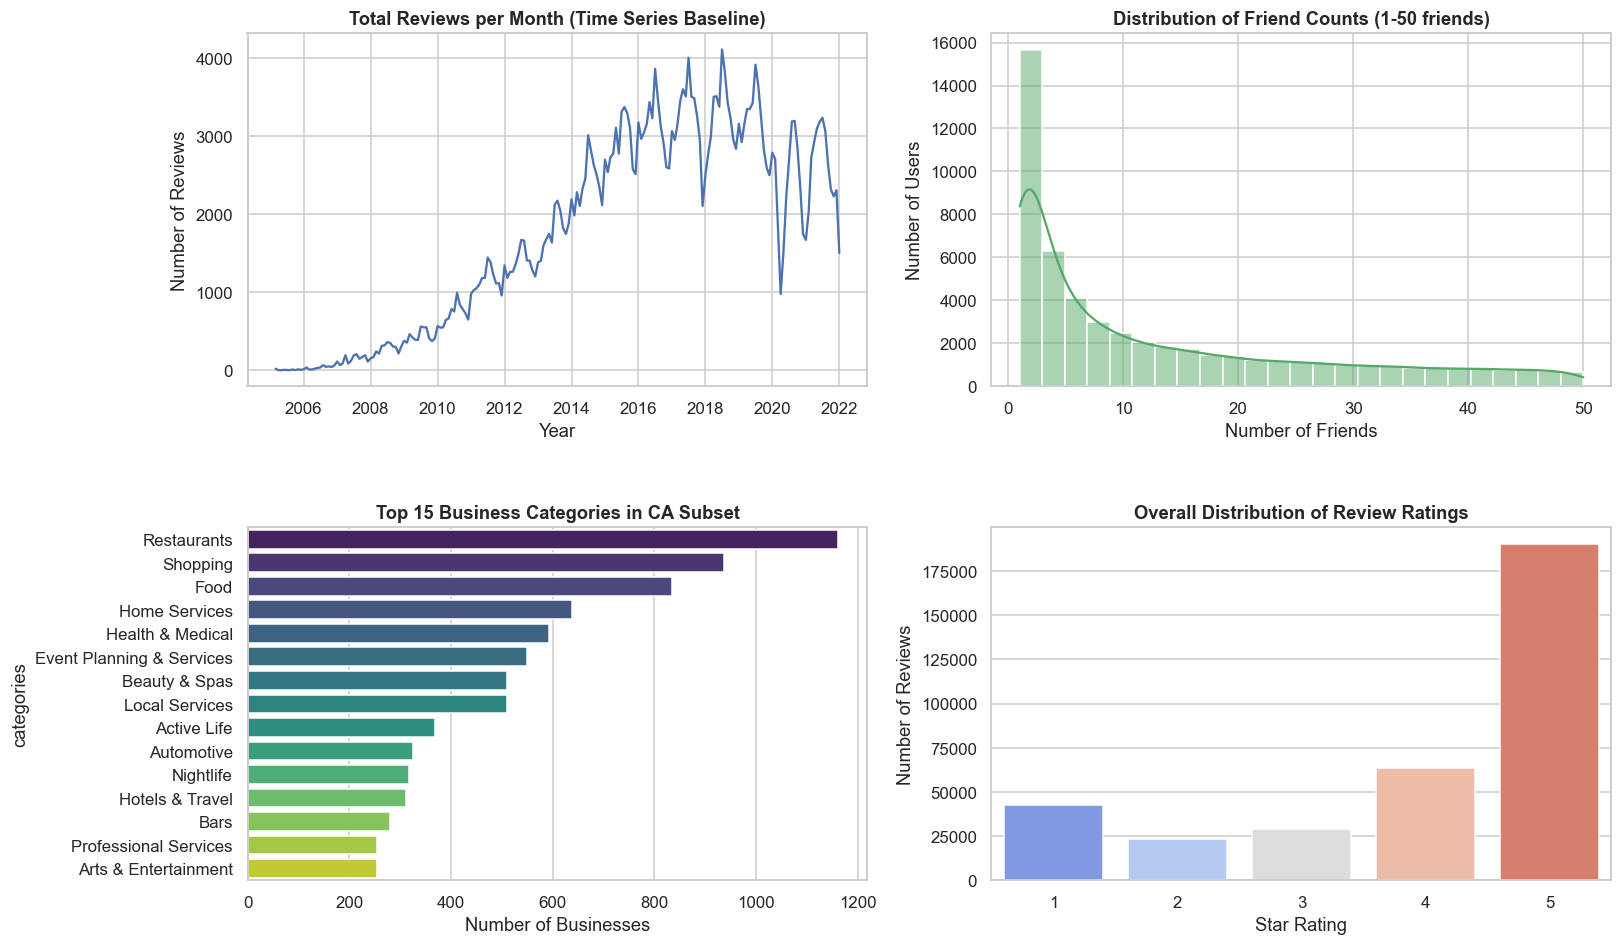


--- Network Data (SNA) Summary ---
Users with zero friends: 56,525
Users with 1+ friends: 99,423
Max friends a single user has: 14,995

--- Temporal Data (TS) Summary ---
First review date: 2005-03-01
Last review date: 2022-01-19


In [41]:
# Load the data
print("Loading Parquet files...")
ca_biz = pd.read_parquet("yelp_ca_business.parquet")
ca_reviews = pd.read_parquet("yelp_ca_review.parquet")
ca_users = pd.read_parquet("yelp_ca_user.parquet")

# Prepare temporal and network variables
ca_reviews['date'] = pd.to_datetime(ca_reviews['date'])
ca_reviews['year_month'] = ca_reviews['date'].dt.to_period('M')

# Count friends (handle "None" string by returning 0)
ca_users['friend_count'] = ca_users['friends'].apply(
    lambda x: 0 if x == 'None' else len(x.split(','))
)

# Set up the visual dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
plt.subplots_adjust(hspace=0.4, wspace=0.2)
sns.set_theme(style="whitegrid")

# Plot 1: Review Volume Over Time (TS Focus) ---
monthly_reviews = ca_reviews.groupby('year_month').size()
monthly_reviews.index = monthly_reviews.index.to_timestamp()
axes[0, 0].plot(monthly_reviews.index, monthly_reviews.values, color='b')
axes[0, 0].set_title("Total Reviews per Month (Time Series Baseline)")
axes[0, 0].set_ylabel("Number of Reviews")
axes[0, 0].set_xlabel("Year")

# Plot 2: User Friend Count Distribution (SNA Focus) ---
# Zooming in on users with 1 to 50 friends to see the distribution shape
subset_users = ca_users[(ca_users['friend_count'] > 0) & (ca_users['friend_count'] <= 50)]
sns.histplot(subset_users['friend_count'], bins=25, ax=axes[0, 1], color='g', kde=True)
axes[0, 1].set_title("Distribution of Friend Counts (1-50 friends)")
axes[0, 1].set_xlabel("Number of Friends")
axes[0, 1].set_ylabel("Number of Users")

# Plot 3: Top 15 Business Categories ---
# Categories are comma-separated strings; we need to explode them
categories = ca_biz['categories'].dropna().str.split(', ').explode()
top_cats = categories.value_counts().head(15)
sns.barplot(y=top_cats.index, x=top_cats.values, ax=axes[1, 0], palette="viridis")
axes[1, 0].set_title("Top 15 Business Categories in CA Subset")
axes[1, 0].set_xlabel("Number of Businesses")

# Plot 4: Distribution of Star Ratings ---
sns.countplot(data=ca_reviews, x='stars', ax=axes[1, 1], palette="coolwarm")
axes[1, 1].set_title("Overall Distribution of Review Ratings")
axes[1, 1].set_xlabel("Star Rating")
axes[1, 1].set_ylabel("Number of Reviews")

plt.show()

# Print summary statistics
print("\n--- Network Data (SNA) Summary ---")
print(f"Users with zero friends: {(ca_users['friend_count'] == 0).sum():,}")
print(f"Users with 1+ friends: {(ca_users['friend_count'] > 0).sum():,}")
print(f"Max friends a single user has: {ca_users['friend_count'].max():,}")

print("\n--- Temporal Data (TS) Summary ---")
print(f"First review date: {ca_reviews['date'].min().date()}")
print(f"Last review date: {ca_reviews['date'].max().date()}")

Loading Parquet files...


Processing temporal features...
Building network graph & calculating centrality...
Temporal Dynamics...


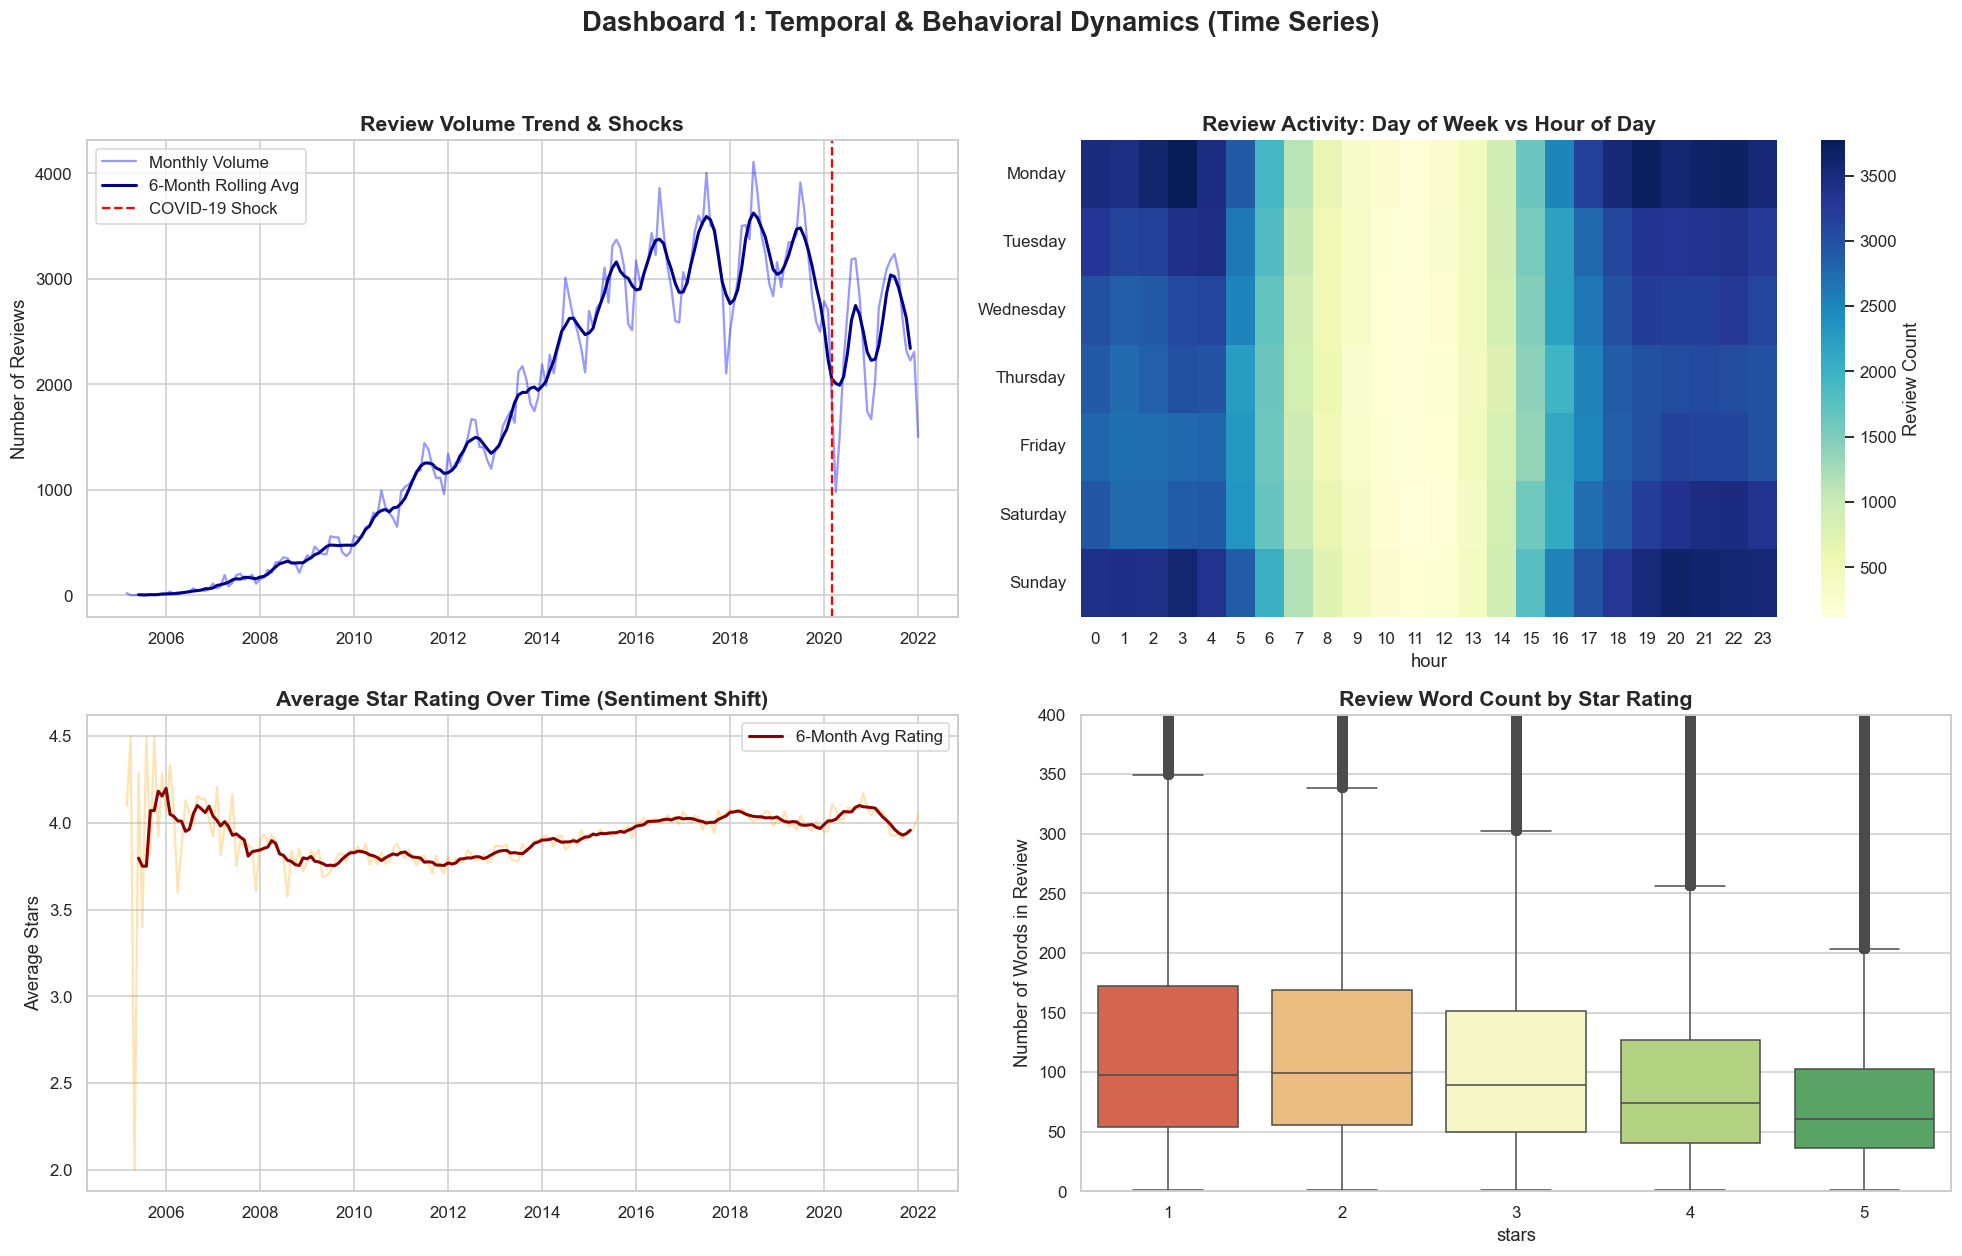

Network Topology...


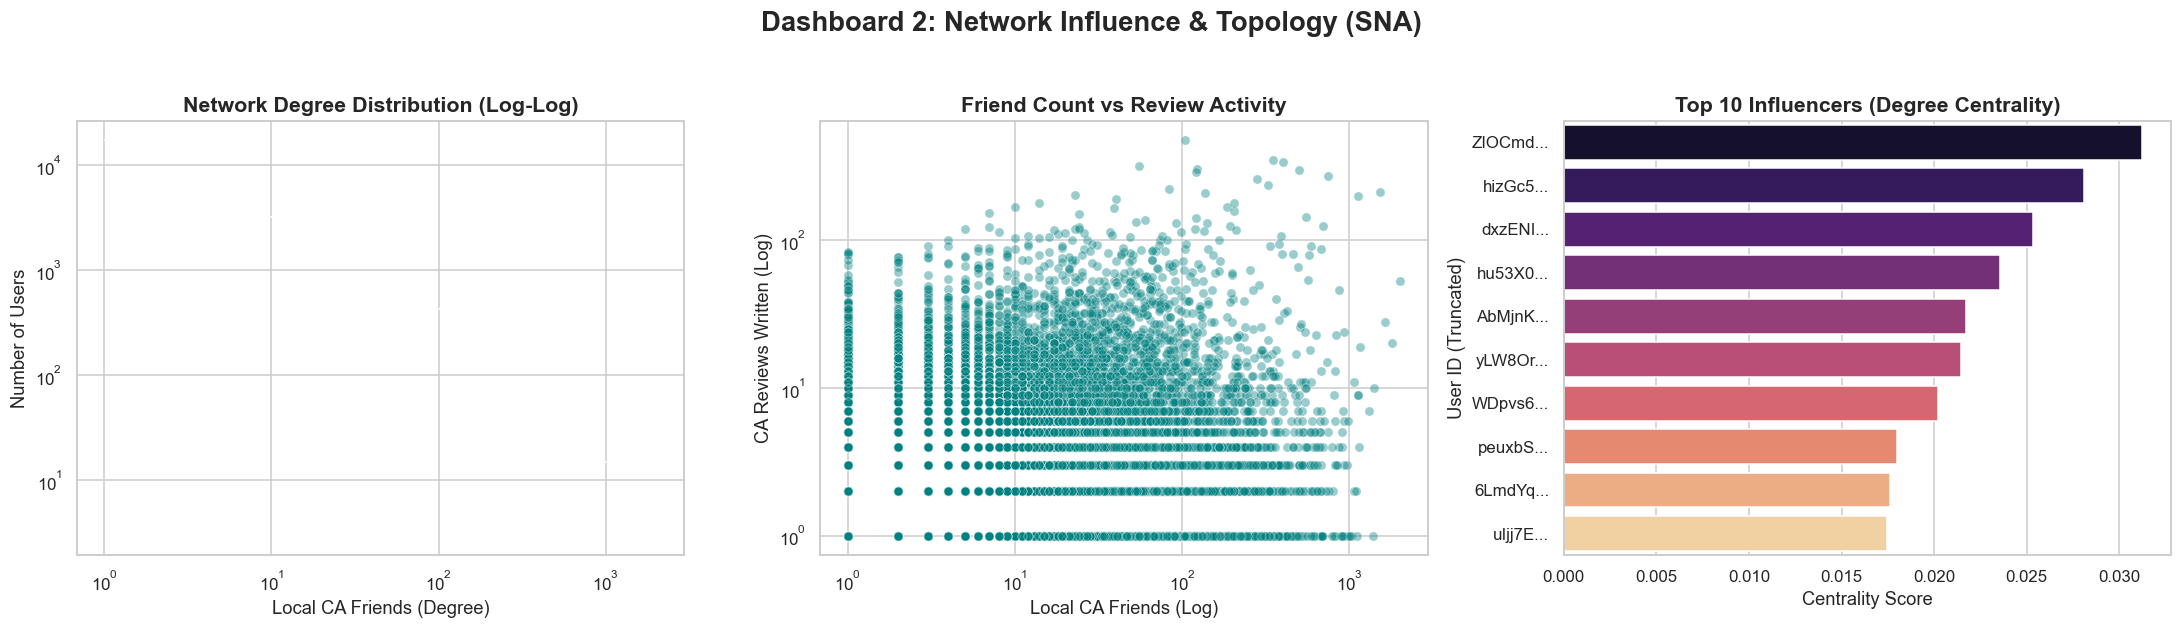

Business Analytics...


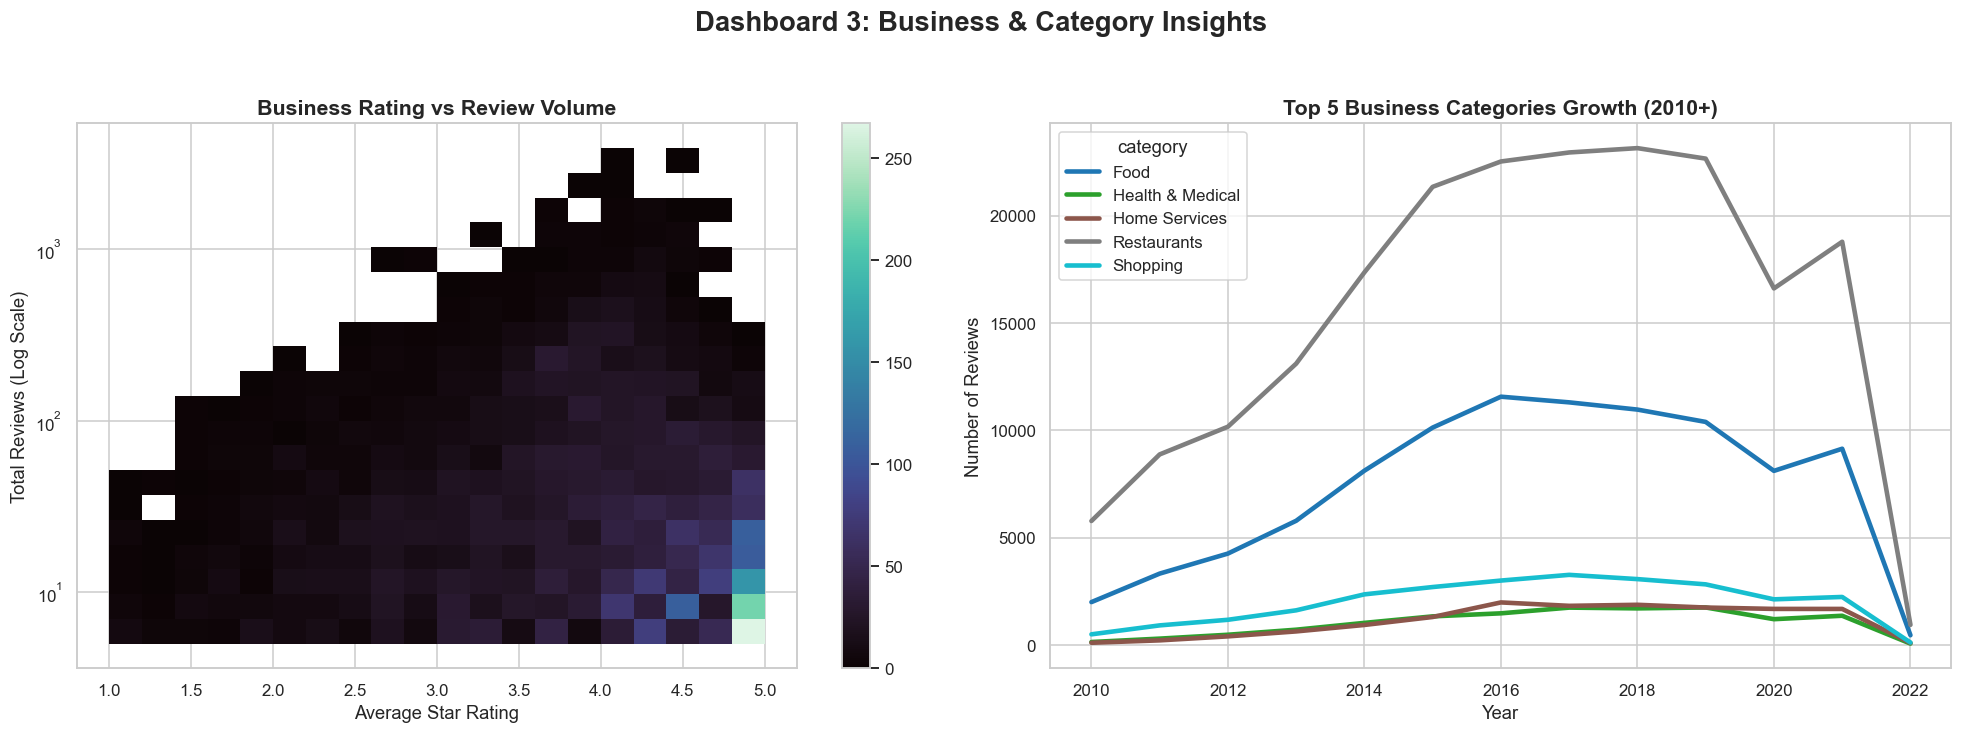


ADVANCED ANALYTICS SUMMARY
[SNA] Network Density: 0.000228
[SNA] Largest Connected Component: 62,053 nodes (96.3% of networked users)
[SNA] Isolated sub-networks (excluding main component): 1,096

[TS] Peak Review Month: 2018-07 with 4,109 reviews
[TS] COVID Impact: Volume dropped from 2704 (Feb 2020) to 978 (Apr 2020).
[TS] Most active day of the week: Monday

[Behavior] Angry Reviews (1-star) avg length: 136 words
[Behavior] Happy Reviews (5-star) avg length: 83 words

[Fusion] Correlation between local friends & review activity: 0.184


In [42]:
# Suppress minor warnings for a clean output
warnings.filterwarnings('ignore')

# ==========================================
print("Loading Parquet files...")
ca_biz = pd.read_parquet(os.path.join(target_path, "yelp_ca_business.parquet"))
ca_reviews = pd.read_parquet(os.path.join(target_path, "yelp_ca_review.parquet"))
ca_users = pd.read_parquet(os.path.join(target_path, "yelp_ca_user.parquet"))

print("Processing temporal features...")
ca_reviews['date'] = pd.to_datetime(ca_reviews['date'])
ca_reviews['year_month'] = ca_reviews['date'].dt.to_period('M')
ca_reviews['year'] = ca_reviews['date'].dt.year
ca_reviews['hour'] = ca_reviews['date'].dt.hour
ca_reviews['text_length'] = ca_reviews['text'].str.split().str.len()

# Categorical day of week for correct sorting on heatmaps
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
ca_reviews['day_of_week'] = pd.Categorical(ca_reviews['date'].dt.day_name(), categories=days, ordered=True)

print("Building network graph & calculating centrality...")
valid_uids = set(ca_users['user_id'])
edges = []
for _, row in ca_users[ca_users['friends'] != 'None'].iterrows():
    u1 = row['user_id']
    for u2 in [f.strip() for f in row['friends'].split(',')]:
        if u2 in valid_uids:
            edges.append((u1, u2))

G = nx.Graph()
G.add_edges_from(edges)

# Calculate network metrics natively
degree_centrality = nx.degree_centrality(G)
ca_users['degree_centrality'] = ca_users['user_id'].map(degree_centrality).fillna(0)
ca_users['local_friends_count'] = ca_users['user_id'].map(dict(G.degree())).fillna(0)

# Merge local review count cleanly to avoid the 'y' axis error
user_rev_counts = ca_reviews.groupby('user_id').size().reset_index(name='ca_review_count')
ca_users = ca_users.merge(user_rev_counts, on='user_id', how='left')
ca_users['ca_review_count'] = ca_users['ca_review_count'].fillna(0)

# Set visual style
sns.set_theme(style="whitegrid", palette="muted")

# ==========================================
print("Temporal Dynamics...")
fig1, axes1 = plt.subplots(2, 2, figsize=(18, 12))
fig1.suptitle('Dashboard 1: Temporal & Behavioral Dynamics (Time Series)', fontsize=18, fontweight='bold')

# 1A: Monthly Volume + Rolling Trend
monthly_vol = ca_reviews.groupby('year_month').size().to_timestamp()
rolling_vol = monthly_vol.rolling(window=6, center=True).mean()
axes1[0, 0].plot(monthly_vol.index, monthly_vol.values, alpha=0.4, label='Monthly Volume', color='blue')
axes1[0, 0].plot(rolling_vol.index, rolling_vol.values, color='darkblue', linewidth=2, label='6-Month Rolling Avg')
axes1[0, 0].axvline(pd.to_datetime('2020-03-01'), color='red', linestyle='--', label='COVID-19 Shock')
axes1[0, 0].set_title('Review Volume Trend & Shocks', fontsize=14)
axes1[0, 0].set_ylabel('Number of Reviews')
axes1[0, 0].legend()

# 1B: Heatmap: Day of Week vs Hour
time_heatmap = ca_reviews.groupby(['day_of_week', 'hour'], observed=True).size().unstack(fill_value=0)
sns.heatmap(time_heatmap, cmap='YlGnBu', ax=axes1[0, 1], cbar_kws={'label': 'Review Count'})
axes1[0, 1].set_title('Review Activity: Day of Week vs Hour of Day', fontsize=14)
axes1[0, 1].set_ylabel('')

# 1C: Sentiment Over Time
monthly_stars = ca_reviews.groupby('year_month')['stars'].mean().to_timestamp()
rolling_stars = monthly_stars.rolling(window=6, center=True).mean()
axes1[1, 0].plot(monthly_stars.index, monthly_stars.values, alpha=0.3, color='orange')
axes1[1, 0].plot(rolling_stars.index, rolling_stars.values, color='darkred', linewidth=2, label='6-Month Avg Rating')
axes1[1, 0].set_title('Average Star Rating Over Time (Sentiment Shift)', fontsize=14)
axes1[1, 0].set_ylabel('Average Stars')
axes1[1, 0].legend()

# 1D: Review Length by Star Rating
sns.boxplot(data=ca_reviews, x='stars', y='text_length', ax=axes1[1, 1], palette='RdYlGn')
axes1[1, 1].set_ylim(0, 400) # Cut off extreme outliers to see the median clearly
axes1[1, 1].set_title('Review Word Count by Star Rating', fontsize=14)
axes1[1, 1].set_ylabel('Number of Words in Review')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# ==========================================
print("Network Topology...")
fig2, axes2 = plt.subplots(1, 3, figsize=(20, 6))
fig2.suptitle('Dashboard 2: Network Influence & Topology (SNA)', fontsize=18, fontweight='bold')

# 2A: Degree Distribution
connected_users = ca_users[ca_users['local_friends_count'] > 0]
sns.histplot(connected_users['local_friends_count'], bins=30, log_scale=(True, True), ax=axes2[0], color='purple')
axes2[0].set_title('Network Degree Distribution (Log-Log)', fontsize=14)
axes2[0].set_xlabel('Local CA Friends (Degree)')
axes2[0].set_ylabel('Number of Users')

# 2B: Influence vs Activity Scatter
sns.scatterplot(data=connected_users[connected_users['ca_review_count'] > 0], 
                x='local_friends_count', y='ca_review_count', alpha=0.4, ax=axes2[1], color='teal')
axes2[1].set_xscale('log')
axes2[1].set_yscale('log')
axes2[1].set_title('Friend Count vs Review Activity', fontsize=14)
axes2[1].set_xlabel('Local CA Friends (Log)')
axes2[1].set_ylabel('CA Reviews Written (Log)')

# 2C: Top 10 Influential Users (By Centrality)
top_influencers = ca_users.sort_values(by='degree_centrality', ascending=False).head(10)
sns.barplot(data=top_influencers, x='degree_centrality', y='user_id', ax=axes2[2], palette='magma')
axes2[2].set_title('Top 10 Influencers (Degree Centrality)', fontsize=14)
axes2[2].set_ylabel('User ID (Truncated)')
axes2[2].set_xlabel('Centrality Score')
axes2[2].set_yticklabels([uid[:6]+'...' for uid in top_influencers['user_id']])

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# ==========================================
# DASHBOARD 3: Business Analytics Integration
# ==========================================
print("Business Analytics...")
fig3, axes3 = plt.subplots(1, 2, figsize=(18, 7))
fig3.suptitle('Dashboard 3: Business & Category Insights', fontsize=18, fontweight='bold')

# 3A: Business Review Volume vs Average Rating
biz_metrics = ca_reviews.groupby('business_id').agg(
    avg_rating=('stars', 'mean'),
    review_vol=('business_id', 'count')
).reset_index()
sns.histplot(data=biz_metrics, x='avg_rating', y='review_vol', bins=20, log_scale=(False, True), cmap='mako', cbar=True, ax=axes3[0])
axes3[0].set_title('Business Rating vs Review Volume', fontsize=14)
axes3[0].set_xlabel('Average Star Rating')
axes3[0].set_ylabel('Total Reviews (Log Scale)')

# 3B: Top Categories Over Time
# Explode categories to track trends
biz_cats = ca_biz[['business_id', 'categories']].dropna()
biz_cats['category'] = biz_cats['categories'].str.split(', ')
biz_cats_exploded = biz_cats.explode('category')
top_5_cats = biz_cats_exploded['category'].value_counts().head(5).index.tolist()

cat_reviews = ca_reviews[['business_id', 'year']].merge(biz_cats_exploded, on='business_id', how='inner')
cat_reviews_top5 = cat_reviews[cat_reviews['category'].isin(top_5_cats)]
cat_yearly = cat_reviews_top5.groupby(['year', 'category']).size().unstack(fill_value=0)

# Filter for 2010+ to remove early low-data noise
cat_yearly = cat_yearly[cat_yearly.index >= 2010]
cat_yearly.plot(kind='line', linewidth=3, ax=axes3[1], cmap='tab10')
axes3[1].set_title('Top 5 Business Categories Growth (2010+)', fontsize=14)
axes3[1].set_ylabel('Number of Reviews')
axes3[1].set_xlabel('Year')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# ==========================================
# ADVANCED ANALYTICS PRINTOUTS
# ==========================================
print("\n" + "="*50)
print("ADVANCED ANALYTICS SUMMARY")
print("="*50)

# Network Diagnostics
density = nx.density(G)
if len(G) > 0:
    components = sorted(nx.connected_components(G), key=len, reverse=True)
    lcc_size = len(components[0])
    print(f"[SNA] Network Density: {density:.6f}")
    print(f"[SNA] Largest Connected Component: {lcc_size:,} nodes ({(lcc_size/len(G))*100:.1f}% of networked users)")
    print(f"[SNA] Isolated sub-networks (excluding main component): {len(components)-1:,}")

# Temporal Diagnostics
print(f"\n[TS] Peak Review Month: {monthly_vol.idxmax().strftime('%Y-%m')} with {monthly_vol.max():,} reviews")
try:
    print(f"[TS] COVID Impact: Volume dropped from {monthly_vol['2020-02-01']} (Feb 2020) to {monthly_vol['2020-04-01']} (Apr 2020).")
except KeyError:
    pass
print(f"[TS] Most active day of the week: {ca_reviews['day_of_week'].value_counts().idxmax()}")

# Behavioral Diagnostics
print(f"\n[Behavior] Angry Reviews (1-star) avg length: {ca_reviews[ca_reviews['stars']==1]['text_length'].mean():.0f} words")
print(f"[Behavior] Happy Reviews (5-star) avg length: {ca_reviews[ca_reviews['stars']==5]['text_length'].mean():.0f} words")

corr = ca_users['local_friends_count'].corr(ca_users['ca_review_count'])
print(f"\n[Fusion] Correlation between local friends & review activity: {corr:.3f}")
print("="*50)

## DESCRIPTIVES 

All  earlier plots are organised around what the forecasting stage needs (volume with rolling trend and COVID marker, rating over time, review length, degree distribution, friends vs activity, top influencers, categories) below.

**Structure**
1. **Setup & cleaning**: parameters, geography clean-up, enriched user / business / review attributes
2. **Descriptive overview**: dataset summary, data quality, heavy-tail structure
3. **Time-series diagnostics** (week-1 lifecycle): analysis window, volume drivers, seasonality, STL decomposition, variance/transformation check, stationarity tests, ACF/PACF, rating dynamics, category/city series, check-ins as a possible exogenous variable
4. **Network analysis** (week-4 concepts): graph statistics, centrality, assortativity/homophily, Louvain communities
5. **Network × time**: community-level time series, degree-segment series, friend-exposure feasibility check
6. **Export**: tidy tables for the modelling stage

Extra packages: `pip install statsmodels pyarrow` (and `networkx >= 2.8` for Louvain).

## 1. Setup, parameters & cleaning

In [43]:
import numpy as np
from collections import defaultdict
from scipy import stats
from IPython.display import display
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from networkx.algorithms.community import louvain_communities, modularity

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.titleweight': 'bold'})

target_path = globals().get('target_path', os.getcwd())

# ---------------- parameters (edit here) ----------------
CLEAN_GEOGRAPHY   = True   # drop cities with very few businesses (Truckee, Reno, Sparks, ...)
MIN_BIZ_PER_CITY  = 20
COVID_START       = pd.Timestamp('2020-03-01')
MIN_MONTHLY       = 100    # analysis window starts when monthly volume is reliably >= this
SEED              = 42
TOP_K             = 10     # number of communities inspected as time series
LOUVAIN_RESOLUTION = 1.0
MIN_MEDIAN_MONTHLY = 30    # a community series is 'forecastable' if its median month has >= this many reviews
N_PERM            = 3      # permutations for the friend-exposure null model
CITY_FOCUS        = None   # None = whole subset; or e.g. 'Santa Barbara' / 'Goleta' to restrict EVERYTHING below to one city

# ---------------- load ----------------
ca_biz     = pd.read_parquet(os.path.join(target_path, "yelp_ca_business.parquet"))
ca_reviews = pd.read_parquet(os.path.join(target_path, "yelp_ca_review.parquet"))
ca_users   = pd.read_parquet(os.path.join(target_path, "yelp_ca_user.parquet"))
n_before = (len(ca_biz), len(ca_reviews), len(ca_users))

# ---------------- geography clean-up ----------------
# city names contain typos / case variants ("Santa Barbra", "santa Barbara")
ca_biz['city'] = ca_biz['city'].str.strip().str.title().replace({'Santa Barbra': 'Santa Barbara'})
if CLEAN_GEOGRAPHY:
    city_counts = ca_biz['city'].value_counts()
    dropped = city_counts[city_counts < MIN_BIZ_PER_CITY]
    ca_biz = ca_biz[ca_biz['city'].isin(city_counts[city_counts >= MIN_BIZ_PER_CITY].index)].copy()
    ca_reviews = ca_reviews[ca_reviews['business_id'].isin(set(ca_biz['business_id']))].copy()
    ca_users = ca_users[ca_users['user_id'].isin(set(ca_reviews['user_id']))].copy()
    print(f"Dropped {len(dropped)} out-of-area cities ({int(dropped.sum())} businesses): { {k: int(v) for k, v in dropped.items()} }")
print(f"Businesses {n_before[0]:,} -> {len(ca_biz):,} | Reviews {n_before[1]:,} -> {len(ca_reviews):,} | Users {n_before[2]:,} -> {len(ca_users):,}")
if CITY_FOCUS:   # single-city analysis: keep that city's businesses, their reviews and the reviewing users
    assert CITY_FOCUS in set(ca_biz['city']), f"CITY_FOCUS must be one of {sorted(set(ca_biz['city']))}"
    ca_biz = ca_biz[ca_biz['city'] == CITY_FOCUS].copy()
    ca_reviews = ca_reviews[ca_reviews['business_id'].isin(set(ca_biz['business_id']))].copy()
    ca_users = ca_users[ca_users['user_id'].isin(set(ca_reviews['user_id']))].copy()
    print(f"CITY_FOCUS = {CITY_FOCUS!r}: Businesses {len(ca_biz):,} | Reviews {len(ca_reviews):,} | Users {len(ca_users):,}")

# ---------------- business attributes: one macro-category per business ----------------
MACRO_PRIORITY = [
    ('Hotels & Travel',      {'Hotels & Travel', 'Hotels', 'Bed & Breakfast', 'Tours', 'Vacation Rentals'}),
    ('Nightlife & Bars',     {'Nightlife', 'Bars', 'Breweries', 'Wine Bars', 'Pubs', 'Beer', 'Wine & Spirits'}),
    ('Restaurants',          {'Restaurants'}),
    ('Food (other)',         {'Food', 'Coffee & Tea', 'Bakeries', 'Desserts', 'Ice Cream & Frozen Yogurt', 'Juice Bars & Smoothies', 'Grocery'}),
    ('Beauty & Spas',        {'Beauty & Spas', 'Hair Salons', 'Nail Salons', 'Massage', 'Day Spas'}),
    ('Health & Medical',     {'Health & Medical', 'Doctors', 'Dentists'}),
    ('Arts & Entertainment', {'Arts & Entertainment', 'Museums', 'Performing Arts', 'Music Venues'}),
    ('Active Life',          {'Active Life', 'Fitness & Instruction', 'Gyms', 'Parks', 'Yoga'}),
    ('Shopping',             {'Shopping', 'Fashion', 'Home & Garden'}),
    ('Automotive',           {'Automotive', 'Auto Repair'}),
    ('Home & Local Services',{'Home Services', 'Local Services', 'Real Estate', 'Professional Services'}),
]
def macro_cat(cats):
    if not isinstance(cats, str): return 'Unknown'
    s = set(cats.split(', '))
    for name, keys in MACRO_PRIORITY:
        if s & keys: return name
    return 'Other'
ca_biz['macro_cat'] = ca_biz['categories'].apply(macro_cat)

# ---------------- review attributes ----------------
ca_reviews['date']  = pd.to_datetime(ca_reviews['date'])
ca_reviews['month'] = ca_reviews['date'].dt.to_period('M').dt.to_timestamp()
ca_reviews['year']  = ca_reviews['date'].dt.year
ca_reviews['dow']   = ca_reviews['date'].dt.dayofweek
ca_reviews['hour']  = ca_reviews['date'].dt.hour
ca_reviews['text_length'] = ca_reviews['text'].str.split().str.len()
ca_reviews = ca_reviews.merge(ca_biz[['business_id', 'city', 'macro_cat']], on='business_id', how='left')

# ---------------- user attributes ----------------
ca_users['yelping_since'] = pd.to_datetime(ca_users['yelping_since'])
ca_users['join_year']     = ca_users['yelping_since'].dt.year
ca_users['friend_count_all'] = ca_users['friends'].apply(lambda x: 0 if x in ('None', '') else x.count(',') + 1)
ca_users['n_elite_years'] = ca_users['elite'].fillna('').apply(lambda x: 0 if x == '' else len(x.split(',')))
ca_users['is_elite_ever'] = ca_users['n_elite_years'] > 0

# activity inside our CA subset
ua = ca_reviews.groupby('user_id').agg(ca_review_count=('review_id', 'size'),
                                       first_ca_review=('date', 'min'),
                                       last_ca_review=('date', 'max'))
ca_users = ca_users.merge(ua, on='user_id', how='left')
ca_users['ca_span_days'] = (ca_users['last_ca_review'] - ca_users['first_ca_review']).dt.days
# visitor-like = at most 2 reviews, all within 30 days (typical of tourists)
ca_users['visitor_like'] = (ca_users['ca_review_count'] <= 2) & (ca_users['ca_span_days'] <= 30)

# was the reviewer Elite in the year of the review?  (Yelp stores 2020 as "20,20" in some rows)
el = ca_users.loc[ca_users['elite'].fillna('') != '', ['user_id', 'elite']].copy()
el['year'] = el['elite'].str.split(',')
el = el.explode('year')
el['year'] = pd.to_numeric(el['year'], errors='coerce')
el['year'] = np.where(el['year'] < 100, el['year'] + 2000, el['year'])
el = el.dropna(subset=['year'])
el['year'] = el['year'].astype(int)
el = el[['user_id', 'year']].drop_duplicates().assign(is_elite_at_review=True)
ca_reviews = ca_reviews.merge(el, on=['user_id', 'year'], how='left')
ca_reviews['is_elite_at_review'] = ca_reviews['is_elite_at_review'].eq(True)

print("\nBusiness macro-categories (share of businesses):")
print(ca_biz['macro_cat'].value_counts(normalize=True).round(3).to_string())

Dropped 28 out-of-area cities (40 businesses): {'Truckee': 11, 'Reno': 3, 'Port Hueneme': 1, 'Ventura': 1, 'Santa Ynez': 1, 'Sparks': 1, 'Kings Beach': 1, 'Mission Canyon': 1, 'Los Angeles': 1, 'Tampa': 1, 'Oxnard': 1, 'West Hill': 1, 'Cerritos': 1, 'Eagle': 1, 'Meridian': 1, 'Santa Clara': 1, 'Valencia': 1, 'Real Goleta': 1, 'Santa Barbara,': 1, 'Spring Hill': 1, 'Aliso Viejo': 1, 'Santa Barbara Ap': 1, 'South Lake Tahoe': 1, 'Santa Barbara & Ventura Counties': 1, 'Costa Mesa': 1, 'Santa  Barbara': 1, 'Salinas': 1, 'Santa Maria': 1}
Businesses 5,203 -> 5,163 | Reviews 348,856 -> 347,867 | Users 155,948 -> 155,224

Business macro-categories (share of businesses):
macro_cat
Restaurants              0.175
Home & Local Services    0.140
Shopping                 0.123
Beauty & Spas            0.096
Health & Medical         0.087
Nightlife & Bars         0.077
Other                    0.062
Food (other)             0.059
Hotels & Travel          0.059
Automotive               0.053
Active L

## 2. Descriptive overview

In [44]:
rpu = ca_reviews.groupby('user_id').size()
rpb = ca_reviews.groupby('business_id').size()
last_date = ca_reviews['date'].max()

overview = pd.Series({
    'Businesses': f"{len(ca_biz):,}",
    'Cities': ca_biz['city'].nunique(),
    'Reviews': f"{len(ca_reviews):,}",
    'Users': f"{len(ca_users):,}",
    'First review': ca_reviews['date'].min().date(),
    'Last review': last_date.date(),
    'Calendar months covered': ca_reviews['month'].nunique(),
    'Open businesses (%)': round(ca_biz['is_open'].mean() * 100, 1),
    'Mean review stars': round(ca_reviews['stars'].mean(), 2),
    'Reviews per business (median / mean / max)': f"{rpb.median():.0f} / {rpb.mean():.1f} / {rpb.max():,}",
    'Reviews per user (median / mean / max)': f"{rpu.median():.0f} / {rpu.mean():.2f} / {rpu.max():,}",
    'Users with a single CA review (%)': round((rpu == 1).mean() * 100, 1),
    'Visitor-like users (<=2 reviews within 30 days) (%)': round(ca_users['visitor_like'].mean() * 100, 1),
    'Users ever Elite (%)': round(ca_users['is_elite_ever'].mean() * 100, 1),
    'Share of reviews written while Elite (%)': round(ca_reviews['is_elite_at_review'].mean() * 100, 1),
    'Top 1% of users write (% of reviews)': round(rpu.sort_values(ascending=False).head(int(len(rpu) * .01)).sum() / rpu.sum() * 100, 1),
    'Top 10% of users write (% of reviews)': round(rpu.sort_values(ascending=False).head(int(len(rpu) * .10)).sum() / rpu.sum() * 100, 1),
}, name='value')
display(overview.to_frame())

print("\n--- Data quality ---")
dq = pd.DataFrame({
    'missing_%': {'business.categories': ca_biz['categories'].isna().mean() * 100,
                  'business.attributes': ca_biz['attributes'].isna().mean() * 100,
                  'business.hours': ca_biz['hours'].isna().mean() * 100,
                  'review.text': ca_reviews['text'].isna().mean() * 100,
                  'user.friends == "None"': (ca_users['friends'] == 'None').mean() * 100},
}).round(1)
display(dq)
print(f"Duplicate review_ids: {ca_reviews['review_id'].duplicated().sum()} | "
      f"reviews in the last calendar month ({last_date:%Y-%m}, ends on day {last_date.day}): {(ca_reviews['month'] == last_date.to_period('M').start_time).sum():,}")

print("\n--- Reviews by city ---")
display(ca_reviews.groupby('city').agg(reviews=('review_id', 'size'), businesses=('business_id', 'nunique'),
                                       mean_stars=('stars', 'mean')).sort_values('reviews', ascending=False).round(2))
print("\n--- Numeric summaries ---")
display(ca_reviews[['stars', 'useful', 'funny', 'cool', 'text_length']].describe().T.round(2))
display(ca_users[['review_count', 'ca_review_count', 'friend_count_all', 'fans', 'average_stars', 'n_elite_years']].describe().T.round(2))

,value
Businesses,"5,163"
Cities,6
Reviews,"347,867"
Users,"155,224"
First review,2005-03-01
Last review,2022-01-19
Calendar months covered,203
Open businesses (%),78.1
Mean review stars,3.96
Reviews per business (median / mean / max),"20 / 67.4 / 3,889"



--- Data quality ---


,missing_%
business.categories,0.0
business.attributes,10.2
business.hours,17.3
review.text,0.0
"user.friends == ""None""",36.2


Duplicate review_ids: 0 | reviews in the last calendar month (2022-01, ends on day 19): 1,499

--- Reviews by city ---


,reviews,businesses,mean_stars
city,,,
Santa Barbara,269790,3838,4.00
Goleta,45643,798,3.76
Carpinteria,17391,299,3.89
Isla Vista,7583,94,3.76
Montecito,5042,93,4.03
Summerland,2418,41,3.99



--- Numeric summaries ---


,count,mean,std,min,25%,50%,75%,max
stars,347867.0,3.96,1.41,1.0,3.0,5.0,5.0,5.0
useful,347867.0,1.16,3.75,0.0,0.0,0.0,1.0,207.0
funny,347867.0,0.40,2.13,-1.0,0.0,0.0,0.0,134.0
cool,347867.0,0.56,3.08,0.0,0.0,0.0,0.0,184.0
text_length,347867.0,98.29,91.98,1.0,40.0,71.0,124.0,1027.0


,count,mean,std,min,25%,50%,75%,max
review_count,155224.0,50.57,158.96,0.0,4.00,12.0,37.00,17473.0
ca_review_count,155224.0,2.24,5.31,1.0,1.00,1.0,2.00,475.0
friend_count_all,155224.0,81.86,241.37,0.0,0.00,4.0,72.00,14995.0
fans,155224.0,4.20,33.37,0.0,0.00,0.0,1.00,3642.0
average_stars,155224.0,3.90,0.91,1.0,3.49,4.0,4.56,5.0
n_elite_years,155224.0,0.40,1.63,0.0,0.00,0.0,0.00,17.0


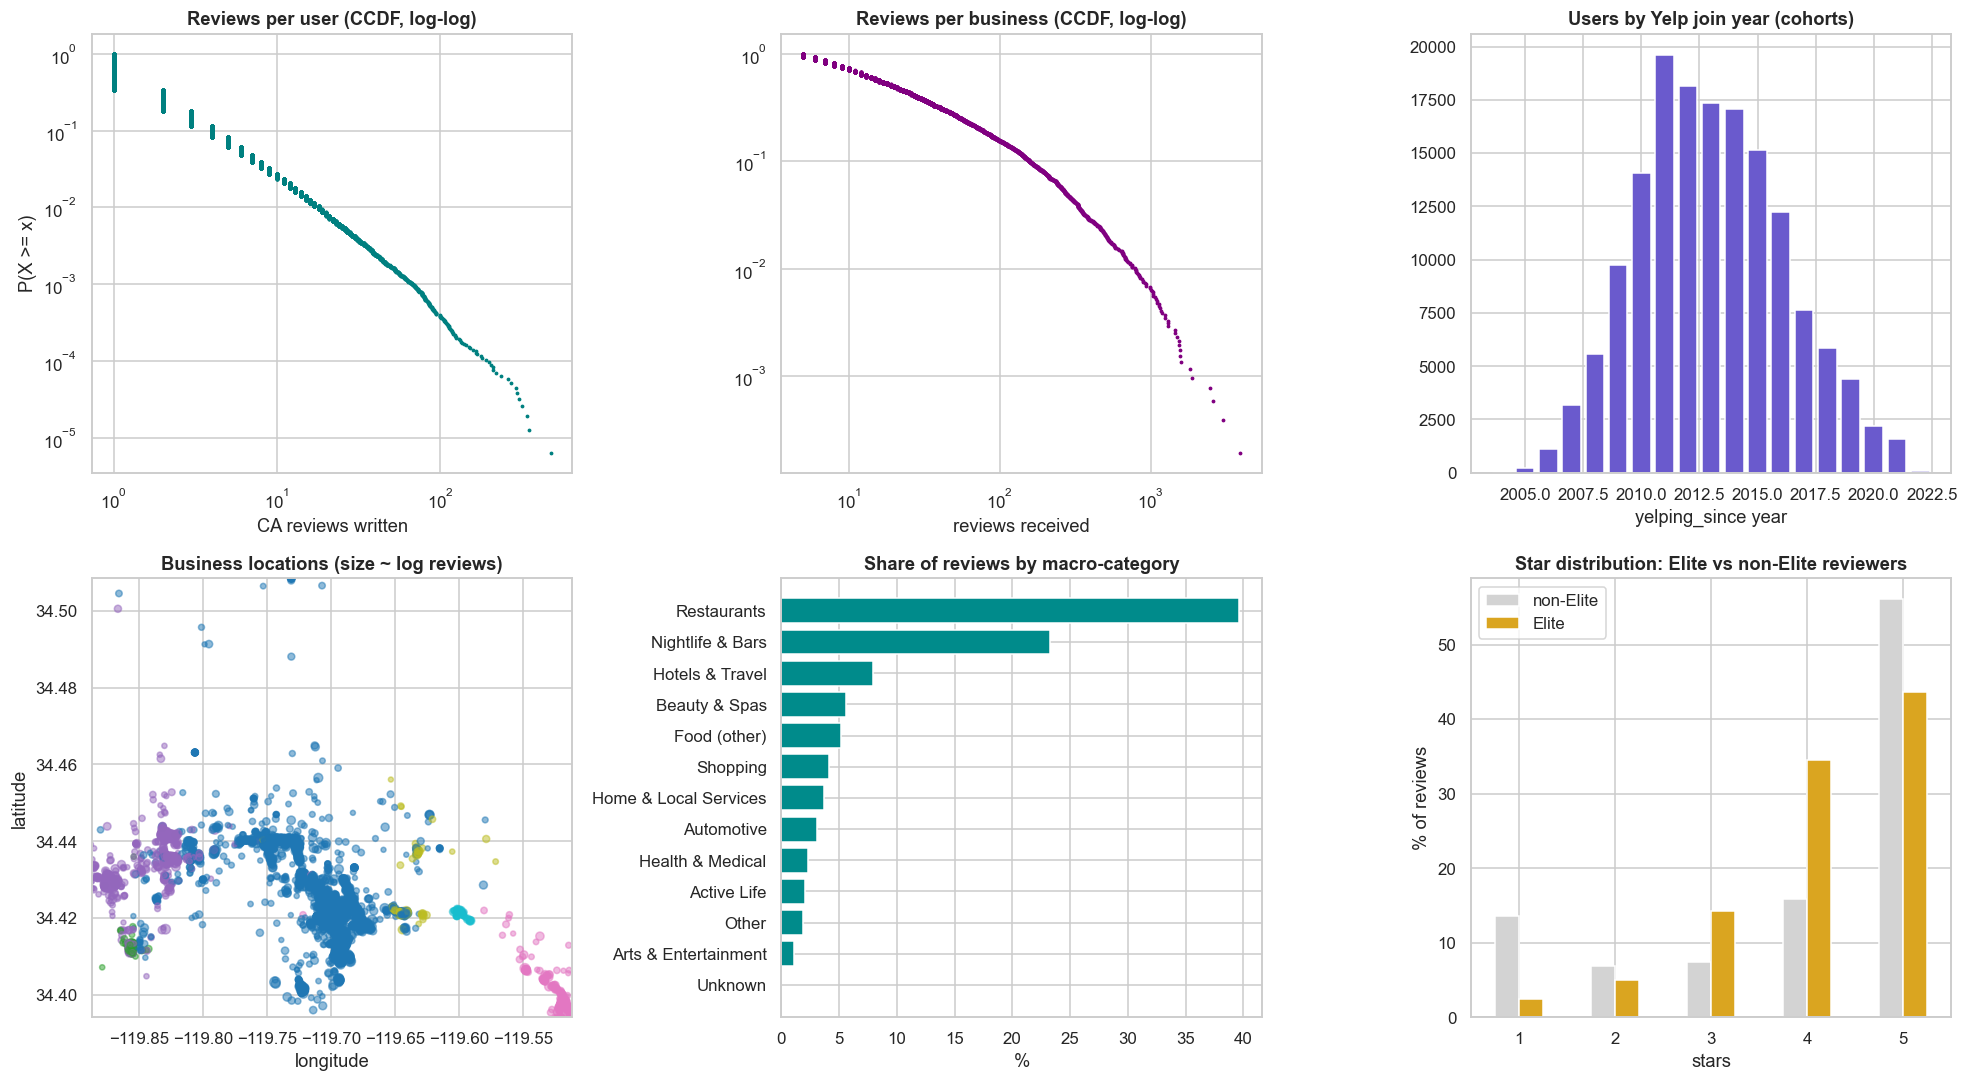

In [45]:
def ccdf(values):
    x = np.sort(np.asarray(values)); y = 1 - np.arange(len(x)) / len(x)
    return x, y

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# (a) reviews per user: heavy tail
x, yv = ccdf(rpu.values)
axes[0, 0].loglog(x, yv, '.', ms=3, color='teal')
axes[0, 0].set_title('Reviews per user (CCDF, log-log)'); axes[0, 0].set_xlabel('CA reviews written'); axes[0, 0].set_ylabel('P(X >= x)')

# (b) reviews per business
x, yv = ccdf(rpb.values)
axes[0, 1].loglog(x, yv, '.', ms=3, color='purple')
axes[0, 1].set_title('Reviews per business (CCDF, log-log)'); axes[0, 1].set_xlabel('reviews received')

# (c) user cohorts
coh = ca_users['join_year'].value_counts().sort_index()
axes[0, 2].bar(coh.index, coh.values, color='slateblue')
axes[0, 2].set_title('Users by Yelp join year (cohorts)'); axes[0, 2].set_xlabel('yelping_since year')

# (d) geography
sc = axes[1, 0].scatter(ca_biz['longitude'], ca_biz['latitude'], s=np.log1p(ca_biz['review_count']) * 6,
                        c=pd.factorize(ca_biz['city'])[0], cmap='tab10', alpha=.5)
axes[1, 0].set_title('Business locations (size ~ log reviews)'); axes[1, 0].set_xlabel('longitude'); axes[1, 0].set_ylabel('latitude')
axes[1, 0].set_xlim(ca_biz['longitude'].quantile([.005, .995])); axes[1, 0].set_ylim(ca_biz['latitude'].quantile([.005, .995]))

# (e) macro-categories: share of reviews
mc = ca_reviews['macro_cat'].value_counts(normalize=True).sort_values()
axes[1, 1].barh(mc.index, mc.values * 100, color='darkcyan'); axes[1, 1].set_title('Share of reviews by macro-category'); axes[1, 1].set_xlabel('%')

# (f) star distribution by Elite status
tmp = ca_reviews.groupby(['is_elite_at_review', 'stars']).size().unstack(0)
(tmp / tmp.sum() * 100).plot(kind='bar', ax=axes[1, 2], color=['lightgray', 'goldenrod'])
axes[1, 2].set_title('Star distribution: Elite vs non-Elite reviewers'); axes[1, 2].set_ylabel('% of reviews')
axes[1, 2].legend(['non-Elite', 'Elite']); axes[1, 2].tick_params(axis='x', rotation=0)

plt.tight_layout(); plt.show()

## 3. Time-series diagnostics

Following the lifecycle in the week-1 slides: **plot first -> decompose -> check stationarity -> choose adjustments / differencing -> only then model.**
The window below drops the sparse early years and the partial last month, because forecasting needs a stable series (slide: *numerical information about the past* that continues).

Analysis window : 2007-06 -> 2021-12  (175 months)
  excluded early : 27 months / 1,046 reviews (volume < 100/month)
  excluded tail  : partial month 2022-01
  pre-COVID      : 153 months   |   COVID & after: 22 months
  peak month     : 2018-07 (4,099)   |   pre-COVID Feb 2020 -> Apr 2020 : 2699 -> 976


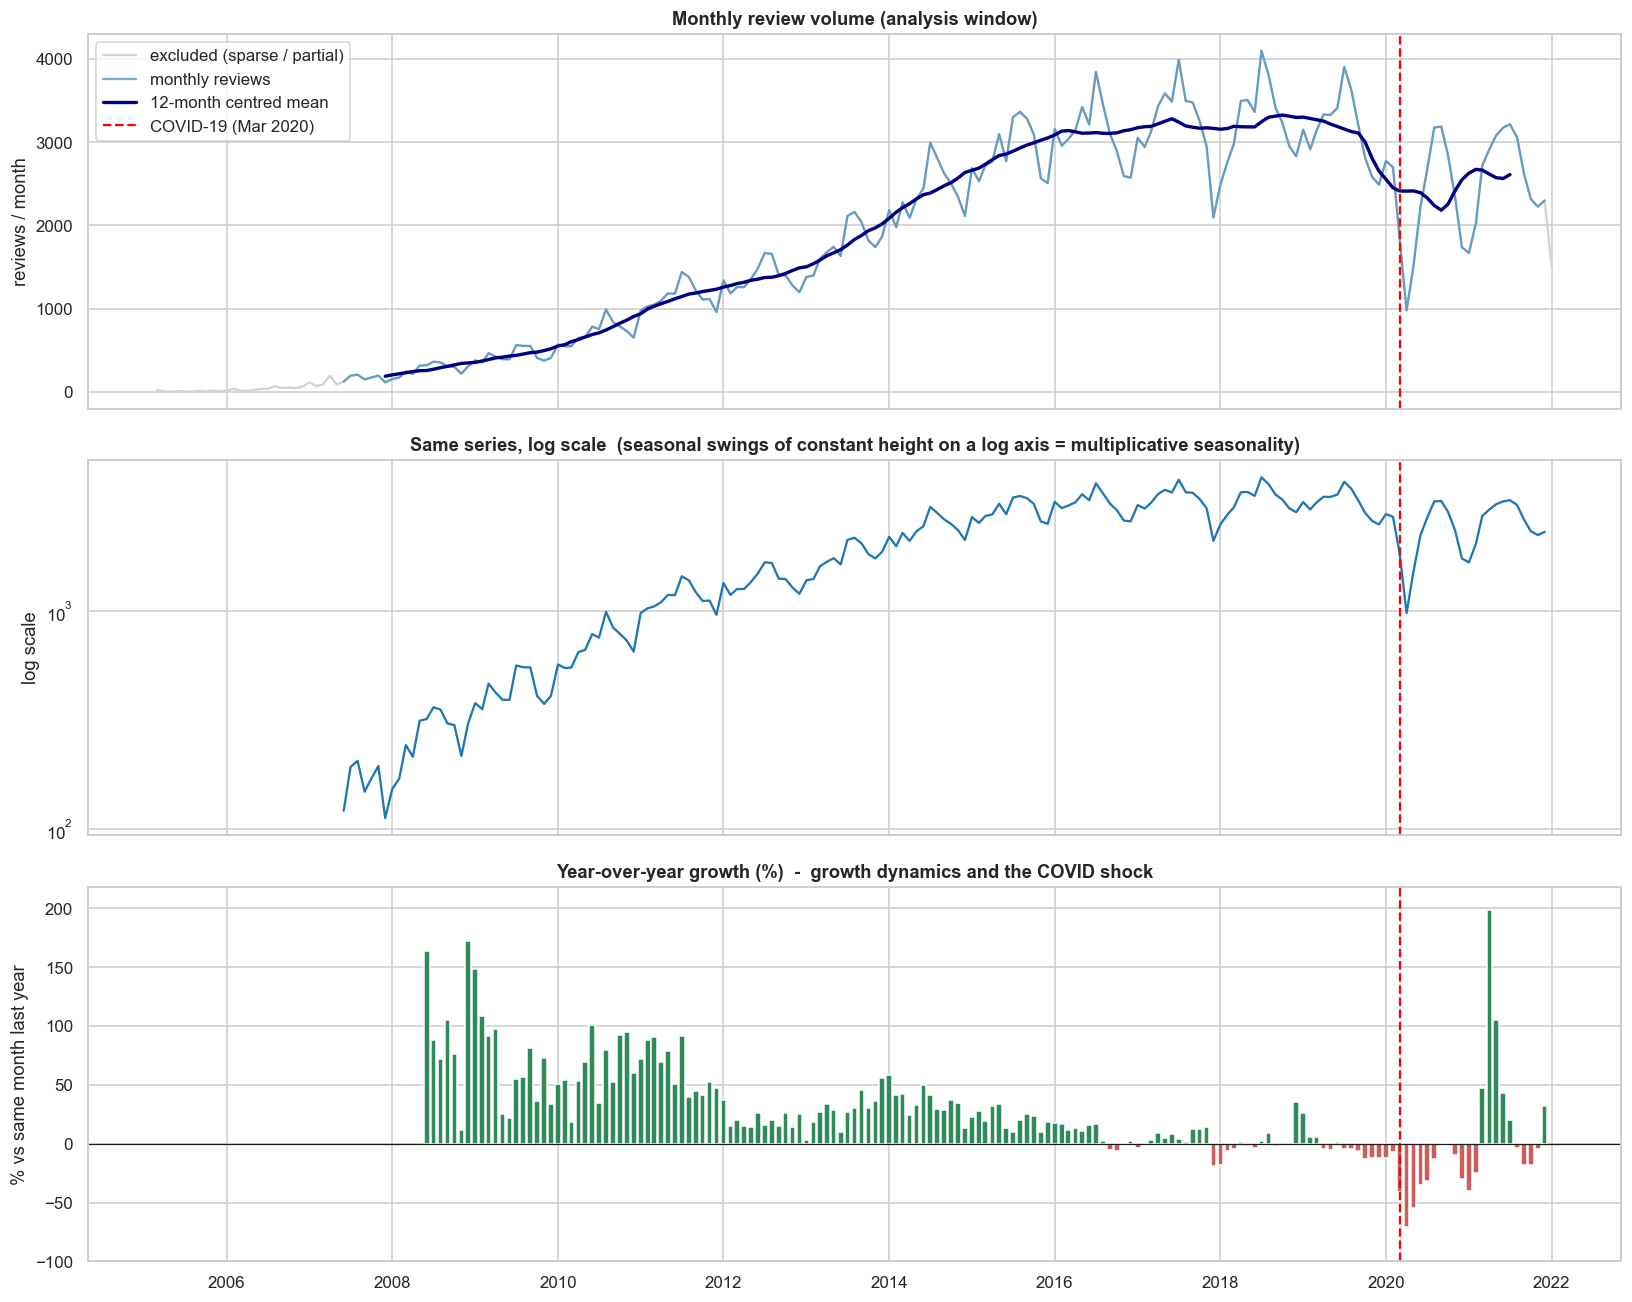

In [46]:
# ---------- monthly series & analysis window ----------
monthly_all = ca_reviews.groupby('month').size()
monthly_all = monthly_all.reindex(pd.date_range(monthly_all.index.min(), monthly_all.index.max(), freq='MS'), fill_value=0)

partial_last = last_date.normalize() < last_date.to_period('M').end_time.normalize()
TS_END = monthly_all.index[-2] if partial_last else monthly_all.index[-1]
ok = monthly_all.rolling(6).min() >= MIN_MONTHLY
TS_START = ok.idxmax() - pd.DateOffset(months=5) if ok.any() else monthly_all.index[0]

y = monthly_all.loc[TS_START:TS_END].asfreq('MS').astype(float)
y.name = 'reviews'
y_pre = y.loc[:COVID_START - pd.DateOffset(months=1)]     # pre-COVID window used for model diagnostics
BASE = y_pre.iloc[-12:]                                    # last 12 pre-COVID months = baseline for 'index' plots

print(f"Analysis window : {TS_START:%Y-%m} -> {TS_END:%Y-%m}  ({len(y)} months)")
print(f"  excluded early : {(monthly_all.index < TS_START).sum()} months / {int(monthly_all[monthly_all.index < TS_START].sum()):,} reviews (volume < {MIN_MONTHLY}/month)")
print(f"  excluded tail  : {'partial month ' + format(monthly_all.index[-1], '%Y-%m') if partial_last else 'none'}")
print(f"  pre-COVID      : {len(y_pre)} months   |   COVID & after: {len(y) - len(y_pre)} months")
print(f"  peak month     : {y.idxmax():%Y-%m} ({int(y.max()):,})   |   pre-COVID Feb 2020 -> Apr 2020 : "
      f"{int(monthly_all.get(pd.Timestamp('2020-02-01'), np.nan))} -> {int(monthly_all.get(pd.Timestamp('2020-04-01'), np.nan))}")

fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
ax = axes[0]
ax.plot(monthly_all.index, monthly_all.values, color='lightgray', label='excluded (sparse / partial)')
ax.plot(y.index, y.values, color='tab:blue', alpha=.6, label='monthly reviews')
ax.plot(y.index, y.rolling(12, center=True).mean(), color='navy', lw=2.2, label='12-month centred mean')
ax.axvline(COVID_START, color='red', ls='--', label='COVID-19 (Mar 2020)')
ax.set_title('Monthly review volume (analysis window)'); ax.legend(loc='upper left'); ax.set_ylabel('reviews / month')

ax = axes[1]
ax.semilogy(y.index, y.values, color='tab:blue'); ax.axvline(COVID_START, color='red', ls='--')
ax.set_title('Same series, log scale  (seasonal swings of constant height on a log axis = multiplicative seasonality)'); ax.set_ylabel('log scale')

ax = axes[2]
yoy = y.pct_change(12) * 100
ax.bar(yoy.index, yoy.values, width=25, color=np.where(yoy.fillna(0) >= 0, 'seagreen', 'indianred'))
ax.axvline(COVID_START, color='red', ls='--'); ax.axhline(0, color='k', lw=.8)
ax.set_ylim(-100, min(300, np.nanmax(yoy.values) * 1.1)); ax.set_title('Year-over-year growth (%)  -  growth dynamics and the COVID shock'); ax.set_ylabel('% vs same month last year')
plt.tight_layout(); plt.show()

### What drives the volume? (supply vs. demand)
Total volume = (active reviewers) x (reviews per reviewer). Looking at the components tells us whether the trend comes from a growing user base, from more businesses being reviewed, or from changes in behaviour, and whether seasonality is driven by **visitors** (tourists) rather than locals.

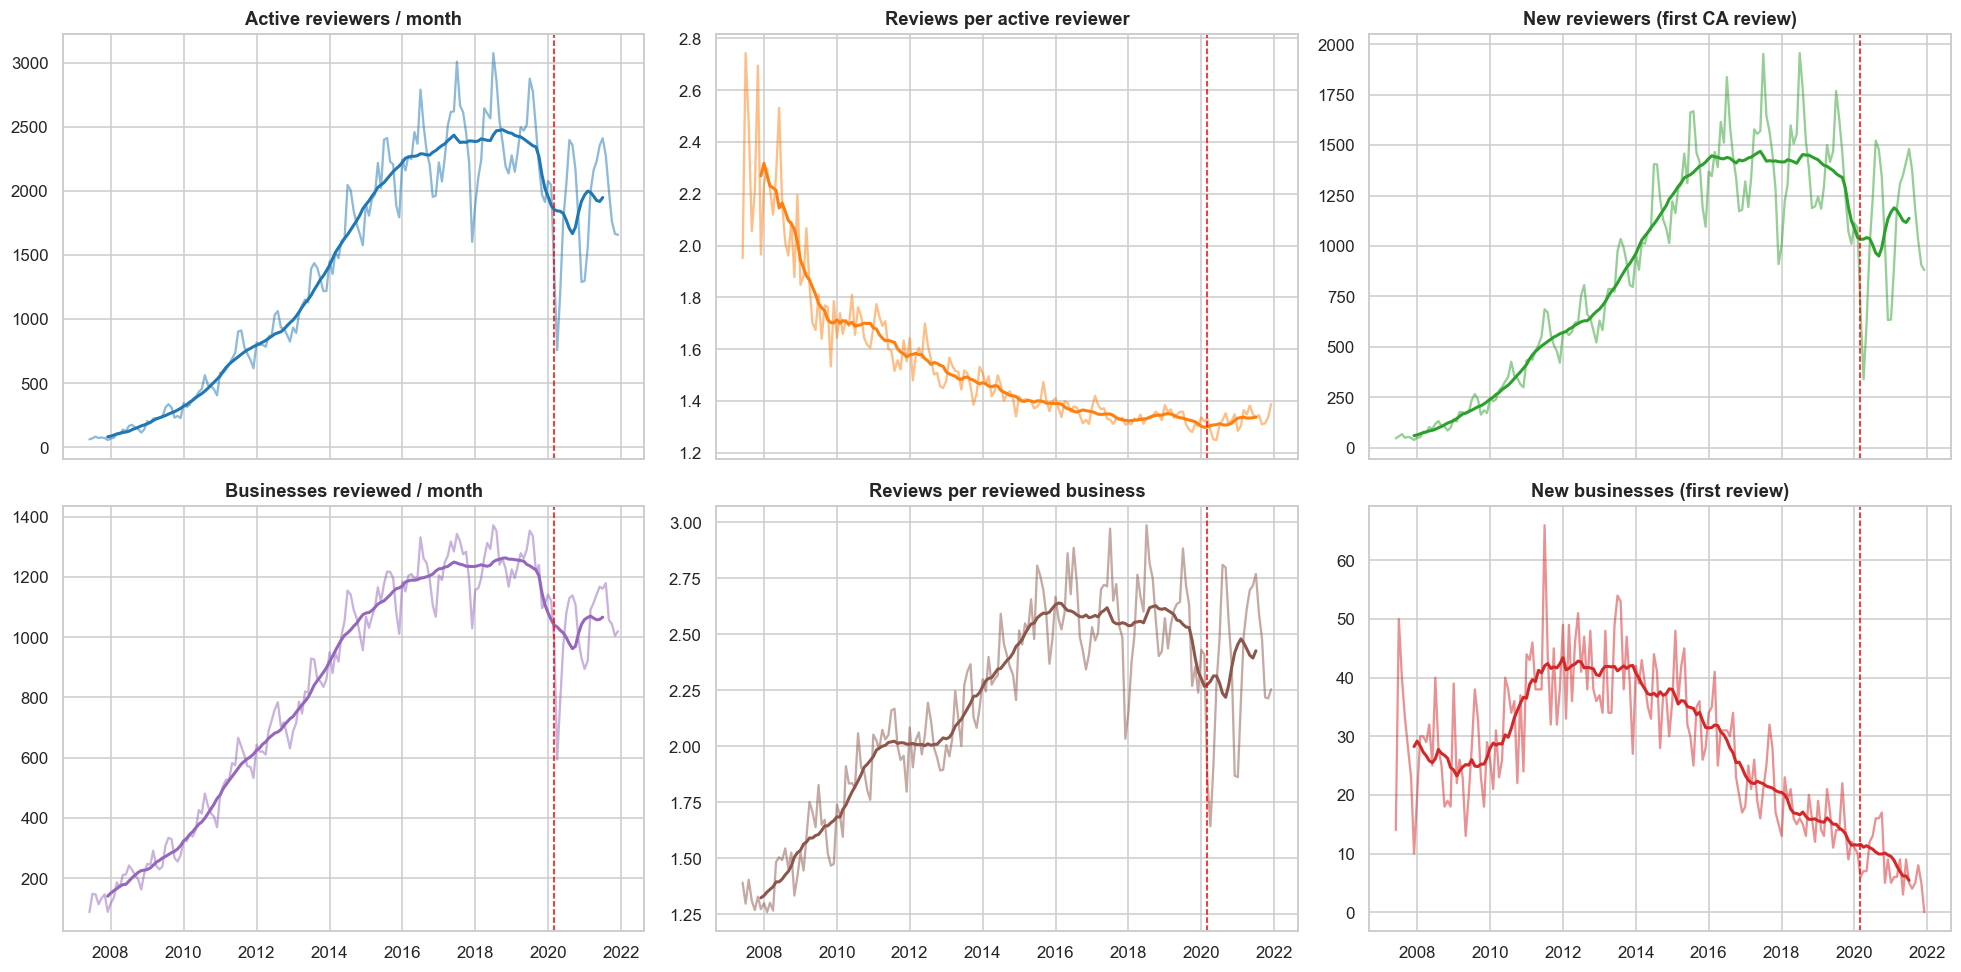

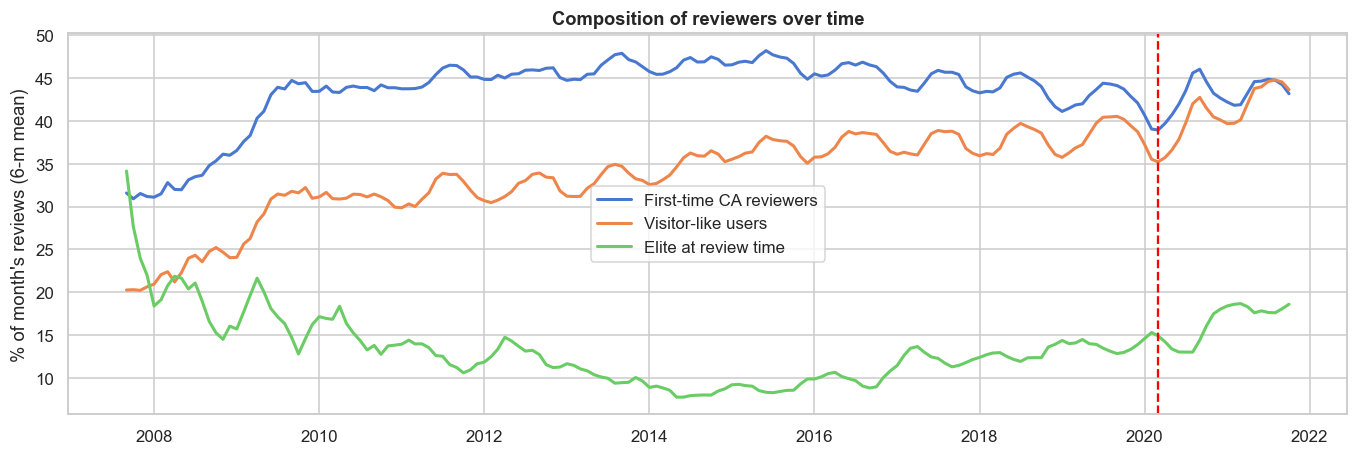

In [47]:
g = ca_reviews[(ca_reviews['month'] >= TS_START) & (ca_reviews['month'] <= TS_END)].copy()
idx = y.index
active_users = g.groupby('month')['user_id'].nunique().reindex(idx)
active_biz   = g.groupby('month')['business_id'].nunique().reindex(idx)
new_users = ca_reviews.groupby('user_id')['month'].min().value_counts().reindex(idx, fill_value=0).sort_index()
new_biz   = ca_reviews.groupby('business_id')['month'].min().value_counts().reindex(idx, fill_value=0).sort_index()

fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharex=True)
panels = [(active_users, 'Active reviewers / month', 'tab:blue'),
          (y / active_users, 'Reviews per active reviewer', 'tab:orange'),
          (new_users, 'New reviewers (first CA review)', 'tab:green'),
          (active_biz, 'Businesses reviewed / month', 'tab:purple'),
          (y / active_biz, 'Reviews per reviewed business', 'tab:brown'),
          (new_biz, 'New businesses (first review)', 'tab:red')]
for ax, (s, t, c) in zip(axes.ravel(), panels):
    ax.plot(idx, s.values, color=c, alpha=.5); ax.plot(idx, pd.Series(s.values, idx).rolling(12, center=True).mean(), color=c, lw=2)
    ax.axvline(COVID_START, color='red', ls='--', lw=1); ax.set_title(t)
plt.tight_layout(); plt.show()

# who writes the reviews?  composition over time
first_date = ca_users.set_index('user_id')['first_ca_review']
vis = ca_users.set_index('user_id')['visitor_like']
g['first_time'] = g['date'] == g['user_id'].map(first_date)
g['visitor']    = g['user_id'].map(vis).astype(bool)
comp = pd.DataFrame({'First-time CA reviewers': g.groupby('month')['first_time'].mean(),
                     'Visitor-like users': g.groupby('month')['visitor'].mean(),
                     'Elite at review time': g.groupby('month')['is_elite_at_review'].mean()}).reindex(idx) * 100
fig, ax = plt.subplots(figsize=(15, 4.5))
for c in comp: ax.plot(comp.index, comp[c].rolling(6, center=True).mean(), lw=2, label=c)
ax.axvline(COVID_START, color='red', ls='--'); ax.set_ylabel('% of month\'s reviews (6-m mean)')
ax.set_title('Composition of reviewers over time'); ax.legend(); plt.show()

### Seasonality
Four views of the same question (slide: *time series patterns*): the **seasonal plot** (one line per year), the **seasonal index** (month / yearly mean, pre-COVID complete years only so growth and the shock do not leak in), the **year x month heat-map**, and the **weekly rhythm**.

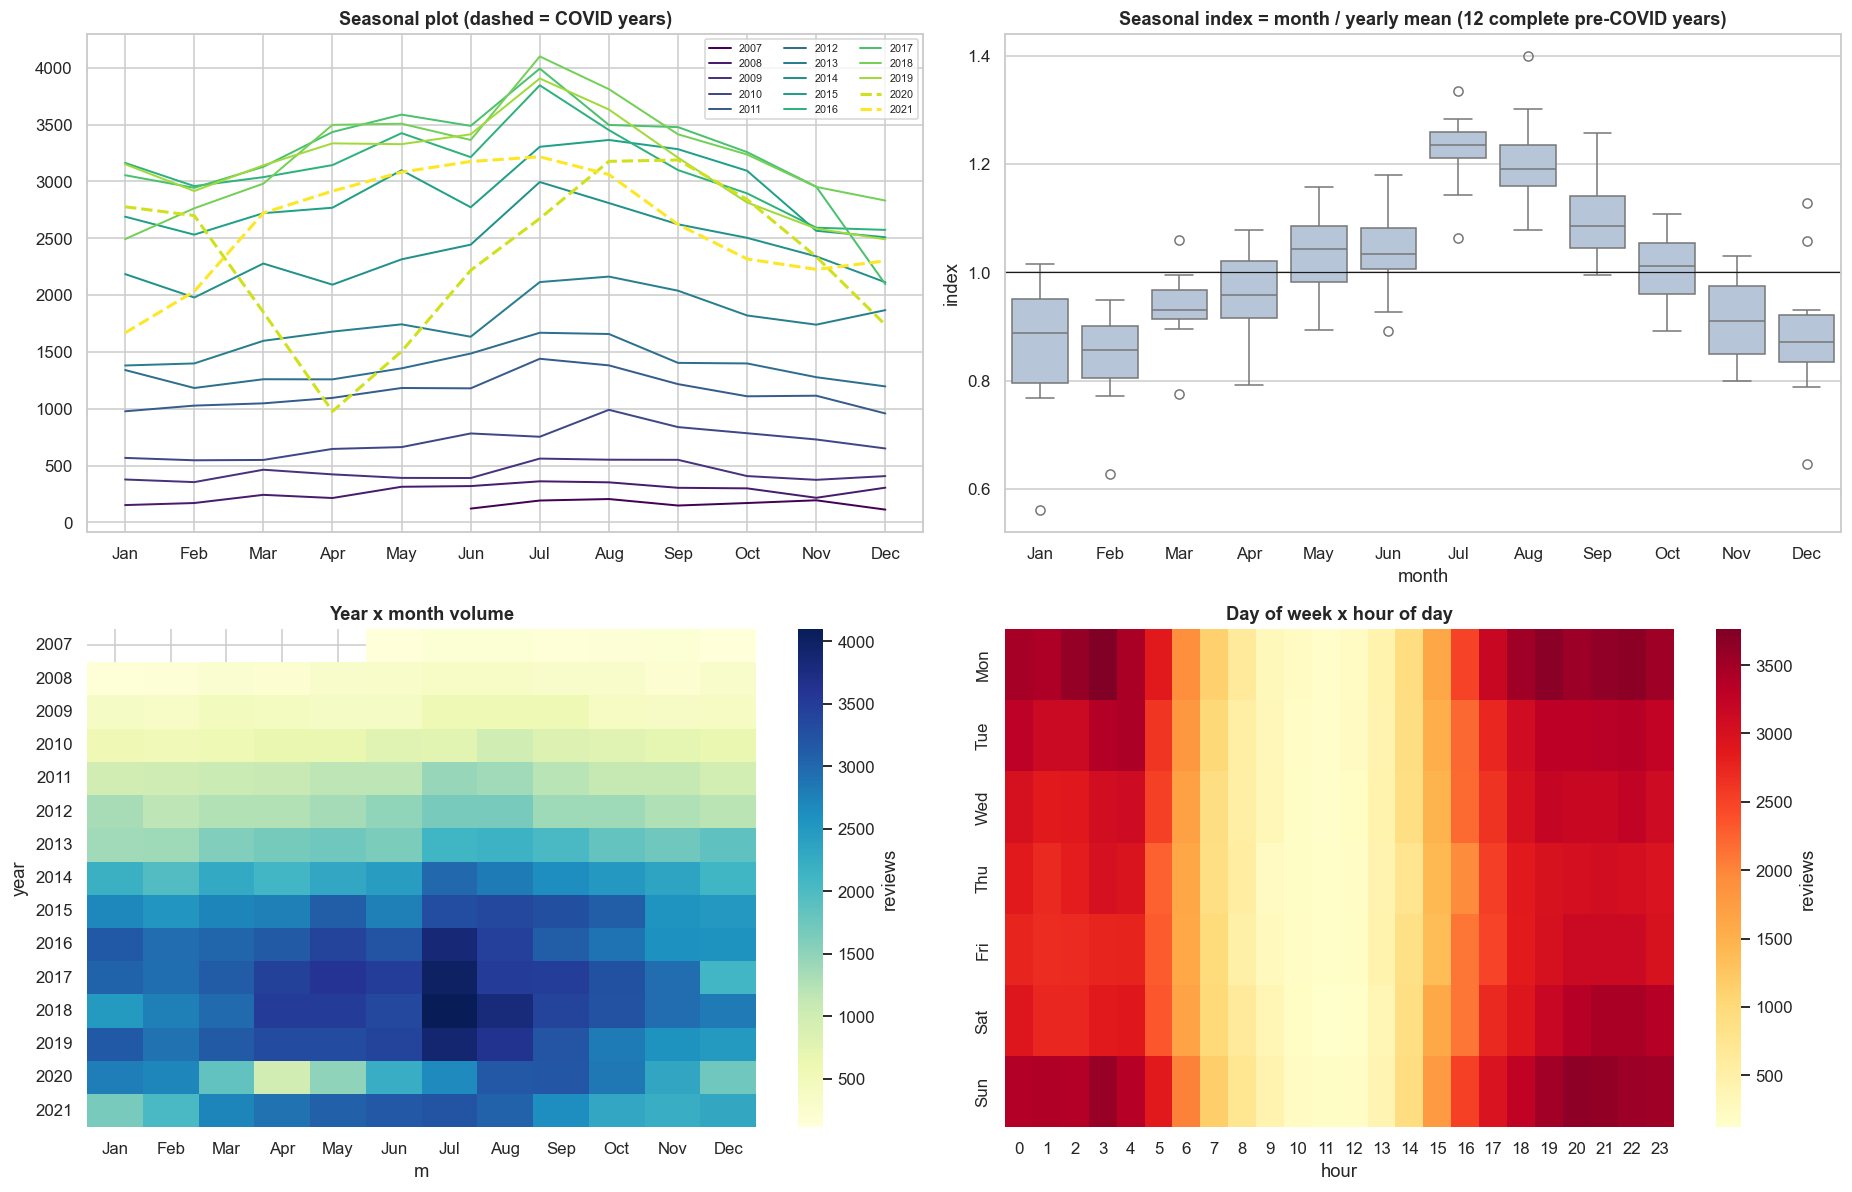

Seasonal index: peak = Jul (1.23x), trough = Feb (0.84x), peak/trough ratio = 1.46
Weekday share (%): {'Mon': 15.9, 'Tue': 14.6, 'Wed': 13.8, 'Thu': 13.1, 'Fri': 13.1, 'Sat': 13.8, 'Sun': 15.7}


In [48]:
piv = y.to_frame('v').assign(year=y.index.year, m=y.index.month).pivot(index='year', columns='m', values='v')
complete_pre = [yr for yr in piv.index if yr in y_pre.index.year and y_pre[y_pre.index.year == yr].shape[0] == 12]
seas_idx = piv.loc[complete_pre].div(piv.loc[complete_pre].mean(axis=1), axis=0)
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, axes = plt.subplots(2, 2, figsize=(17, 11))
# (a) seasonal plot
cmap = plt.cm.viridis(np.linspace(0, 1, len(piv)))
for (yr, row), col in zip(piv.iterrows(), cmap):
    axes[0, 0].plot(range(1, 13), row.values, color=col, lw=2 if yr >= 2020 else 1.3, ls='--' if yr >= 2020 else '-', label=str(yr))
axes[0, 0].set_xticks(range(1, 13)); axes[0, 0].set_xticklabels(MONTHS); axes[0, 0].legend(ncol=3, fontsize=7)
axes[0, 0].set_title('Seasonal plot (dashed = COVID years)')
# (b) seasonal index
sm = seas_idx.melt(var_name='month', value_name='index')
sns.boxplot(data=sm, x='month', y='index', ax=axes[0, 1], color='lightsteelblue')
axes[0, 1].axhline(1, color='k', lw=.8); axes[0, 1].set_xticklabels(MONTHS)
axes[0, 1].set_title(f'Seasonal index = month / yearly mean ({len(complete_pre)} complete pre-COVID years)')
# (c) heat-map
sns.heatmap(piv, cmap='YlGnBu', ax=axes[1, 0], cbar_kws={'label': 'reviews'}); axes[1, 0].set_xticklabels(MONTHS)
axes[1, 0].set_title('Year x month volume')
# (d) weekly rhythm
if ca_reviews['hour'].nunique() > 1:
    hm = ca_reviews.groupby(['dow', 'hour']).size().unstack(fill_value=0); hm.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
    sns.heatmap(hm, cmap='YlOrRd', ax=axes[1, 1], cbar_kws={'label': 'reviews'}); axes[1, 1].set_title('Day of week x hour of day')
else:
    hm = ca_reviews.groupby(['dow', 'year']).size().unstack(fill_value=0); hm = hm / hm.sum() * 100; hm.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
    sns.heatmap(hm, cmap='YlOrRd', ax=axes[1, 1]); axes[1, 1].set_title('Day of week share by year (%)')
plt.tight_layout(); plt.show()

si = seas_idx.mean()
print(f"Seasonal index: peak = {MONTHS[int(si.idxmax()) - 1]} ({si.max():.2f}x), trough = {MONTHS[int(si.idxmin()) - 1]} ({si.min():.2f}x), "
      f"peak/trough ratio = {si.max() / si.min():.2f}")
dw = ca_reviews['dow'].value_counts(normalize=True).sort_index() * 100
print("Weekday share (%):", dict(zip(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], dw.round(1))))

### STL decomposition (trend / seasonal / remainder)
Done on the **log** series (so seasonality is multiplicative; the check in the next cell confirms this choice). Seasonal and trend *strength* follow Hyndman: $F = \max(0,\,1 - \mathrm{Var}(R)/\mathrm{Var}(X+R))$. Months whose remainder is an outlier are listed; they are candidates for dummy variables (e.g. COVID) in ARIMAX.

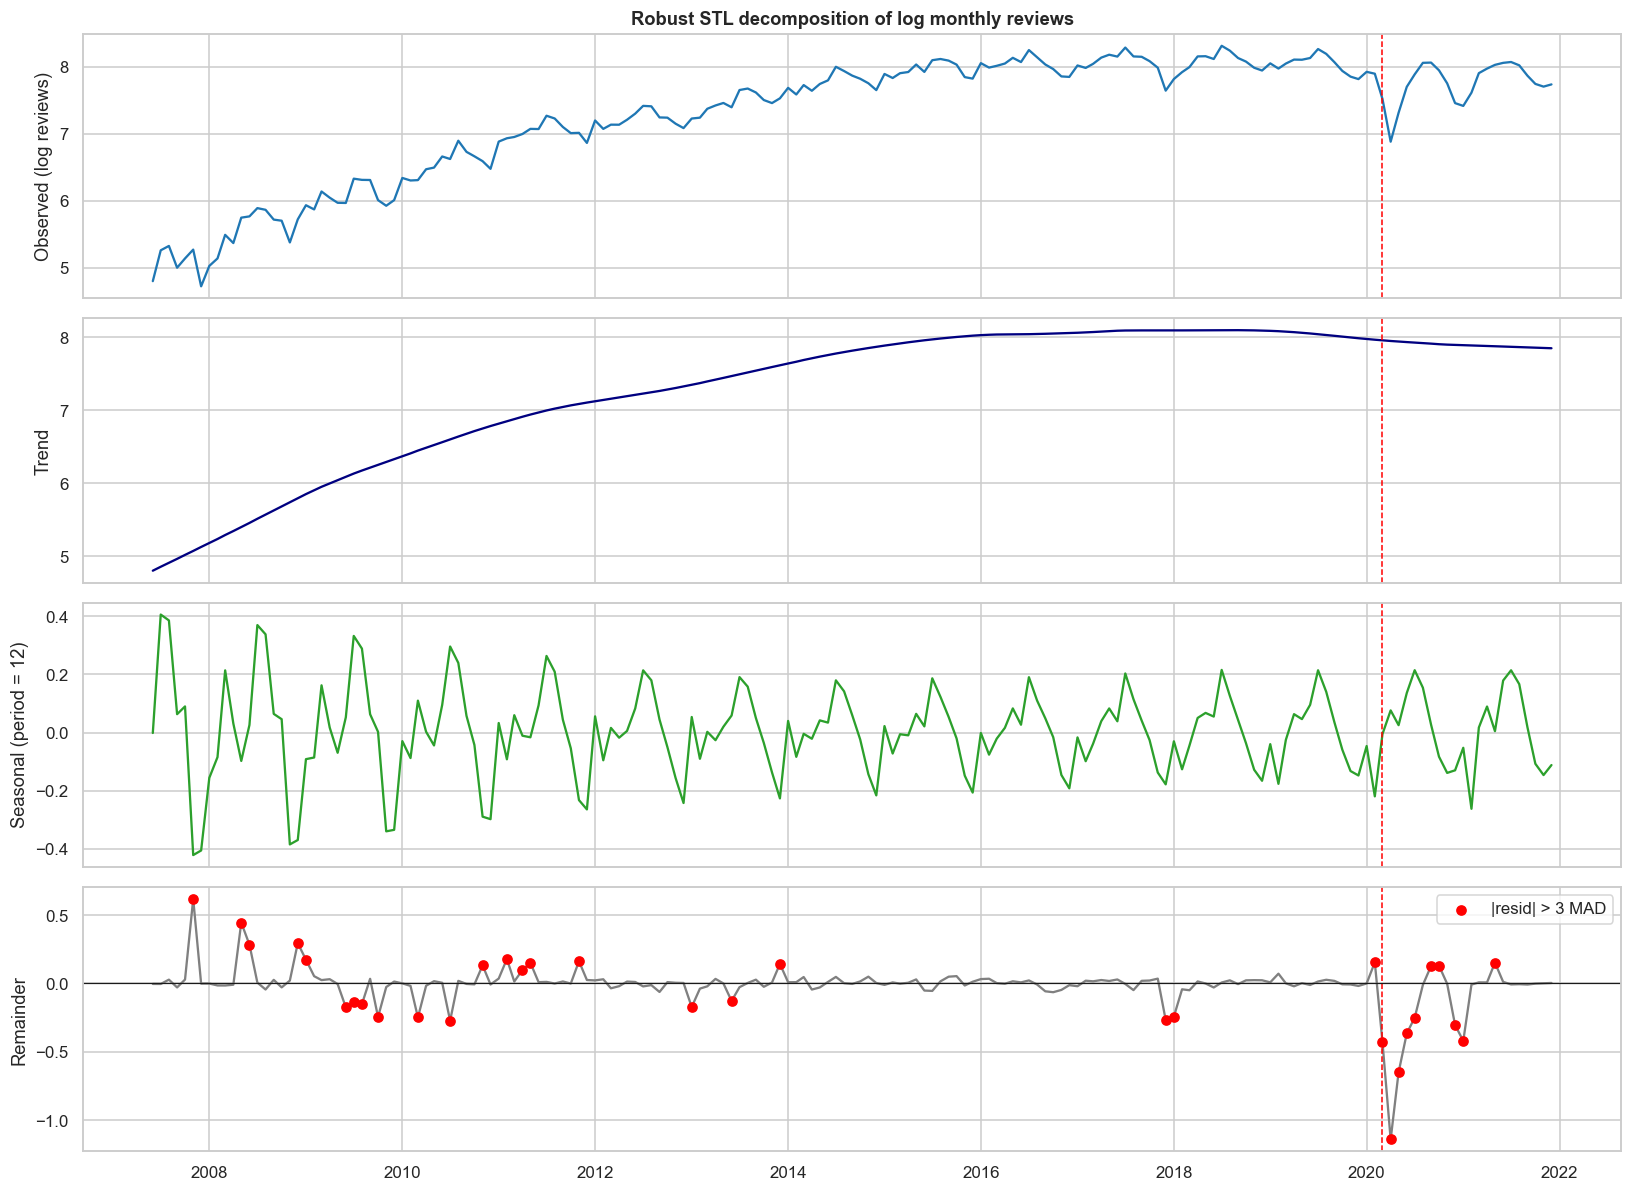

Trend strength F_T = 0.97 | Seasonal strength F_S = 0.36   (1 = fully deterministic, 0 = none)
Outlier months: ['2007-11', '2008-05', '2008-06', '2008-12', '2009-01', '2009-06', '2009-07', '2009-08', '2009-10', '2010-03', '2010-07', '2010-11', '2011-02', '2011-04', '2011-05', '2011-11', '2013-01', '2013-06', '2013-12', '2017-12', '2018-01', '2020-02', '2020-03', '2020-04', '2020-05', '2020-06', '2020-07', '2020-09', '2020-10', '2020-12', '2021-01', '2021-05']


In [49]:
ly = np.log(y.clip(lower=1))
stl = STL(ly, period=12, robust=True).fit()

def strengths(res):
    Ft = max(0, 1 - res.resid.var() / (res.trend + res.resid).var())
    Fs = max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())
    return Ft, Fs
Ft_all, Fs_all = strengths(stl)

fig, axes = plt.subplots(4, 1, figsize=(15, 11), sharex=True)
for ax, (s, t, c) in zip(axes, [(ly, 'Observed (log reviews)', 'tab:blue'), (stl.trend, 'Trend', 'navy'),
                                (stl.seasonal, 'Seasonal (period = 12)', 'tab:green'), (stl.resid, 'Remainder', 'gray')]):
    ax.plot(s.index, s.values, color=c); ax.set_ylabel(t); ax.axvline(COVID_START, color='red', ls='--', lw=1)
axes[3].axhline(0, color='k', lw=.8)
mad = np.median(np.abs(stl.resid - np.median(stl.resid))) * 1.4826
out = stl.resid[np.abs(stl.resid - np.median(stl.resid)) > 3 * mad]
axes[3].scatter(out.index, out.values, color='red', zorder=3, label='|resid| > 3 MAD'); axes[3].legend()
axes[0].set_title('Robust STL decomposition of log monthly reviews'); plt.tight_layout(); plt.show()
print(f"Trend strength F_T = {Ft_all:.2f} | Seasonal strength F_S = {Fs_all:.2f}   (1 = fully deterministic, 0 = none)")
print("Outlier months:", [d.strftime('%Y-%m') for d in out.index])

### Variance vs. level: log transform or not?
If the seasonal swing and the noise grow proportionally with the level (log-log slope ~ 1), the series is multiplicative and a log / Box-Cox transformation stabilises it (slide: *transformations*). A slope ~ 0 means additive.

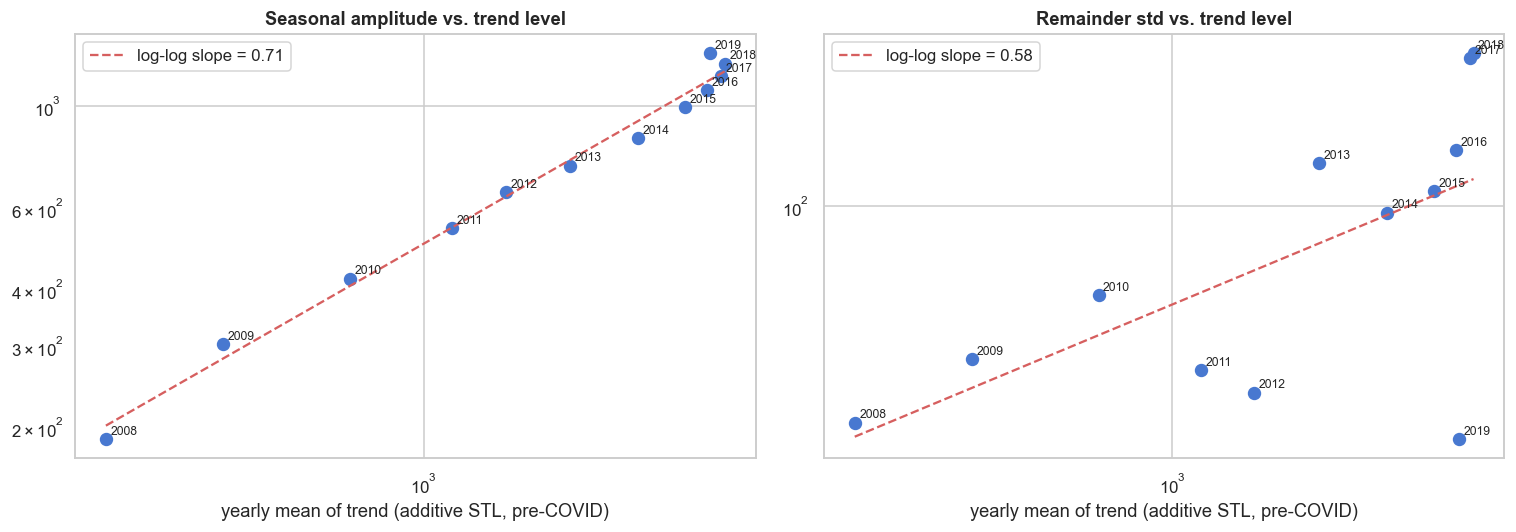

Average slope = 0.65  ->  multiplicative behaviour: use log (or Box-Cox) before ARIMA/ETS.


In [50]:
stl_raw = STL(y_pre, period=12, robust=True).fit()
rows = []
for yr, grp in pd.DataFrame({'trend': stl_raw.trend, 'seas': stl_raw.seasonal, 'res': stl_raw.resid}).groupby(y_pre.index.year):
    if len(grp) == 12:
        rows.append({'year': yr, 'level': grp['trend'].mean(), 'seas_range': grp['seas'].max() - grp['seas'].min(), 'res_std': grp['res'].std()})
vl = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
slopes = {}
for ax, col, t in zip(axes, ['seas_range', 'res_std'], ['Seasonal amplitude vs. trend level', 'Remainder std vs. trend level']):
    if len(vl) >= 4:
        sl = stats.linregress(np.log(vl['level']), np.log(vl[col].clip(lower=1e-6))); slopes[col] = sl.slope
        ax.scatter(vl['level'], vl[col], s=60)
        for _, r in vl.iterrows(): ax.annotate(int(r['year']), (r['level'], r[col]), fontsize=8, xytext=(3, 3), textcoords='offset points')
        xx = np.linspace(vl['level'].min(), vl['level'].max(), 50)
        ax.plot(xx, np.exp(sl.intercept) * xx ** sl.slope, 'r--', label=f'log-log slope = {sl.slope:.2f}'); ax.legend()
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('yearly mean of trend (additive STL, pre-COVID)'); ax.set_title(t)
plt.tight_layout(); plt.show()
if slopes:
    s_ = np.mean(list(slopes.values()))
    print(f"Average slope = {s_:.2f}  ->  " + ("multiplicative behaviour: use log (or Box-Cox) before ARIMA/ETS." if s_ > .6
          else "closer to additive: raw scale may be fine (ETS additive)." if s_ < .3 else "in between: try both log and Box-Cox (lambda ~ 0.5)."))

### Stationarity & autocorrelation (pre-COVID window)
The COVID break is a structural change that would dominate ADF/KPSS and the ACF, so the diagnostics use the **pre-COVID window**. ADF: H0 = unit root (want p < 0.05). KPSS: H0 = stationary (want p > 0.05). A series is called stationary only when **both** agree.

,n,ADF p,KPSS p (clipped .01-.1),verdict
transformation,,,,
raw level,153,0.5084,0.0100,non-stationary
log,153,0.0594,0.0100,non-stationary
raw d=1,152,0.4617,0.1000,conflicting
log d=1,152,0.3196,0.0126,non-stationary
log D=1 (lag 12),141,0.8253,0.0100,non-stationary
log d=1 & D=1,140,0.0001,0.1000,stationary


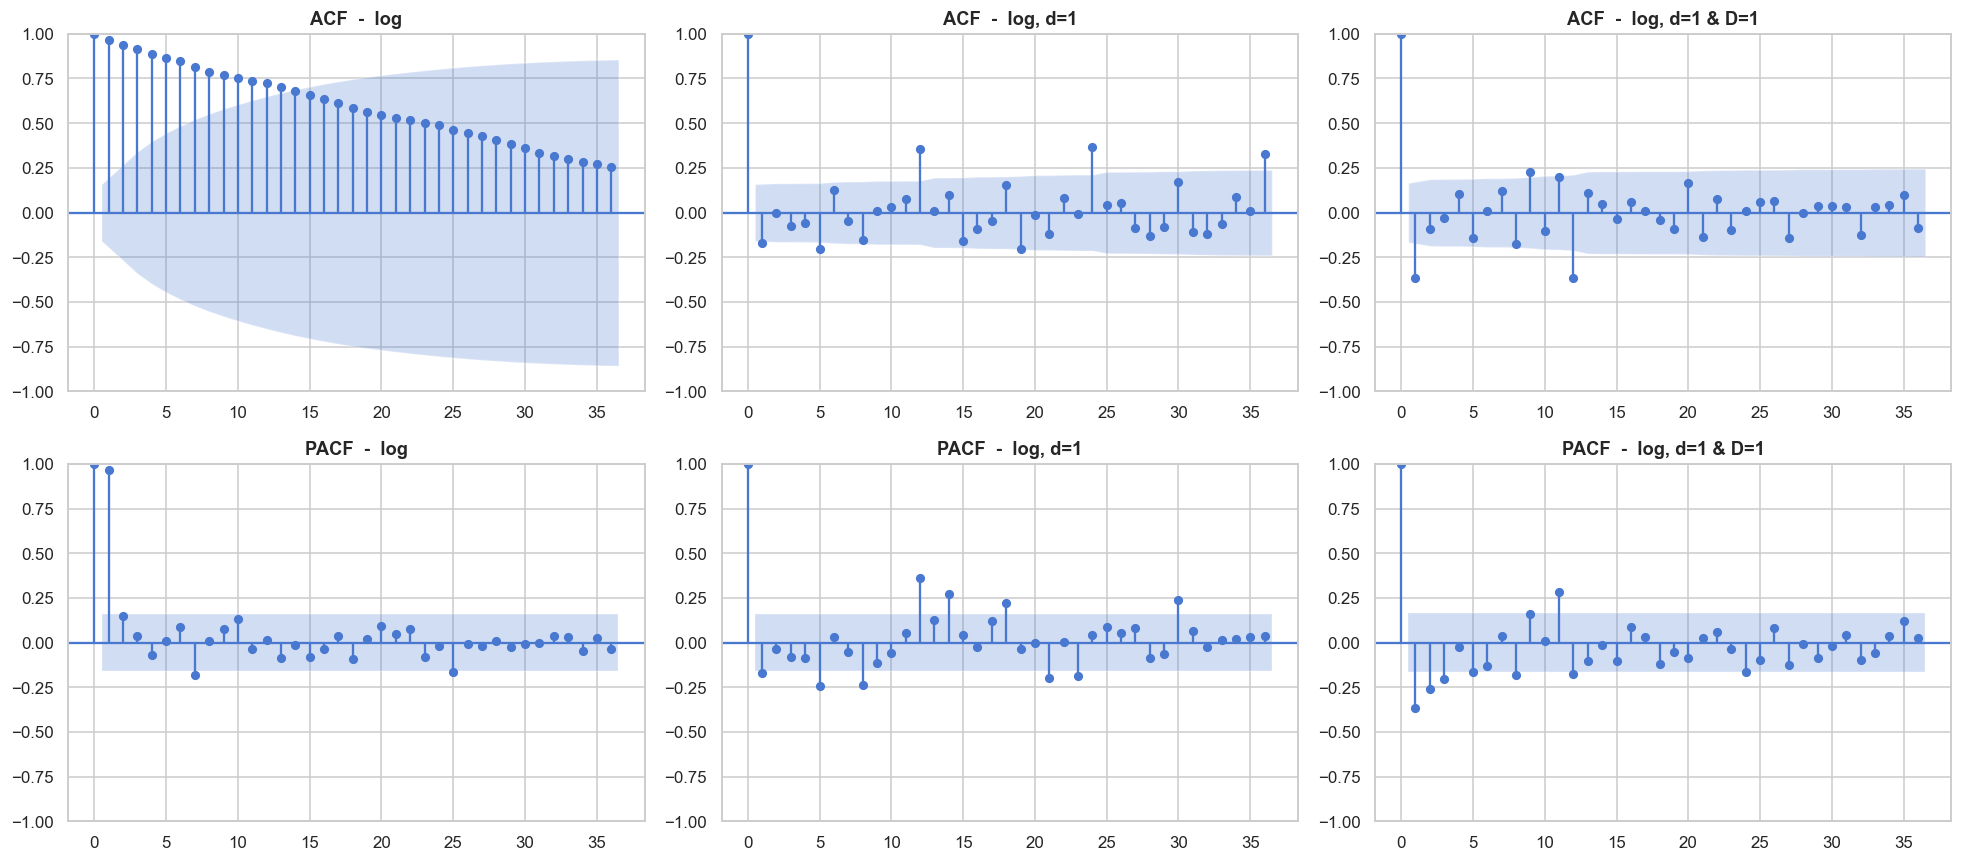

In [51]:
def stationarity_row(s, name):
    s = pd.Series(s).dropna()
    adf_p = adfuller(s, autolag='AIC')[1]
    kp = kpss(s, regression='c', nlags='auto')[1]
    verdict = 'stationary' if (adf_p < .05 and kp > .05) else ('non-stationary' if (adf_p >= .05 and kp <= .05) else 'conflicting')
    return {'transformation': name, 'n': len(s), 'ADF p': adf_p, 'KPSS p (clipped .01-.1)': kp, 'verdict': verdict}

lyp = np.log(y_pre.clip(lower=1))
variants = {'raw level': y_pre, 'log': lyp, 'raw  d=1': y_pre.diff(), 'log  d=1': lyp.diff(),
            'log  D=1 (lag 12)': lyp.diff(12), 'log  d=1 & D=1': lyp.diff().diff(12)}
st = pd.DataFrame([stationarity_row(v, k) for k, v in variants.items()]).set_index('transformation')
display(st.round(4))

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for j, (name, s) in enumerate([('log', lyp), ('log, d=1', lyp.diff()), ('log, d=1 & D=1', lyp.diff().diff(12))]):
    s = s.dropna()
    plot_acf(s, lags=36, ax=axes[0, j], title=f'ACF  -  {name}'); plot_pacf(s, lags=36, ax=axes[1, j], method='ywm', title=f'PACF  -  {name}')
plt.tight_layout(); plt.show()

### Rating & text dynamics
Is the *quality* signal itself a time series with structure? Also checks whether low-volume months differ in rating (a bias to know about if average stars is used as a forecast target).

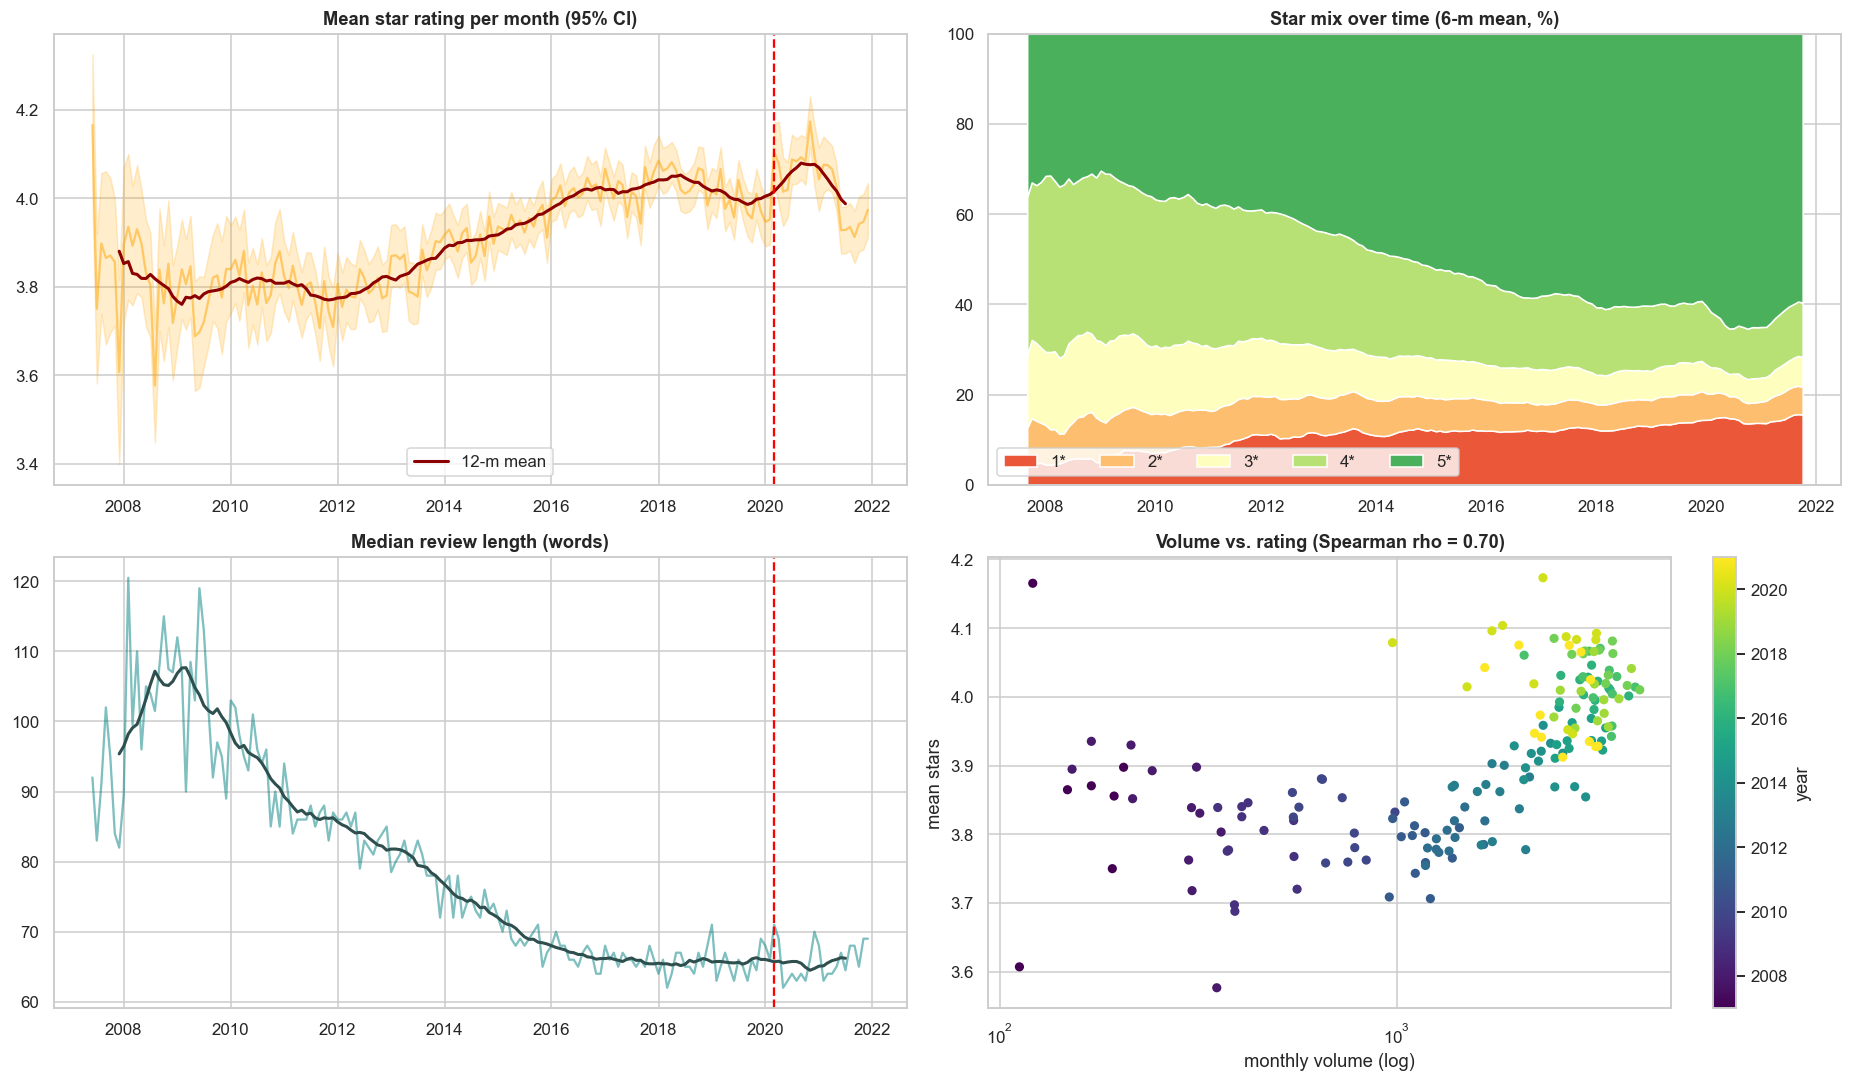

Angry (1*) reviews avg 136 words | Happy (5*) 83 words


In [52]:
gm = g.groupby('month')
mean_stars = gm['stars'].mean().reindex(idx); se = (gm['stars'].std() / np.sqrt(gm.size())).reindex(idx)
star_share = pd.crosstab(g['month'], g['stars'], normalize='index').reindex(idx) * 100
med_len = gm['text_length'].median().reindex(idx)

fig, axes = plt.subplots(2, 2, figsize=(17, 10))
ax = axes[0, 0]
ax.plot(idx, mean_stars, color='orange', alpha=.5); ax.fill_between(idx, mean_stars - 1.96 * se, mean_stars + 1.96 * se, color='orange', alpha=.2)
ax.plot(idx, mean_stars.rolling(12, center=True).mean(), color='darkred', lw=2, label='12-m mean'); ax.axvline(COVID_START, color='red', ls='--')
ax.set_title('Mean star rating per month (95% CI)'); ax.legend()
axes[0, 1].stackplot(idx, [star_share[s].rolling(6, center=True).mean() for s in [1, 2, 3, 4, 5]], labels=['1*', '2*', '3*', '4*', '5*'],
                     colors=sns.color_palette('RdYlGn', 5))
axes[0, 1].set_ylim(0, 100); axes[0, 1].legend(loc='lower left', ncol=5); axes[0, 1].set_title('Star mix over time (6-m mean, %)')
axes[1, 0].plot(idx, med_len, color='teal', alpha=.5); axes[1, 0].plot(idx, med_len.rolling(12, center=True).mean(), color='darkslategray', lw=2)
axes[1, 0].axvline(COVID_START, color='red', ls='--'); axes[1, 0].set_title('Median review length (words)')
sc = axes[1, 1].scatter(y.values, mean_stars.values, c=idx.year, cmap='viridis', s=25)
axes[1, 1].set_xscale('log'); axes[1, 1].set_xlabel('monthly volume (log)'); axes[1, 1].set_ylabel('mean stars'); plt.colorbar(sc, ax=axes[1, 1], label='year')
r_, p_ = stats.spearmanr(y.values, mean_stars.values, nan_policy='omit')
axes[1, 1].set_title(f'Volume vs. rating (Spearman rho = {r_:.2f})')
plt.tight_layout(); plt.show()
print(f"Angry (1*) reviews avg {ca_reviews.loc[ca_reviews['stars'] == 1, 'text_length'].mean():.0f} words | Happy (5*) {ca_reviews.loc[ca_reviews['stars'] == 5, 'text_length'].mean():.0f} words")

### Category and city series
Do segments of the market move together, or did COVID hit them differently? (Index = 100 at the last 12 pre-COVID months.)

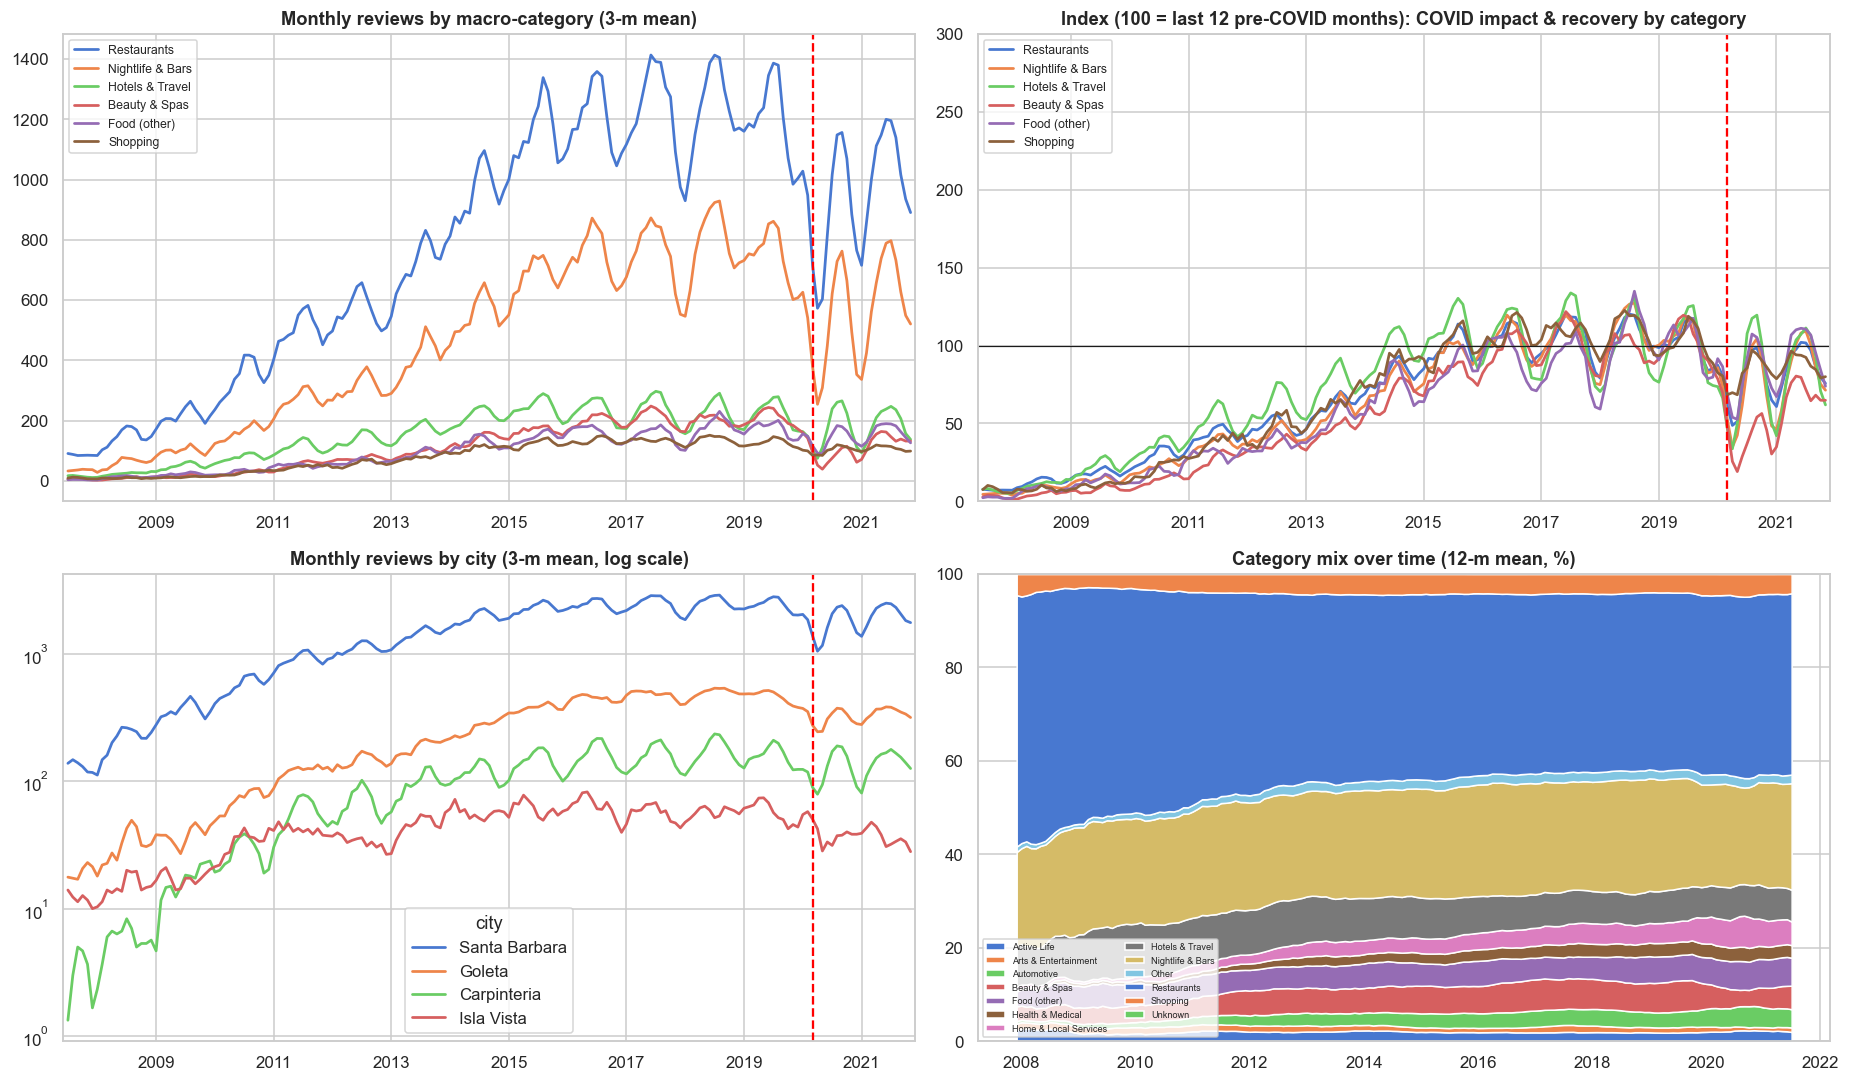

Spring-2020 volume as % of pre-COVID baseline, by category:
 macro_cat
Beauty & Spas            27.0
Arts & Entertainment     38.0
Nightlife & Bars         43.0
Hotels & Travel          49.0
Restaurants              54.0
Food (other)             59.0
Active Life              61.0
Health & Medical         65.0
Other                    68.0
Shopping                 70.0
Automotive               73.0
Home & Local Services    85.0
Unknown                   NaN


In [53]:
cat_m = g.groupby(['month', 'macro_cat']).size().unstack(fill_value=0).reindex(idx, fill_value=0)
top_cats = cat_m.sum().nlargest(6).index.tolist()
city_m = g.groupby(['month', 'city']).size().unstack(fill_value=0).reindex(idx, fill_value=0)
top_cities = city_m.sum().nlargest(4).index.tolist()
base_cat = cat_m.loc[BASE.index].mean()

fig, axes = plt.subplots(2, 2, figsize=(17, 10))
cat_m[top_cats].rolling(3, center=True).mean().plot(ax=axes[0, 0], lw=1.8); axes[0, 0].axvline(COVID_START, color='red', ls='--')
axes[0, 0].set_title('Monthly reviews by macro-category (3-m mean)'); axes[0, 0].legend(fontsize=8)
(cat_m[top_cats].div(base_cat[top_cats]) * 100).rolling(3, center=True).mean().plot(ax=axes[0, 1], lw=1.8)
axes[0, 1].axhline(100, color='k', lw=.8); axes[0, 1].axvline(COVID_START, color='red', ls='--'); axes[0, 1].set_ylim(0, 300)
axes[0, 1].set_title('Index (100 = last 12 pre-COVID months): COVID impact & recovery by category'); axes[0, 1].legend(fontsize=8)
city_m[top_cities].rolling(3, center=True).mean().plot(ax=axes[1, 0], logy=True, lw=1.8); axes[1, 0].axvline(COVID_START, color='red', ls='--')
axes[1, 0].set_title('Monthly reviews by city (3-m mean, log scale)')
share = cat_m.div(cat_m.sum(axis=1), axis=0).rolling(12, center=True).mean() * 100
axes[1, 1].stackplot(idx, [share[c] for c in share.columns], labels=share.columns); axes[1, 1].set_ylim(0, 100)
axes[1, 1].legend(fontsize=6, ncol=2, loc='lower left'); axes[1, 1].set_title('Category mix over time (12-m mean, %)')
plt.tight_layout(); plt.show()

trough = (cat_m.loc['2020-03-01':'2020-06-01'].mean() / base_cat * 100).round(0).sort_values()
print("Spring-2020 volume as % of pre-COVID baseline, by category:\n", trough.to_string())

### Check-ins as a possible exogenous variable (optional)
Check-ins measure physical visits, whereas reviews are a later, voluntary reaction. If check-ins lead reviews they could be a useful regressor in ARIMAX / Prophet. This cell is skipped automatically if the file is not found.

Check-ins in CA subset, analysis window: 674,689


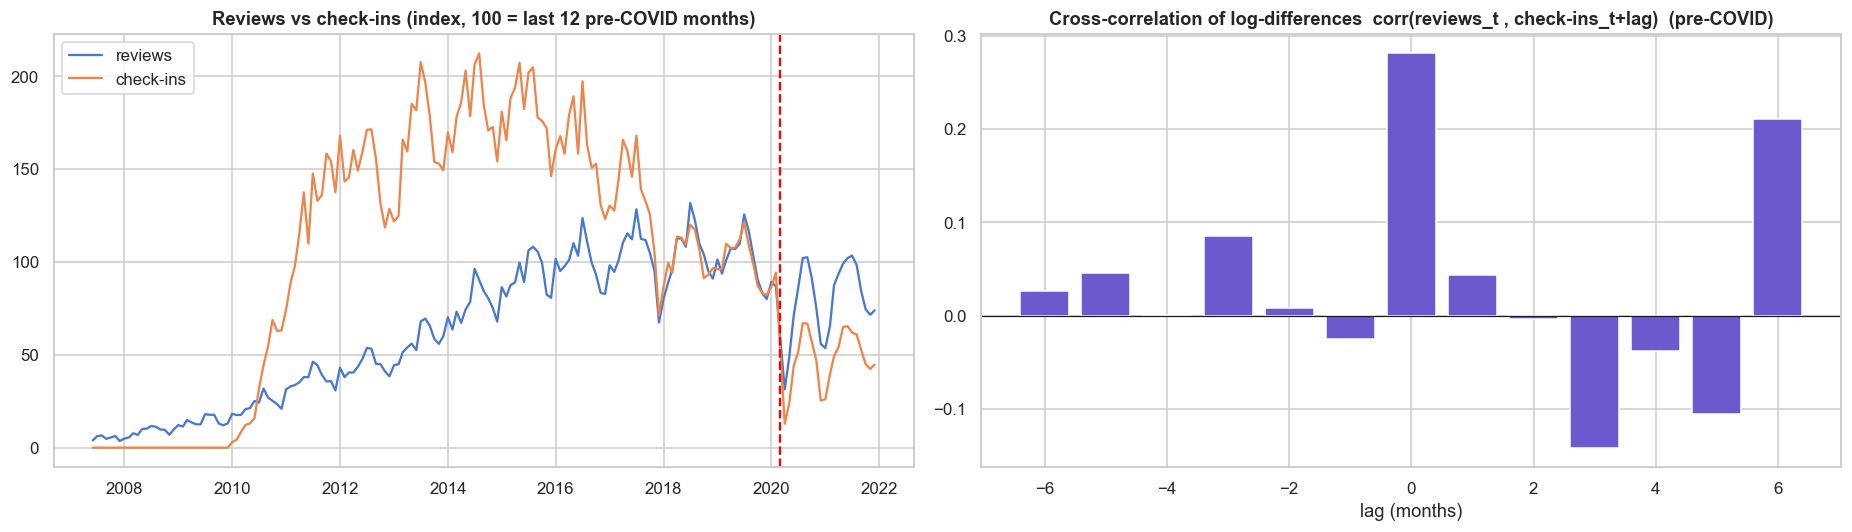

In [54]:
chk_path = os.path.join(target_path, "yelp_academic_dataset_checkin.json")
checkin_monthly = None
if os.path.exists(chk_path):
    valid_b = set(ca_biz['business_id']); parts = []
    for ch in pd.read_json(chk_path, lines=True, chunksize=50_000):
        ch = ch[ch['business_id'].isin(valid_b)]
        if len(ch) == 0: continue
        ts_ = pd.to_datetime(ch['date'].str.split(', ').explode())
        parts.append(ts_.dt.to_period('M').dt.to_timestamp().value_counts())
    checkin_monthly = pd.concat(parts).groupby(level=0).sum().sort_index().reindex(idx, fill_value=0).astype(float)
    print(f"Check-ins in CA subset, analysis window: {int(checkin_monthly.sum()):,}")

    fig, axes = plt.subplots(1, 2, figsize=(17, 5))
    axes[0].plot(idx, (y / y.loc[BASE.index].mean() * 100), label='reviews'); axes[0].plot(idx, (checkin_monthly / checkin_monthly.loc[BASE.index].mean() * 100), label='check-ins')
    axes[0].axvline(COVID_START, color='red', ls='--'); axes[0].set_title('Reviews vs check-ins (index, 100 = last 12 pre-COVID months)'); axes[0].legend()
    dr = np.log(y_pre.clip(lower=1)).diff(); dc = np.log(checkin_monthly.loc[y_pre.index].clip(lower=1)).diff()
    lags = range(-6, 7); cc = [dr.corr(dc.shift(-l)) for l in lags]
    axes[1].bar(list(lags), cc, color='slateblue'); axes[1].axhline(0, color='k', lw=.8)
    axes[1].set_title('Cross-correlation of log-differences  corr(reviews_t , check-ins_t+lag)  (pre-COVID)'); axes[1].set_xlabel('lag (months)')
    plt.tight_layout(); plt.show()
else:
    print("Check-in file not found -> skipped.")

## 4. Network analysis

The friendship graph is **static** (no edge timestamps) and only contains friendships *between users in our CA subset*; friends outside the subset were dropped, so the graph is a truncated view of the real network. Edges are built vectorised (the previous `iterrows` loop is replaced), then we compute the week-4 descriptors: degree distribution, components, clustering, assortativity / homophily, centrality and communities.

In [55]:
# ---------- build undirected graph ----------
valid_uids = set(ca_users['user_id'])
fr = ca_users.loc[~ca_users['friends'].isin(['None', '']), ['user_id', 'friends']]
parts = []
for s in range(0, len(fr), 10_000):                       # chunked explode keeps memory low
    p = fr.iloc[s:s + 10_000]
    ex = p.assign(friend=p['friends'].str.split(r',\s*')).explode('friend')
    parts.append(ex.loc[ex['friend'].isin(valid_uids), ['user_id', 'friend']])
ed = pd.concat(parts, ignore_index=True)
ed = ed[ed['user_id'] != ed['friend']]
lo = ed['user_id'].where(ed['user_id'] < ed['friend'], ed['friend']); hi = ed['friend'].where(ed['user_id'] < ed['friend'], ed['user_id'])
E = pd.DataFrame({'a': lo, 'b': hi}).drop_duplicates().reset_index(drop=True)
G = nx.from_pandas_edgelist(E, 'a', 'b')
print(f"Edges kept: {len(E):,}  (one-sided listings are treated as undirected ties)")

# ---------- node-level metrics ----------
deg = pd.Series(dict(G.degree()))
ca_users['degree'] = ca_users['user_id'].map(deg).fillna(0).astype(int)
pr = nx.pagerank(G, alpha=0.85, tol=1e-6)
ca_users['pagerank'] = ca_users['user_id'].map(pr).fillna(0)
core = nx.core_number(G)
ca_users['core'] = ca_users['user_id'].map(core).fillna(0).astype(int)

comps = sorted(nx.connected_components(G), key=len, reverse=True)
lcc = comps[0]
in_G = ca_users['user_id'].isin(G.nodes)
rev_in_G = ca_reviews['user_id'].isin(G.nodes).mean()
rev_in_lcc = ca_reviews['user_id'].isin(lcc).mean()

# assortativity = Pearson correlation of an attribute across the two endpoints of every edge (slide: 'measuring homophily')
def attr_assortativity(attr):
    s = ca_users.set_index('user_id')[attr].astype(float)
    xa, xb = s.reindex(E['a']).values, s.reindex(E['b']).values
    return np.corrcoef(np.r_[xa, xb], np.r_[xb, xa])[0, 1]
ca_users['log_ca_reviews'] = np.log1p(ca_users['ca_review_count'])
assort = {lab: attr_assortativity(col) for lab, col in [('degree', 'degree'), ('avg. stars given', 'average_stars'), ('log #reviews', 'log_ca_reviews'),
                                                          ('is Elite', 'is_elite_ever'), ('join year', 'join_year')]}

net_summary = pd.Series({
    'Nodes (users with >=1 friend in subset)': f"{G.number_of_nodes():,}  ({in_G.mean() * 100:.1f}% of users)",
    'Edges': f"{G.number_of_edges():,}",
    'Density': f"{nx.density(G):.6f}",
    'Mean / median / max degree': f"{deg.mean():.1f} / {deg.median():.0f} / {deg.max():,}",
    'Connected components': f"{len(comps):,}",
    'Largest component': f"{len(lcc):,} nodes ({len(lcc) / G.number_of_nodes() * 100:.1f}%)",
    'Reviews written by users in graph': f"{rev_in_G * 100:.1f}%",
    'Reviews written by users in largest component': f"{rev_in_lcc * 100:.1f}%",
    'Avg. clustering (approx., 5000 trials)': f"{nx.approximation.average_clustering(G, trials=5000, seed=SEED):.3f}",
    'Max k-core': int(ca_users['core'].max()),
    'Degree assortativity': f"{assort['degree']:.3f}",
}, name='value')
display(net_summary.to_frame())
print("Attribute assortativity (>0 = similar users befriend each other):", {k: round(float(v), 3) for k, v in assort.items()})

Edges kept: 470,965  (one-sided listings are treated as undirected ties)


,value
Nodes (users with >=1 friend in subset),"64,135 (41.3% of users)"
Edges,"470,965"
Density,0.000229
Mean / median / max degree,"14.7 / 4 / 2,007"
Connected components,"1,092"
Largest component,"61,785 nodes (96.3%)"
Reviews written by users in graph,55.4%
Reviews written by users in largest component,54.0%
"Avg. clustering (approx., 5000 trials)",0.099
Max k-core,89


Attribute assortativity (>0 = similar users befriend each other): {'degree': 0.04, 'avg. stars given': 0.056, 'log #reviews': 0.166, 'is Elite': 0.597, 'join year': 0.495}


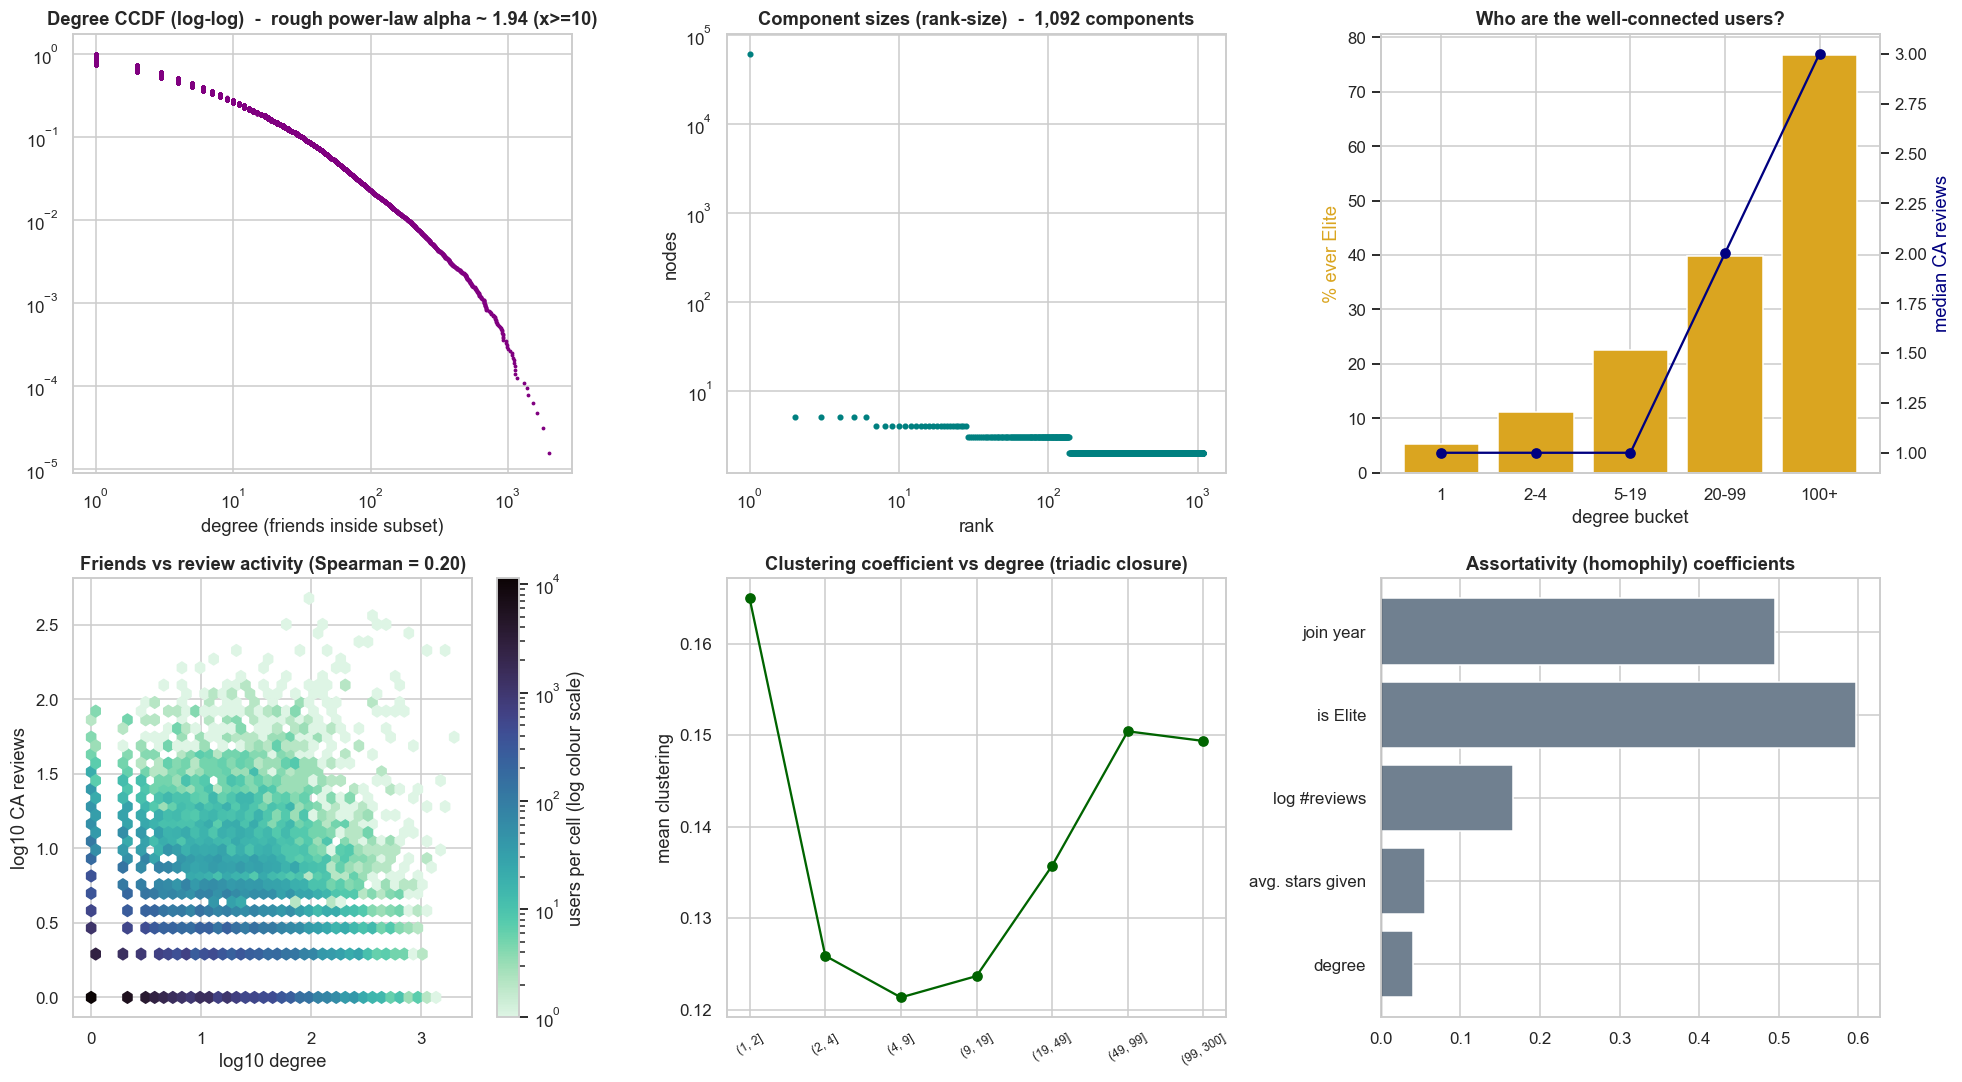

Top 10 most connected users (raw degree; degree centrality = degree / (N-1)):


,user_id,degree,pagerank,ca_review_count,fans,n_elite_years,join_year
145,ZIOCmdFa...,2007,0.00137,53,1124,12,2011
14978,hizGc5W1...,1807,0.00122,20,3642,14,2009
47925,dxzENIwn...,1629,0.00134,28,274,7,2015
18532,hu53X0Ag...,1518,0.00187,211,711,7,2015
405,AbMjnKOw...,1395,0.00078,10,1563,13,2010
15009,yLW8OrR8...,1377,0.00079,1,382,12,2007
2476,WDpvs6U_...,1299,0.00071,7,483,10,2009
15112,peuxbSQw...,1156,0.00072,19,1927,9,2011
46548,6LmdYq-m...,1132,0.00069,4,758,8,2010
17066,uIjj7EIV...,1123,0.00074,9,153,7,2011


In [56]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
dv = deg.values
# (a) degree CCDF + rough power-law exponent (continuous MLE, xmin = 10)
x, yv = ccdf(dv); axes[0, 0].loglog(x, yv, '.', ms=3, color='purple')
xmin = 10; tail = dv[dv >= xmin]; alpha_hat = 1 + len(tail) / np.sum(np.log(tail / (xmin - 0.5)))
axes[0, 0].set_title(f'Degree CCDF (log-log)  -  rough power-law alpha ~ {alpha_hat:.2f} (x>=10)'); axes[0, 0].set_xlabel('degree (friends inside subset)')
# (b) component sizes
cs = np.array([len(c) for c in comps]); axes[0, 1].loglog(np.arange(1, len(cs) + 1), cs, '.', color='teal')
axes[0, 1].set_title(f'Component sizes (rank-size)  -  {len(cs):,} components'); axes[0, 1].set_xlabel('rank'); axes[0, 1].set_ylabel('nodes')
# (c) degree buckets vs activity
nb = ca_users[ca_users['degree'] > 0].copy()
nb['bucket'] = pd.cut(nb['degree'], [0, 1, 4, 19, 99, np.inf], labels=['1', '2-4', '5-19', '20-99', '100+'])
bs = nb.groupby('bucket', observed=True).agg(elite=('is_elite_ever', 'mean'), med_rev=('ca_review_count', 'median'))
axes[0, 2].bar(bs.index.astype(str), bs['elite'] * 100, color='goldenrod'); axes[0, 2].set_ylabel('% ever Elite', color='goldenrod')
a2 = axes[0, 2].twinx(); a2.plot(bs.index.astype(str), bs['med_rev'], 'o-', color='navy'); a2.set_ylabel('median CA reviews', color='navy'); a2.grid(False)
axes[0, 2].set_title('Who are the well-connected users?'); axes[0, 2].set_xlabel('degree bucket')
# (d) friends vs activity
hb = axes[1, 0].hexbin(np.log10(nb['degree']), np.log10(nb['ca_review_count'].clip(lower=1)), gridsize=40, bins='log', cmap='mako_r')
axes[1, 0].set_xlabel('log10 degree'); axes[1, 0].set_ylabel('log10 CA reviews'); plt.colorbar(hb, ax=axes[1, 0], label='users per cell (log colour scale)')
rho = stats.spearmanr(nb['degree'], nb['ca_review_count'])[0]; axes[1, 0].set_title(f'Friends vs review activity (Spearman = {rho:.2f})')
# (e) clustering vs degree (sample, hubs excluded for speed)
rng_ = np.random.default_rng(SEED); cand = deg[(deg >= 2) & (deg <= 300)].index.values
samp = rng_.choice(cand, size=min(4000, len(cand)), replace=False)
cl = pd.Series(nx.clustering(G, nodes=list(samp))); cdf = pd.DataFrame({'deg': deg.loc[cl.index].values, 'cl': cl.values})
cdf['b'] = pd.cut(cdf['deg'], [1, 2, 4, 9, 19, 49, 99, 300]); cb = cdf.groupby('b', observed=True)['cl'].mean()
axes[1, 1].plot(range(len(cb)), cb.values, 'o-', color='darkgreen'); axes[1, 1].set_xticks(range(len(cb))); axes[1, 1].set_xticklabels([str(i) for i in cb.index], rotation=30, fontsize=8)
axes[1, 1].set_title('Clustering coefficient vs degree (triadic closure)'); axes[1, 1].set_ylabel('mean clustering')
# (f) assortativity
axes[1, 2].barh(list(assort.keys()), list(assort.values()), color='slategray'); axes[1, 2].axvline(0, color='k', lw=.8)
axes[1, 2].set_title('Assortativity (homophily) coefficients')
plt.tight_layout(); plt.show()

top = ca_users.sort_values('degree', ascending=False).head(10)[['user_id', 'degree', 'pagerank', 'ca_review_count', 'fans', 'n_elite_years', 'join_year']].copy()
top['user_id'] = top['user_id'].str[:8] + '...'
print("Top 10 most connected users (raw degree; degree centrality = degree / (N-1)):"); display(top.round(5))

### Communities (Louvain)
Louvain maximises modularity (slide: *community detection algorithms*). The key question for **community forecasting** is not only "do communities exist" but "**are they large enough to give a usable monthly time series?**": the plots below answer that. Louvain is stochastic; the seed is fixed in `SEED`, and results should be re-checked with other seeds / resolutions before the final report.

Louvain: 1,580 communities | modularity Q = 0.522 | top-10 sizes = [16538, 9727, 7434, 6843, 6607, 4907, 3454, 1759, 735, 643]


,users,reviews_in_window,share_of_all_reviews_%,median_monthly,share_nonzero_months,intra_edge_frac,forecastable,top_city,top_city_share,top_macro,top_macro_share,mean_stars,mean_degree,median_join_year
0,16538,58003.0,16.80,330.0,1.00,0.85,True,Santa Barbara,0.77,Restaurants,0.37,4.05,12.45,2013.0
5,4907,29190.0,8.45,161.0,0.99,0.58,True,Santa Barbara,0.74,Restaurants,0.43,4.07,6.68,2013.0
1,9727,28829.0,8.35,177.0,0.99,0.77,True,Santa Barbara,0.81,Restaurants,0.41,4.02,35.17,2011.0
2,7434,18745.0,5.43,104.0,1.00,0.59,True,Santa Barbara,0.83,Restaurants,0.42,3.99,14.26,2010.0
4,6607,17359.0,5.03,87.0,0.96,0.83,True,Santa Barbara,0.58,Restaurants,0.53,3.95,14.20,2015.0
3,6843,15679.0,4.54,87.0,1.00,0.54,True,Santa Barbara,0.81,Restaurants,0.43,3.95,13.92,2010.0
6,3454,5635.0,1.63,31.0,0.95,0.59,True,Santa Barbara,0.80,Restaurants,0.40,4.08,3.94,2012.0
7,1759,4751.0,1.38,18.0,0.81,0.73,False,Santa Barbara,0.76,Restaurants,0.43,4.00,20.18,2015.0
8,735,1288.0,0.37,7.0,0.87,0.58,False,Santa Barbara,0.83,Restaurants,0.41,4.07,3.99,2012.0
9,643,1203.0,0.35,6.0,0.85,0.60,False,Santa Barbara,0.83,Restaurants,0.40,4.07,3.47,2012.0



Forecastable communities (median >= 30/month and >=90% non-zero months): 7 -> cover 50.2% of ALL reviews in the window
  median monthly >=  10: 8 communities
  median monthly >=  30: 7 communities
  median monthly >= 100: 4 communities


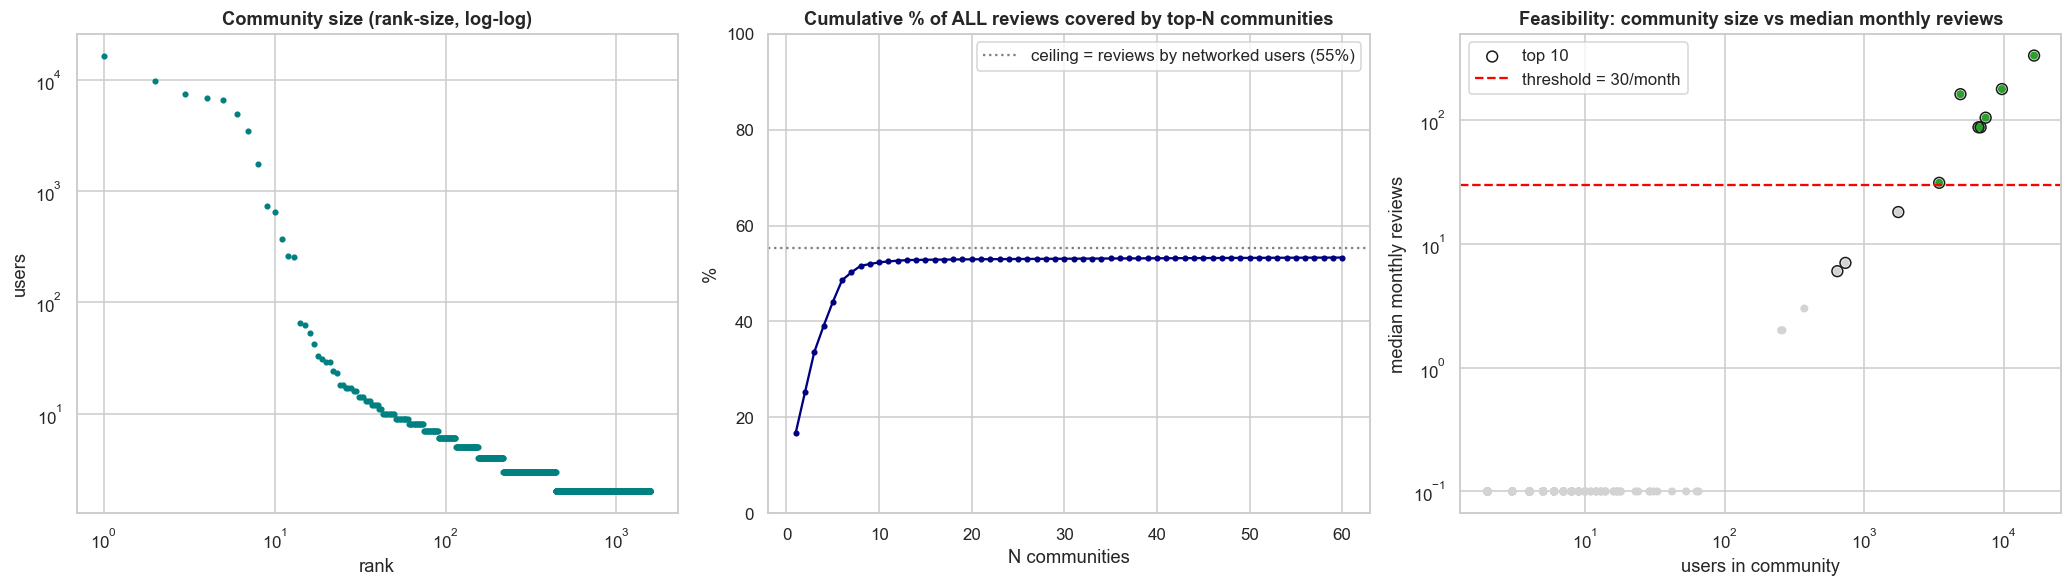

In [57]:
comms_l = sorted(louvain_communities(G, resolution=LOUVAIN_RESOLUTION, seed=SEED), key=len, reverse=True)
node2comm = {u: i for i, c in enumerate(comms_l) for u in c}
Q = modularity(G, comms_l)
ca_users['community'] = ca_users['user_id'].map(node2comm)
ca_reviews['community'] = ca_reviews['user_id'].map(node2comm)
print(f"Louvain: {len(comms_l):,} communities | modularity Q = {Q:.3f} | top-10 sizes = {[len(c) for c in comms_l[:10]]}")

# internal-edge fraction per community
E['ca'] = E['a'].map(node2comm); E['cb'] = E['b'].map(node2comm)
internal = E[E['ca'] == E['cb']].groupby('ca').size()
endpoints = pd.concat([E['ca'], E['cb']]).value_counts()
intra_frac = (2 * internal / endpoints).reindex(range(len(comms_l))).fillna(0)

# monthly series of ALL communities inside the analysis window -> feasibility
g_net = g[g['user_id'].isin(node2comm)].copy(); g_net['community'] = g_net['user_id'].map(node2comm).astype(int)
cm = g_net.groupby(['month', 'community']).size().unstack(fill_value=0).reindex(idx, fill_value=0)
cstat = pd.DataFrame({'users': pd.Series({i: len(c) for i, c in enumerate(comms_l)}),
                      'reviews_in_window': cm.sum(), 'median_monthly': cm.median(), 'share_nonzero_months': (cm > 0).mean(),
                      'intra_edge_frac': intra_frac}).fillna(0)
cstat['share_of_all_reviews_%'] = cstat['reviews_in_window'] / len(g) * 100
cstat['forecastable'] = (cstat['median_monthly'] >= MIN_MEDIAN_MONTHLY) & (cstat['share_nonzero_months'] >= .9)
topk = cstat.sort_values('reviews_in_window', ascending=False).head(TOP_K).index.tolist()

# what is each top community?  (dominant city / macro-category = does the community mirror geography?)
desc = []
for c in topk:
    gc = g_net[g_net['community'] == c]
    desc.append({'community': c, 'top_city': gc['city'].value_counts().index[0], 'top_city_share': gc['city'].value_counts(normalize=True).iloc[0],
                 'top_macro': gc['macro_cat'].value_counts().index[0], 'top_macro_share': gc['macro_cat'].value_counts(normalize=True).iloc[0],
                 'mean_stars': gc['stars'].mean(), 'mean_degree': ca_users.loc[ca_users['community'] == c, 'degree'].mean(),
                 'median_join_year': ca_users.loc[ca_users['community'] == c, 'join_year'].median()})
tab = cstat.loc[topk, ['users', 'reviews_in_window', 'share_of_all_reviews_%', 'median_monthly', 'share_nonzero_months', 'intra_edge_frac', 'forecastable']].join(pd.DataFrame(desc).set_index('community'))
display(tab.round(2))

n_feas = int(cstat['forecastable'].sum()); cov = cstat.loc[cstat['forecastable'], 'reviews_in_window'].sum() / len(g) * 100
print(f"\nForecastable communities (median >= {MIN_MEDIAN_MONTHLY}/month and >=90% non-zero months): {n_feas} -> cover {cov:.1f}% of ALL reviews in the window")
for thr in (10, 30, 100): print(f"  median monthly >= {thr:>3}: {int((cstat['median_monthly'] >= thr).sum())} communities")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
axes[0].loglog(range(1, len(comms_l) + 1), [len(c) for c in comms_l], '.', color='teal'); axes[0].set_title('Community size (rank-size, log-log)'); axes[0].set_xlabel('rank'); axes[0].set_ylabel('users')
cum = cstat['reviews_in_window'].sort_values(ascending=False).cumsum().values / len(g) * 100
axes[1].plot(range(1, min(len(cum), 60) + 1), cum[:60], 'o-', ms=3, color='navy'); axes[1].set_ylim(0, 100)
axes[1].set_title('Cumulative % of ALL reviews covered by top-N communities'); axes[1].set_xlabel('N communities'); axes[1].set_ylabel('%')
axes[1].axhline(rev_in_G * 100, color='gray', ls=':', label=f'ceiling = reviews by networked users ({rev_in_G * 100:.0f}%)'); axes[1].legend()
cs_ = cstat[cstat['reviews_in_window'] > 0]
axes[2].scatter(cs_['users'], cs_['median_monthly'].clip(lower=.1), s=18, c=np.where(cs_['forecastable'], 'tab:green', 'lightgray'))
axes[2].scatter(cstat.loc[topk, 'users'], cstat.loc[topk, 'median_monthly'].clip(lower=.1), s=50, facecolors='none', edgecolors='k', label=f'top {TOP_K}')
axes[2].axhline(MIN_MEDIAN_MONTHLY, color='red', ls='--', label=f'threshold = {MIN_MEDIAN_MONTHLY}/month'); axes[2].set_xscale('log'); axes[2].set_yscale('log')
axes[2].set_title('Feasibility: community size vs median monthly reviews'); axes[2].set_xlabel('users in community'); axes[2].set_ylabel('median monthly reviews'); axes[2].legend()
plt.tight_layout(); plt.show()

## 5. Network × time

### Community-level time series
The core objects of the project. For each of the top-K communities: the raw monthly series, how strongly seasonal / trending it is, and how much it moves **independently** of the rest of the network (if every community just mirrors the global series, community-specific models add little over one global model).

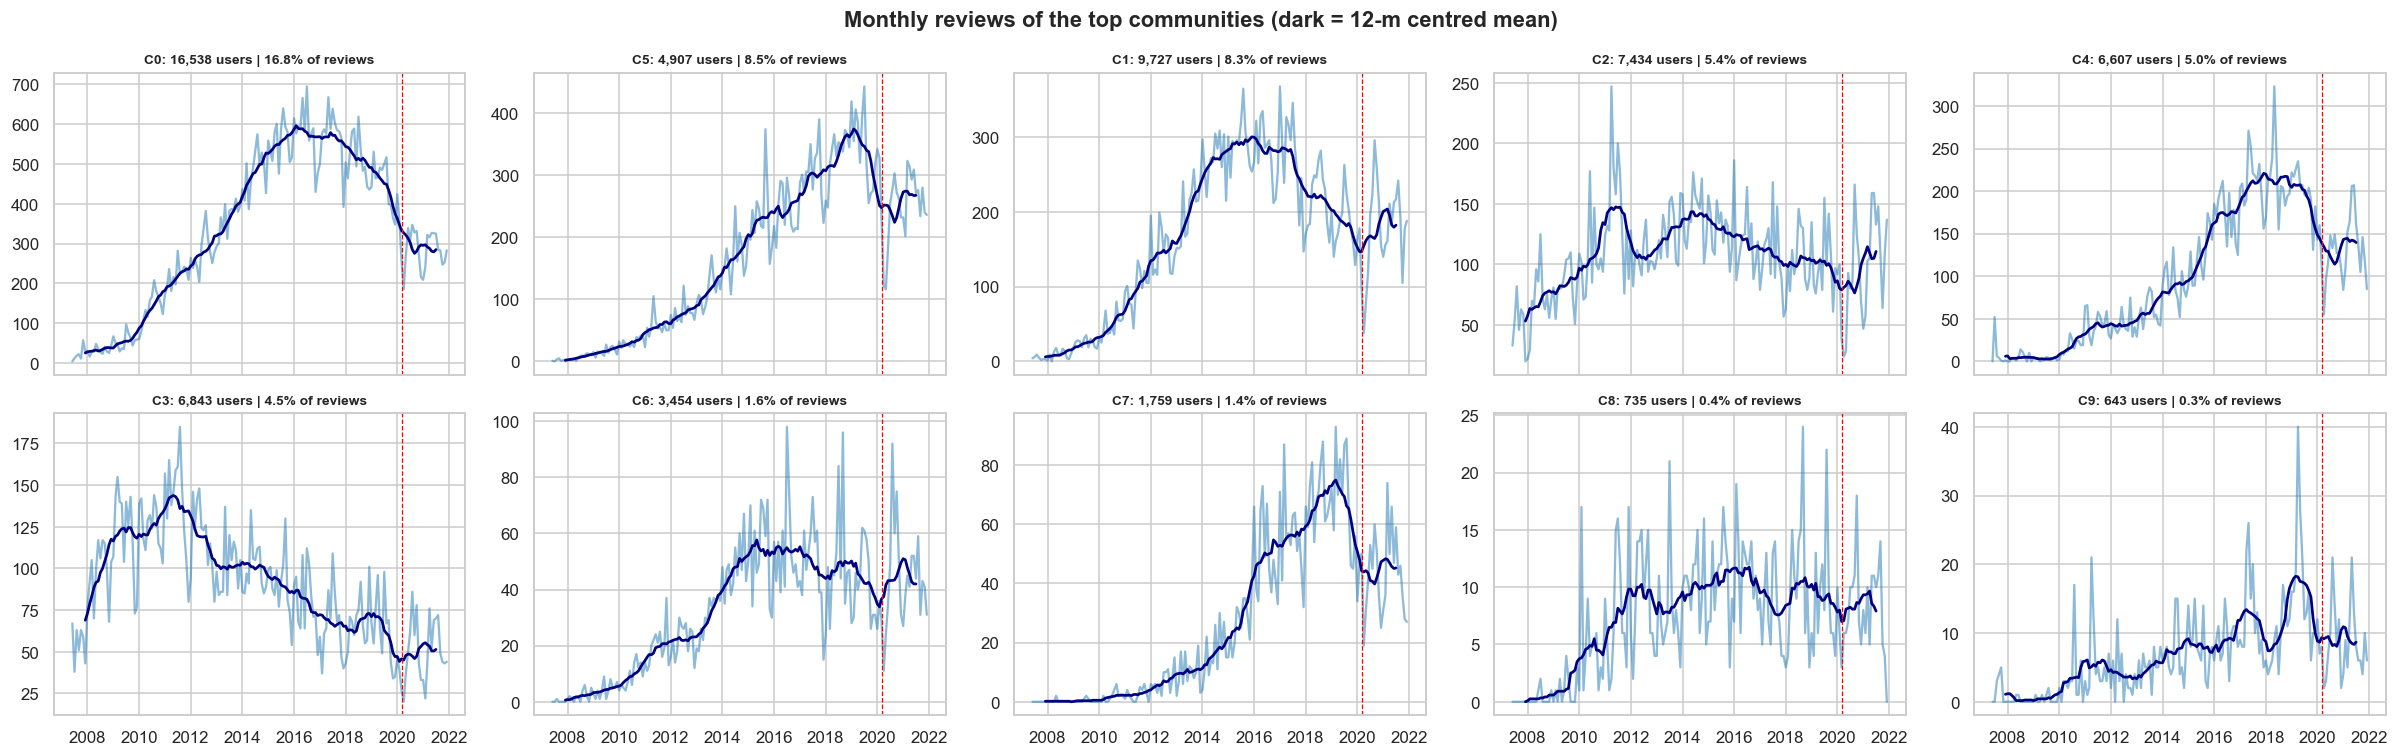

,F_trend,F_season,corr_d1_vs_rest,corr_d1_d12_vs_rest
community,,,,
0,0.96,0.12,0.29,0.22
5,0.97,0.18,0.15,0.05
1,0.94,0.19,0.00,0.05
2,0.60,0.31,0.36,0.22
4,0.94,0.38,-0.09,-0.33
3,0.80,0.55,0.22,0.09
6,0.94,0.30,0.26,0.34
7,0.95,0.19,0.23,0.14
8,0.81,0.36,0.07,0.05


Global (all reviews) for reference: F_trend = 0.97, F_season = 0.36


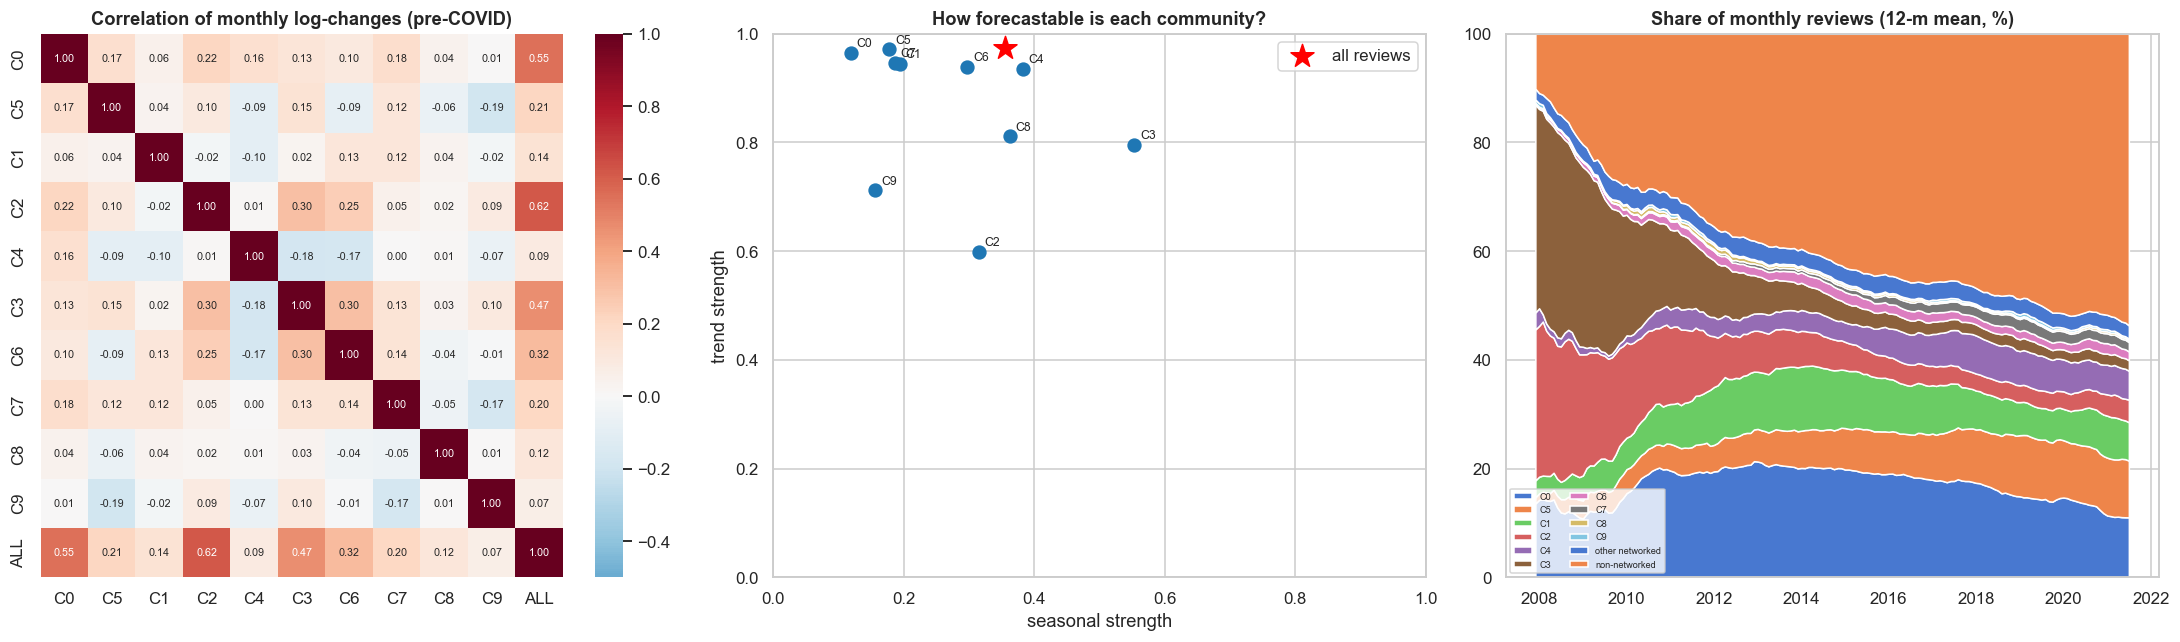

In [58]:
cmk = cm[topk]; total_net = cm.sum(axis=1)
fig, axes = plt.subplots(2, 5, figsize=(22, 7), sharex=True)
for ax, c in zip(axes.ravel(), topk):
    s = cmk[c]; ax.plot(s.index, s.values, color='tab:blue', alpha=.5); ax.plot(s.index, s.rolling(12, center=True).mean(), color='navy', lw=1.8)
    ax.axvline(COVID_START, color='red', ls='--', lw=.8)
    ax.set_title(f"C{c}: {len(comms_l[c]):,} users | {cstat.loc[c, 'share_of_all_reviews_%']:.1f}% of reviews", fontsize=9)
plt.suptitle('Monthly reviews of the top communities (dark = 12-m centred mean)', fontweight='bold'); plt.tight_layout(); plt.show()

# strengths + independence from the rest of the network (pre-COVID, log1p scale)
pre_idx = y_pre.index; rows = []
for c in topk:
    s = np.log1p(cm.loc[pre_idx, c]); rest = np.log1p(total_net.loc[pre_idx] - cm.loc[pre_idx, c])
    res = STL(s, period=12, robust=True).fit(); Ft, Fs = strengths(res)
    rows.append({'community': c, 'F_trend': Ft, 'F_season': Fs, 'corr_d1_vs_rest': s.diff().corr(rest.diff()), 'corr_d1_d12_vs_rest': s.diff().diff(12).corr(rest.diff().diff(12))})
cstr = pd.DataFrame(rows).set_index('community')
display(cstr.round(2))
print(f"Global (all reviews) for reference: F_trend = {Ft_all:.2f}, F_season = {Fs_all:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
dd = pd.DataFrame({f'C{c}': np.log1p(cm.loc[pre_idx, c]).diff() for c in topk}); dd['ALL'] = np.log1p(y_pre).diff()
sns.heatmap(dd.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-.5, vmax=1, ax=axes[0], annot_kws={'size': 7})
axes[0].set_title('Correlation of monthly log-changes (pre-COVID)')
axes[1].scatter(cstr['F_season'], cstr['F_trend'], s=70, color='tab:blue')
for c, r in cstr.iterrows(): axes[1].annotate(f'C{c}', (r['F_season'], r['F_trend']), xytext=(4, 4), textcoords='offset points', fontsize=8)
axes[1].scatter([Fs_all], [Ft_all], marker='*', s=250, color='red', label='all reviews'); axes[1].legend()
axes[1].set_xlabel('seasonal strength'); axes[1].set_ylabel('trend strength'); axes[1].set_xlim(0, 1); axes[1].set_ylim(0, 1); axes[1].set_title('How forecastable is each community?')
sh = pd.DataFrame({f'C{c}': cm[c] for c in topk}); sh['other networked'] = total_net - sh.sum(axis=1); sh['non-networked'] = y - total_net
sh = sh.div(sh.sum(axis=1), axis=0).rolling(12, center=True).mean() * 100
axes[2].stackplot(sh.index, [sh[c] for c in sh.columns], labels=sh.columns); axes[2].set_ylim(0, 100); axes[2].legend(fontsize=6, ncol=2, loc='lower left')
axes[2].set_title('Share of monthly reviews (12-m mean, %)')
plt.tight_layout(); plt.show()

### Degree segments over time
Do well-connected users behave differently over time than peripheral or isolated users?

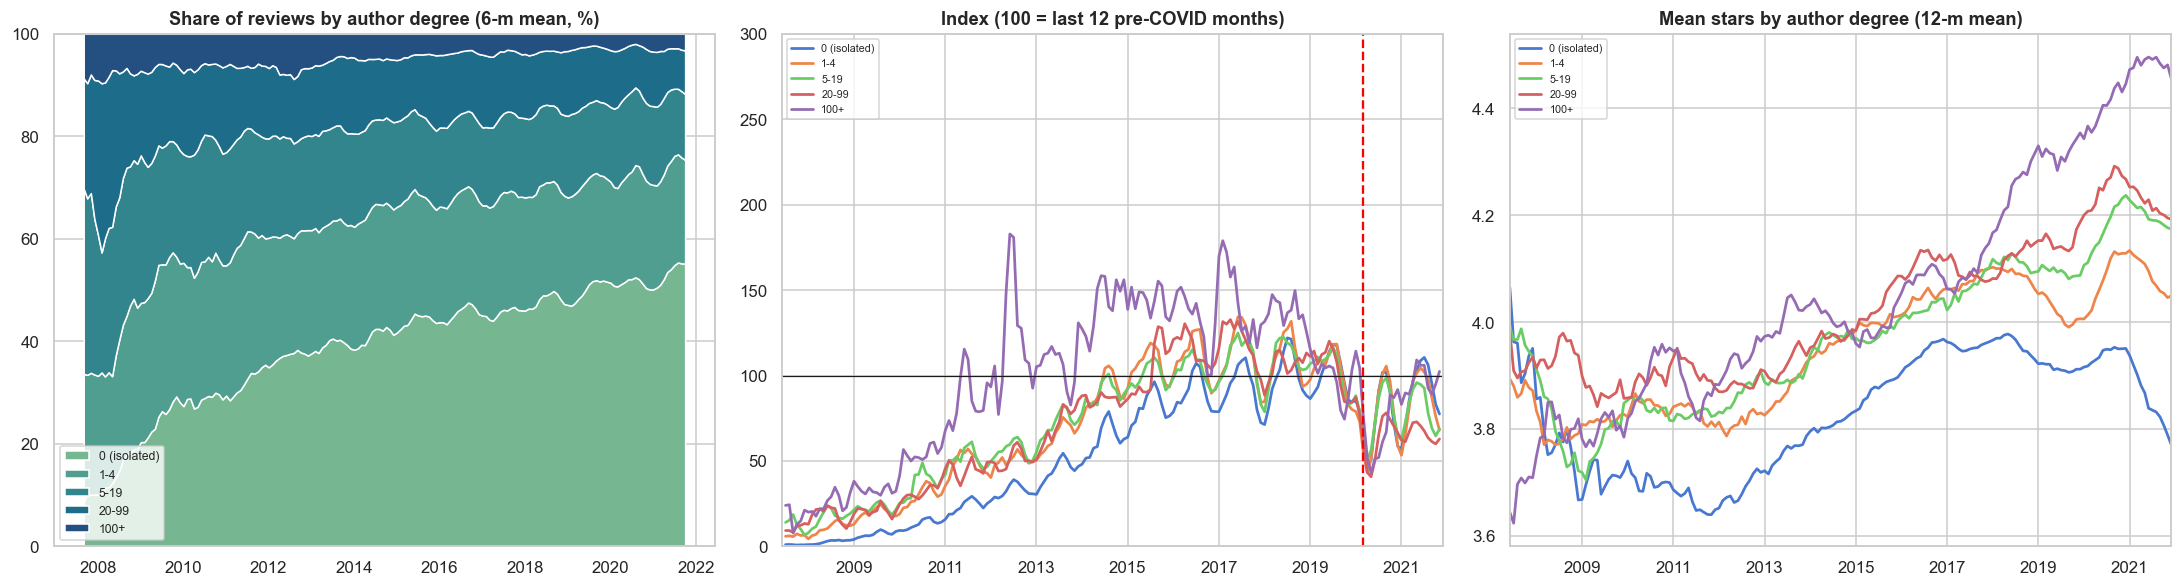

In [59]:
ca_users['deg_bucket'] = pd.cut(ca_users['degree'], [-1, 0, 4, 19, 99, np.inf], labels=['0 (isolated)', '1-4', '5-19', '20-99', '100+'])
g['deg_bucket'] = g['user_id'].map(ca_users.set_index('user_id')['deg_bucket'])
sg = g.groupby(['month', 'deg_bucket'], observed=True).size().unstack(fill_value=0).reindex(idx, fill_value=0)
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
shr = sg.div(sg.sum(axis=1), axis=0).rolling(6, center=True).mean() * 100
axes[0].stackplot(idx, [shr[c] for c in shr.columns], labels=shr.columns, colors=sns.color_palette('crest', 5)); axes[0].set_ylim(0, 100); axes[0].legend(loc='lower left', fontsize=8)
axes[0].set_title('Share of reviews by author degree (6-m mean, %)')
(sg.div(sg.loc[BASE.index].mean()) * 100).rolling(3, center=True).mean().plot(ax=axes[1], lw=1.8); axes[1].axhline(100, color='k', lw=.8)
axes[1].axvline(COVID_START, color='red', ls='--'); axes[1].set_ylim(0, 300); axes[1].set_title('Index (100 = last 12 pre-COVID months)'); axes[1].legend(fontsize=7)
ms = g.groupby(['month', 'deg_bucket'], observed=True)['stars'].mean().unstack().reindex(idx).rolling(12, center=True, min_periods=6).mean()
ms.plot(ax=axes[2], lw=1.8); axes[2].set_title('Mean stars by author degree (12-m mean)'); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Influence feasibility: do friends review the same place shortly after each other?
Yelp has no explicit cascades, so the **proxy** is: *user v reviews business b some days after a friend u reviewed b* ("friend exposure"). This cell is a **screening check** (is there enough data, and a signal above chance?), not a causal test:
- It cannot separate *influence* from *homophily / joint visits* (slide: homophily); same-day pairs are reported separately for that reason.
- Null model: dates are shuffled **within each business** (same reviewers, same business popularity, same date distribution), repeated `N_PERM` times.

,observed_%,null_mean_%,null_sd,ratio
same day,0.527,0.038,0.003,14.032
1-7 days,0.963,0.311,0.014,3.100
8-30 days,1.350,0.771,0.025,1.752
31-90 days,2.029,1.505,0.020,1.348
>90 days,12.090,13.779,0.034,0.877


Eligible reviews (networked authors at businesses with >=2 networked reviewers): 192,457  |  businesses: 4,969
Reviews preceded by a friend's review of the same place: 16.96%  | within 1-30 days: 2.31%   (runtime 7s)


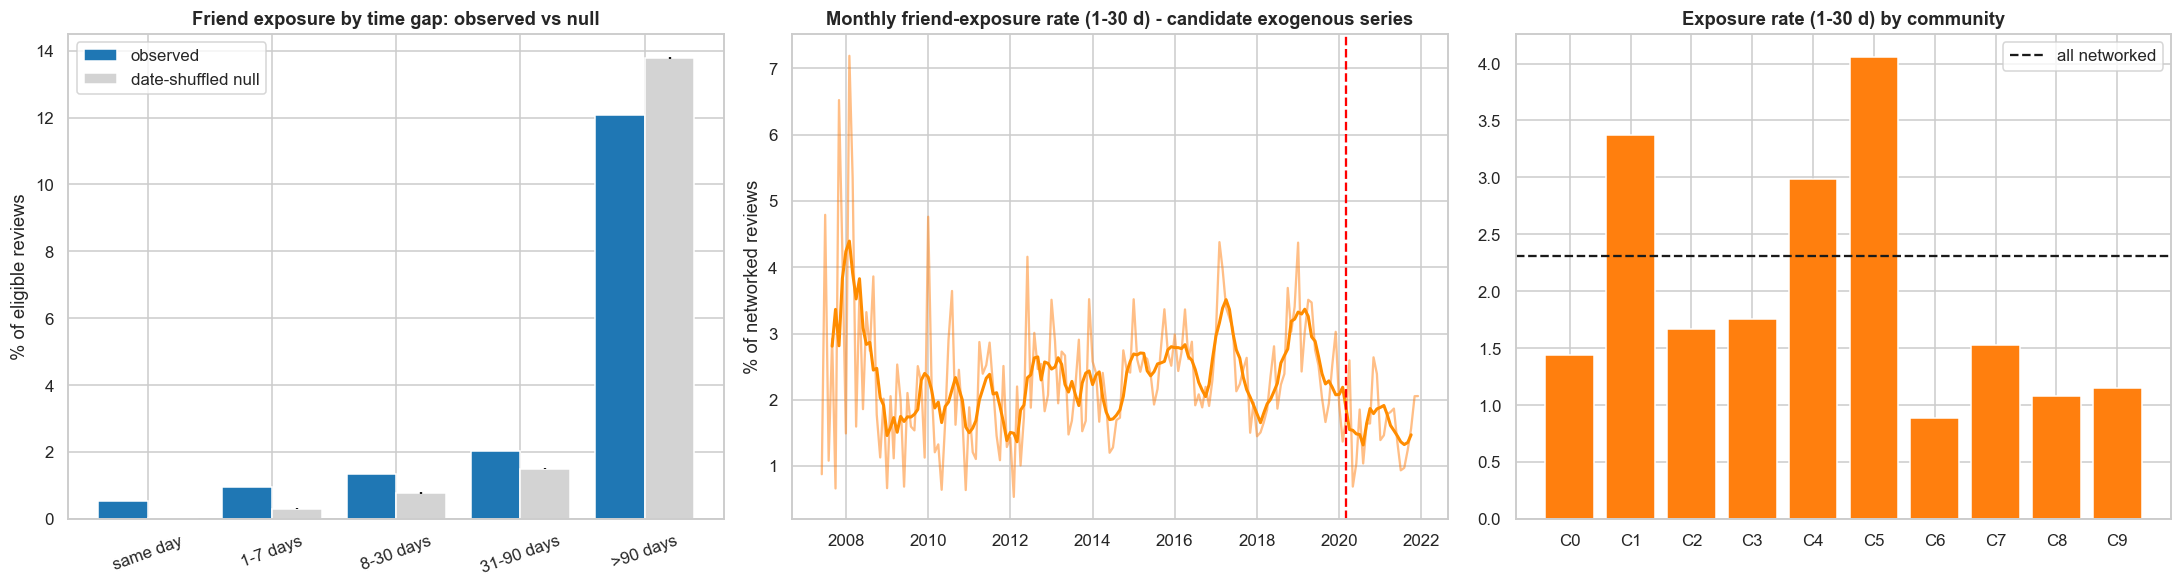

In [60]:
import time
t0 = time.time()
uid2i = {u: i for i, u in enumerate(ca_users['user_id'])}
adj = {uid2i[u]: {uid2i[v] for v in G.neighbors(u)} for u in G.nodes}

net = ca_reviews.loc[ca_reviews['user_id'].isin(G.nodes), ['user_id', 'business_id', 'date', 'month', 'community']].copy()
net['u'] = net['user_id'].map(uid2i).astype(np.int64)
net['b'] = pd.factorize(net['business_id'])[0]
net['d'] = (net['date'].dt.normalize() - pd.Timestamp('2000-01-01')).dt.days.astype(np.int64)
net = net[net.groupby('b')['u'].transform('size') >= 2].sort_values(['b', 'd']).reset_index(drop=True)

def friend_gap(u, b, d, adj):
    # for each review: days since the MOST RECENT earlier review of the same business by a friend (-1 = none)
    n = len(u); gap = np.full(n, -1, dtype=np.int64)
    cut = np.flatnonzero(np.diff(b)) + 1; starts = np.r_[0, cut]; ends = np.r_[cut, n]
    for s, e in zip(starts, ends):
        if e - s < 2: continue
        seen = {}
        for i in range(s, e):
            v = u[i]; nb = adj.get(v)
            if nb and seen:
                best = -1
                if len(nb) <= len(seen):
                    for f in nb:
                        t = seen.get(f)
                        if t is not None:
                            gg = d[i] - t
                            if best < 0 or gg < best: best = gg
                else:
                    for f, t in seen.items():
                        if f in nb:
                            gg = d[i] - t
                            if best < 0 or gg < best: best = gg
                gap[i] = best
            seen[v] = d[i]
    return gap

u_, b_, d_ = net['u'].values, net['b'].values, net['d'].values
gap_obs = friend_gap(u_, b_, d_, adj)

rng = np.random.default_rng(SEED); gaps_null = []
for _ in range(N_PERM):
    d_p = d_[np.lexsort((rng.random(len(b_)), b_))]          # shuffle dates inside each business
    o = np.lexsort((d_p, b_)); gaps_null.append(friend_gap(u_[o], b_[o], d_p[o], adj))

BUCKETS = [('same day', 0, 0), ('1-7 days', 1, 7), ('8-30 days', 8, 30), ('31-90 days', 31, 90), ('>90 days', 91, 10**9)]
def bucket_shares(gp):
    return pd.Series({n: ((gp >= lo_) & (gp <= hi_)).mean() * 100 for n, lo_, hi_ in BUCKETS})
obs = bucket_shares(gap_obs); nul = pd.DataFrame([bucket_shares(gp) for gp in gaps_null])
res = pd.DataFrame({'observed_%': obs, 'null_mean_%': nul.mean(), 'null_sd': nul.std(), 'ratio': obs / nul.mean()})
display(res.round(3))
print(f"Eligible reviews (networked authors at businesses with >=2 networked reviewers): {len(net):,}  |  businesses: {net['b'].nunique():,}")
print(f"Reviews preceded by a friend's review of the same place: {(gap_obs >= 0).mean() * 100:.2f}%  | within 1-30 days: {((gap_obs >= 1) & (gap_obs <= 30)).mean() * 100:.2f}%   (runtime {time.time() - t0:.0f}s)")

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
xx = np.arange(len(res)); axes[0].bar(xx - .2, res['observed_%'], .4, label='observed', color='tab:blue'); axes[0].bar(xx + .2, res['null_mean_%'], .4, yerr=res['null_sd'], label='date-shuffled null', color='lightgray')
axes[0].set_xticks(xx); axes[0].set_xticklabels(res.index, rotation=20); axes[0].set_ylabel('% of eligible reviews'); axes[0].legend(); axes[0].set_title('Friend exposure by time gap: observed vs null')
net['exp_1_30'] = (gap_obs >= 1) & (gap_obs <= 30)
exp_m = net.groupby('month')['exp_1_30'].mean().reindex(idx) * 100
axes[1].plot(idx, exp_m, color='tab:orange', alpha=.5); axes[1].plot(idx, exp_m.rolling(6, center=True).mean(), color='darkorange', lw=2); axes[1].axvline(COVID_START, color='red', ls='--')
axes[1].set_title('Monthly friend-exposure rate (1-30 d) - candidate exogenous series'); axes[1].set_ylabel('% of networked reviews')
ce = net[net['community'].isin(topk)].groupby('community')['exp_1_30'].mean() * 100
axes[2].bar([f'C{int(c)}' for c in ce.index], ce.values, color='tab:orange'); axes[2].axhline(net['exp_1_30'].mean() * 100, color='k', ls='--', label='all networked')
axes[2].set_title('Exposure rate (1-30 d) by community'); axes[2].legend()
plt.tight_layout(); plt.show()

## 6. Export for the modelling stage
Tidy tables with the series, candidate exogenous variables and network features, so forecasting notebooks can start from these files.

In [61]:
ts_overall = pd.DataFrame({'reviews': y, 'active_users': active_users, 'active_businesses': active_biz, 'new_users': new_users,
                           'mean_stars': mean_stars, 'covid_dummy': (idx >= COVID_START).astype(int),
                           'friend_exposure_1_30_pct': exp_m})
if checkin_monthly is not None: ts_overall['checkins'] = checkin_monthly
ts_overall.index.name = 'month'
ts_overall.to_csv(os.path.join(target_path, 'ts_monthly_overall.csv'))
cm_out = cm[topk].copy(); cm_out.columns = [f'C{c}' for c in topk]; cm_out.index.name = 'month'
cm_out.to_csv(os.path.join(target_path, 'ts_monthly_top_communities.csv'))
ca_users[['user_id', 'degree', 'pagerank', 'core', 'community', 'ca_review_count', 'is_elite_ever', 'visitor_like', 'join_year']] \
    .to_parquet(os.path.join(target_path, 'yelp_ca_user_network_features.parquet'), index=False)
cstat.to_csv(os.path.join(target_path, 'community_feasibility.csv'))

print("Saved: ts_monthly_overall.csv, ts_monthly_top_communities.csv, community_feasibility.csv, yelp_ca_user_network_features.parquet\n")
print("=" * 60); print("KEY FACTS TO BRING BACK"); print("=" * 60)
print(f"Window            : {TS_START:%Y-%m} -> {TS_END:%Y-%m} ({len(y)} months); pre-COVID {len(y_pre)} months")
print(f"Seasonality       : F_season = {Fs_all:.2f}, F_trend = {Ft_all:.2f}; peak {MONTHS[int(si.idxmax()) - 1]}, trough {MONTHS[int(si.idxmin()) - 1]} (ratio {si.max() / si.min():.2f})")
print("Stationarity      :", {k: v for k, v in st['verdict'].items()})
print(f"Graph             : {G.number_of_nodes():,} nodes / {G.number_of_edges():,} edges, LCC {len(lcc) / G.number_of_nodes() * 100:.1f}%, reviews covered {rev_in_G * 100:.0f}%")
print(f"Communities       : {len(comms_l):,} (Q = {Q:.2f}); forecastable (median >= {MIN_MEDIAN_MONTHLY}/month): {n_feas}, covering {cov:.1f}% of all reviews")
print(f"Friend exposure   : {(gap_obs >= 1).mean() * 100:.2f}% of networked reviews follow a friend's review; observed/null ratio: 1-7 d = {res.loc['1-7 days', 'ratio']:.2f}, 8-30 d = {res.loc['8-30 days', 'ratio']:.2f}")

Saved: ts_monthly_overall.csv, ts_monthly_top_communities.csv, community_feasibility.csv, yelp_ca_user_network_features.parquet

KEY FACTS TO BRING BACK
Window            : 2007-06 -> 2021-12 (175 months); pre-COVID 153 months
Seasonality       : F_season = 0.36, F_trend = 0.97; peak Jul, trough Feb (ratio 1.46)
Stationarity      : {'raw level': 'non-stationary', 'log': 'non-stationary', 'raw  d=1': 'conflicting', 'log  d=1': 'non-stationary', 'log  D=1 (lag 12)': 'non-stationary', 'log  d=1 & D=1': 'stationary'}
Graph             : 64,135 nodes / 470,965 edges, LCC 96.3%, reviews covered 55%
Communities       : 1,580 (Q = 0.52); forecastable (median >= 30/month): 7, covering 50.2% of all reviews
Friend exposure   : 16.43% of networked reviews follow a friend's review; observed/null ratio: 1-7 d = 3.10, 8-30 d = 1.75


## 7. Time-series modelling

Everything below uses objects created in sections 1-6 (`y`, `y_pre`, `idx`, `g`, `cm`, `cat_m`, `exp_m`, ...) - run those first.

**Design decisions (driven by the diagnostics above)**
- Trend is very strong (F_T ~ 0.97) and the series needs `log`, `d=1`, `D=1` -> SARIMA is fitted on **log reviews** with `d=1, D=1`.
- COVID is a structural break and only 22 post-COVID months exist, so models are **back-tested on the pre-COVID window** (rolling origin, 12-month horizon). COVID is then analysed separately as an *intervention* (counterfactual forecast).
- 175 monthly points are too few for a neural net on one series. The ML models (gradient boosting, MLP) are therefore used where they have enough data: **weekly** data (section 7.5) and **panels of communities** (section 9).
- Every model must beat the **seasonal-naive** baselines to count. Errors are reported as RMSE / MAE / MAPE / **MASE** (MASE < 1 = better than in-sample seasonal naive).
- Any new exogenous series (friend exposure, check-ins) is used **lagged**, because it is computed from the same reviews we forecast (otherwise it leaks the target).

In [62]:
# ---------- parameters for sections 7-10 (edit here) ----------
H              = 12                          # forecast horizon (months)
CV_STEP        = 6                           # months between forecast origins
PRE_TEST_START = pd.Timestamp('2016-01-01')  # first back-test origin (pre-COVID); everything before is training data
FAST           = True                        # True = smaller samples (minutes); False = fuller runs
BETW_K         = 200 if FAST else 1000       # BFS sources for approximate betweenness
N_CASES        = 40_000 if FAST else 250_000 # sampled reviews for the friend-influence case-control study
N_LP           = 10_000 if FAST else 40_000  # held-out edges per split for link prediction
N_BIZ_GRAPH    = 1500                        # businesses in the co-review (bipartite projection) graph
RESULTS        = {}                          # tables collected for the summary in section 10

import itertools, random
from itertools import product
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, normalized_mutual_info_score, adjusted_rand_score
from sklearn.inspection import permutation_importance
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.forecasting.stl import STLForecast
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import grangercausalitytests
from statsmodels.stats.multitest import multipletests

try:                                          # XGBoost if installed, otherwise scikit-learn's gradient boosting
    from xgboost import XGBRegressor, XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
GBM_NAME = 'XGBoost' if HAS_XGB else 'GradientBoosting (sklearn)'

def make_gbm():
    if HAS_XGB:
        return XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                            min_child_weight=3, random_state=SEED, n_jobs=-1, verbosity=0)
    return HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, min_samples_leaf=10,
                                         l2_regularization=1.0, random_state=SEED)

def make_gbm_clf():
    if HAS_XGB:
        return XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                             random_state=SEED, n_jobs=-1, verbosity=0, eval_metric='logloss')
    return HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=SEED)

class MLPEnsemble:
    """Small feed-forward ANN, averaged over several seeds (single MLPs are unstable on small data)."""
    def __init__(self, n=5, hidden=(32, 16)): self.n, self.hidden = n, hidden
    def fit(self, X, y):
        self.sc = StandardScaler().fit(X); Xs = self.sc.transform(X)
        self.ms = [MLPRegressor(hidden_layer_sizes=self.hidden, alpha=1e-2, early_stopping=True, n_iter_no_change=20, max_iter=1000,
                                random_state=SEED + i).fit(Xs, y) for i in range(self.n)]
        return self
    def predict(self, X):
        Xs = self.sc.transform(X); return np.mean([m.predict(Xs) for m in self.ms], axis=0)

print(f"Gradient boosting backend: {GBM_NAME}")

Gradient boosting backend: GradientBoosting (sklearn)


### 7.1 Forecast framework: baselines, ETS, STL+ARIMA, SARIMA (rolling-origin back-test)
Forecast origins are every `CV_STEP` months from `PRE_TEST_START` while the 12-month test window still ends before COVID. At each origin the model is re-fitted on all earlier data (expanding window). The SARIMA order is chosen **once**, by AIC on data up to the first origin only, so the test period never influences model selection.

7 forecast origins: 2016-01 ... 2019-01  (horizon 12 months, training starts 2007-06)
SARIMA grid (36 models fitted, 19s). Best by AIC on data up to 2016-01: (0, 1, 2)x(0, 1, 1, 12)


,p,d,q,P,D,Q,aic,bic
0,0,1,2,0,1,1,-145.1,-135.8
1,0,1,1,0,1,1,-143.4,-136.4
2,1,1,2,0,1,1,-142.7,-131.0
3,2,1,2,1,1,1,-142.6,-126.3
4,2,1,2,0,1,1,-142.1,-128.2


,RMSE,MAE,MAPE_pct,MASE,MASE h1-3,MASE h4-6,MASE h7-12
model,,,,,,,
Seasonal naive,285.178,223.702,7.356,0.657,0.559,0.788,0.640
Seasonal naive + drift,381.842,304.980,10.209,0.886,0.650,0.876,1.009
"ETS (damped trend, additive seasonal)",386.120,312.966,10.299,0.915,0.622,0.793,1.123
"SARIMA(0, 1, 2)x(0, 1, 1, 12)",501.109,424.731,13.932,1.242,0.739,1.128,1.550
"SARIMA airline (0,1,1)x(0,1,1,12)",510.298,432.535,14.190,1.263,0.746,1.144,1.581
Naive,722.828,598.643,19.631,1.761,1.226,2.616,1.600
"STL + ARIMA(1,1,1) with drift",903.338,753.390,24.510,2.199,0.886,1.616,3.146


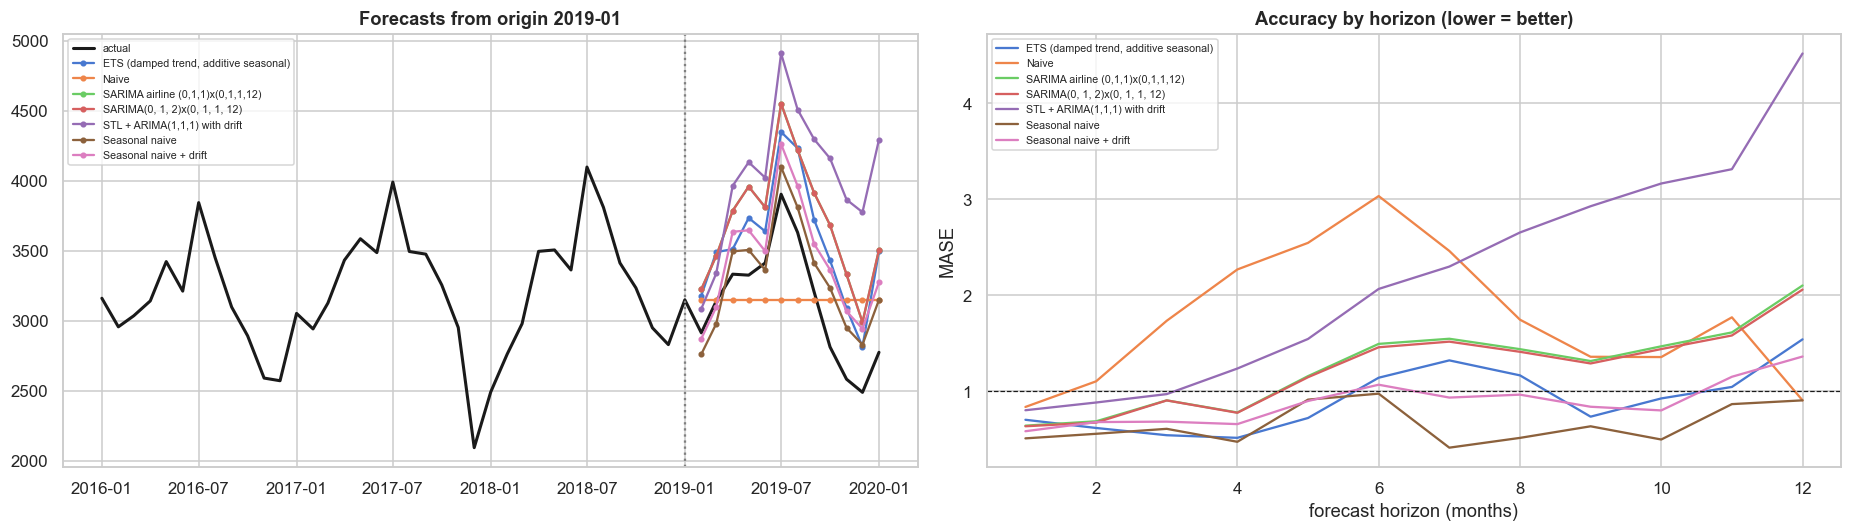

In [63]:
# ---------- metrics & back-test machinery ----------
def mase_scale(s, m=12):
    v = np.asarray(s, float); return np.mean(np.abs(v[m:] - v[:-m]))

def add_rows(rows, name, o, train, test, fc):
    sc = mase_scale(train)
    for h, (dt, a, p) in enumerate(zip(test.index, test.values, np.asarray(fc, float)), 1):
        rows.append(dict(model=name, origin=o, h=h, date=dt, actual=a, forecast=p, scale=sc))

def backtest(models, series, origins, H, floor=1.0):
    """models: {name: f(log_train_series, H) -> array of H log-forecasts}. Returns a long table of forecasts."""
    rows = []
    for o in origins:
        train = series.loc[:o]; test = series.loc[o + pd.DateOffset(months=1): o + pd.DateOffset(months=H)]
        lt = np.log(train.clip(lower=floor))
        for name, f in models.items():
            try:
                add_rows(rows, name, o, train, test, np.exp(np.asarray(f(lt, H), float))[:len(test)])
            except Exception as ex:
                print(f"  [{name}] failed at origin {o:%Y-%m}: {type(ex).__name__}: {ex}")
    return pd.DataFrame(rows)

def summarise(bt):
    b = bt.assign(err=bt['actual'] - bt['forecast']); b['ae'] = b['err'].abs()
    b['ape'] = b['ae'] / b['actual'] * 100; b['ase'] = b['ae'] / b['scale']
    b['horizon'] = np.select([b['h'] <= 3, b['h'] <= 6], ['MASE h1-3', 'MASE h4-6'], 'MASE h7-12')   # plain strings, not a categorical
    out = b.groupby('model').agg(RMSE=('err', lambda e: np.sqrt((e ** 2).mean())), MAE=('ae', 'mean'), MAPE_pct=('ape', 'mean'), MASE=('ase', 'mean'))
    byh = b.groupby(['model', 'horizon'])['ase'].mean().unstack('horizon')
    byh = byh.reindex(columns=[c for c in ['MASE h1-3', 'MASE h4-6', 'MASE h7-12'] if c in byh.columns])
    return out.join(byh).sort_values('MASE')

# ---------- forecasting functions: f(log_train, H) -> log forecasts ----------
def f_naive(l, H):  return np.repeat(l.values[-1], H)
def f_snaive(l, H): return np.resize(l.values[-12:], H)
def f_snaive_drift(l, H):
    growth = l.values[-12:].mean() - l.values[-24:-12].mean()          # yearly growth of the log level
    return np.resize(l.values[-12:], H) + growth * (np.arange(H) // 12 + 1)
def f_ets(l, H):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        r = ExponentialSmoothing(l, trend='add', damped_trend=True, seasonal='add', seasonal_periods=12,
                                 initialization_method='estimated').fit()
    return np.asarray(r.forecast(H))
def f_stl_arima(l, H):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        r = STLForecast(l, ARIMA, model_kwargs=dict(order=(1, 1, 1), trend='t'), period=12, robust=True).fit()
    return np.asarray(r.forecast(H))
def make_f_sarima(order, seas):
    def f(l, H):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            r = SARIMAX(l, order=order, seasonal_order=seas,
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
        return np.asarray(r.get_forecast(H).predicted_mean)
    return f

def select_sarima(l, d=1, D=1, ps=(0, 1, 2), qs=(0, 1, 2), Ps=(0, 1), Qs=(0, 1)):
    """AIC grid search with d, D fixed by the stationarity analysis (log, d=1, D=1)."""
    rows = []
    for p, q, P, Q in product(ps, qs, Ps, Qs):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                r = SARIMAX(l, order=(p, d, q), seasonal_order=(P, D, Q, 12),
                            enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
            rows.append(dict(p=p, d=d, q=q, P=P, D=D, Q=Q, aic=r.aic, bic=r.bic))
        except Exception:
            continue
    tab = pd.DataFrame(rows).sort_values('aic').reset_index(drop=True)
    b = tab.iloc[0]
    return tab, (int(b.p), d, int(b.q)), (int(b.P), D, int(b.Q), 12)

# ---------- forecast origins ----------
last_pre = y_pre.index[-1]
origins = [o for o in y_pre.index if o >= PRE_TEST_START and o + pd.DateOffset(months=H) <= last_pre][::CV_STEP]
assert len(origins) > 0, "No back-test origins: lower PRE_TEST_START or H."
print(f"{len(origins)} forecast origins: {origins[0]:%Y-%m} ... {origins[-1]:%Y-%m}  (horizon {H} months, training starts {y.index[0]:%Y-%m})")

t0 = time.time()
sel_tab, SAR_ORD, SAR_SEAS = select_sarima(np.log(y.loc[:origins[0]]))
print(f"SARIMA grid ({len(sel_tab)} models fitted, {time.time() - t0:.0f}s). Best by AIC on data up to {origins[0]:%Y-%m}: {SAR_ORD}x{SAR_SEAS}")
display(sel_tab.head(5).round(1))

models = {
    'Naive': f_naive,
    'Seasonal naive': f_snaive,
    'Seasonal naive + drift': f_snaive_drift,
    'ETS (damped trend, additive seasonal)': f_ets,
    'STL + ARIMA(1,1,1) with drift': f_stl_arima,
    f'SARIMA{SAR_ORD}x{SAR_SEAS}': make_f_sarima(SAR_ORD, SAR_SEAS),
    'SARIMA airline (0,1,1)x(0,1,1,12)': make_f_sarima((0, 1, 1), (0, 1, 1, 12)),
}
bt = backtest(models, y, origins, H)
res_ts = summarise(bt)
RESULTS['ts_monthly_backtest'] = res_ts
display(res_ts.round(3))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
o_last = origins[-1]; seg = bt[bt['origin'] == o_last]
axes[0].plot(y.loc[o_last - pd.DateOffset(months=36):o_last + pd.DateOffset(months=H)], color='k', lw=2, label='actual')
for m_, grp_ in seg.groupby('model'): axes[0].plot(grp_['date'], grp_['forecast'], marker='o', ms=3, label=m_)
axes[0].axvline(o_last, color='gray', ls=':'); axes[0].legend(fontsize=7); axes[0].set_title(f'Forecasts from origin {o_last:%Y-%m}')
for m_, grp_ in bt.groupby('model'): axes[1].plot(grp_.groupby('h')['forecast'].size().index, (grp_.assign(a=(grp_['actual'] - grp_['forecast']).abs() / grp_['scale']).groupby('h')['a'].mean()), label=m_)
axes[1].axhline(1, color='k', lw=.8, ls='--'); axes[1].set_xlabel('forecast horizon (months)'); axes[1].set_ylabel('MASE'); axes[1].set_title('Accuracy by horizon (lower = better)'); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 7.2 COVID as an intervention: counterfactual forecast
Fit SARIMA on the pre-COVID window only, forecast the COVID/post-COVID months, and read the gap between *actual* and *counterfactual* as the pandemic effect (lost reviews, trough, recovery). Repeated per macro-category with a fixed "airline" model. Caveat: the counterfactual extrapolates 2-4 years of pre-COVID growth, so the uncertainty band widens quickly - treat the by-category *ranking* as more reliable than the absolute levels.

Counterfactual model (pre-COVID, AIC): SARIMA(0, 1, 2)x(0, 1, 1, 12)
Reviews lost vs. counterfactual: 14,164  (21% of expected)
Trough (3-month avg): 47% of expected, in 2020-05
Back to >=95% of counterfactual: 2020-10
Last 6 months actual / counterfactual: 84%


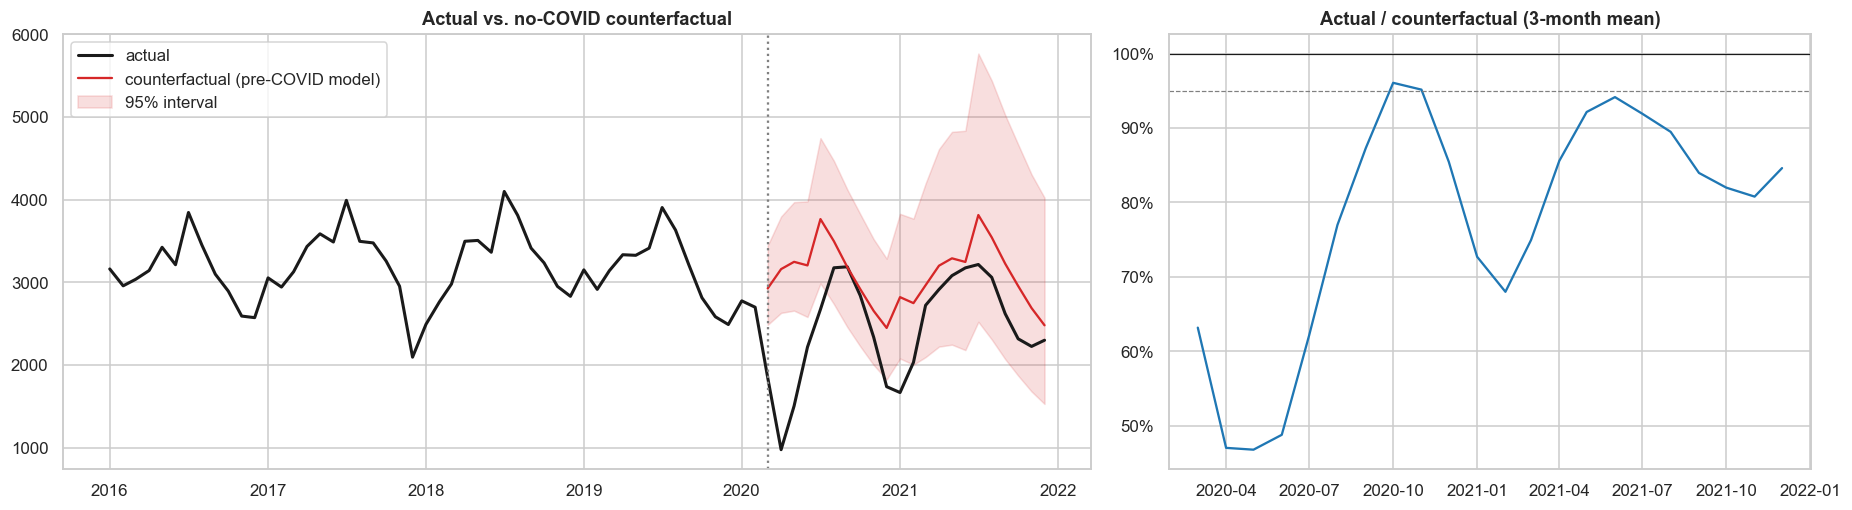

,spring_2020,trough,last_6m,months_below_90,recovered
category,,,,,
Beauty & Spas,26%,18%,65%,22,False
Arts & Entertainment,37%,25%,63%,22,False
Nightlife & Bars,41%,34%,83%,17,False
Hotels & Travel,48%,32%,84%,14,False
Restaurants,54%,48%,84%,17,False
Food (other),56%,49%,79%,17,False
Active Life,58%,49%,73%,16,False
Health & Medical,66%,57%,77%,20,False
Automotive,67%,49%,73%,12,False


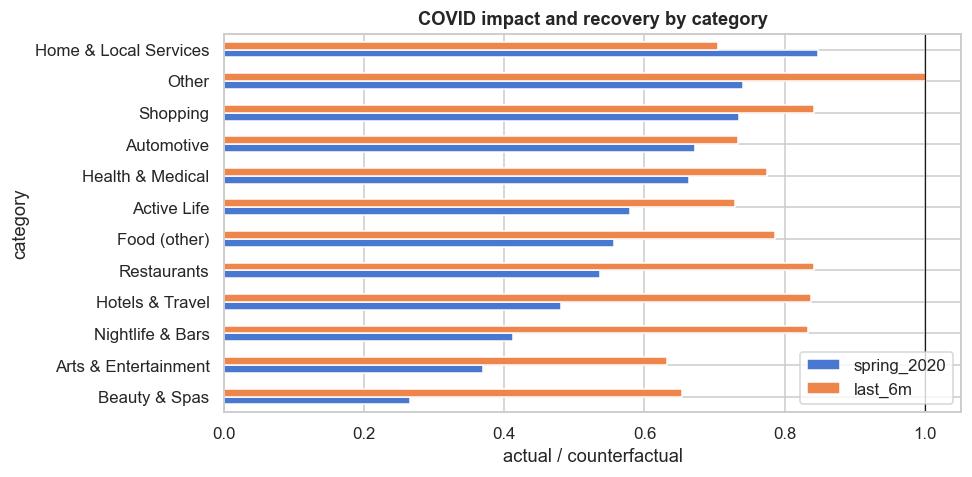

In [64]:
cf_tab, CF_ORD, CF_SEAS = select_sarima(np.log(y_pre))
print(f"Counterfactual model (pre-COVID, AIC): SARIMA{CF_ORD}x{CF_SEAS}")
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    cf_fit = SARIMAX(np.log(y_pre), order=CF_ORD, seasonal_order=CF_SEAS, enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
post_idx = y.index[len(y_pre):]
fc = cf_fit.get_forecast(len(post_idx))
cf = pd.Series(np.exp(np.asarray(fc.predicted_mean)), index=post_idx)
ci = np.exp(np.asarray(fc.conf_int(alpha=0.05)))
cf_lo, cf_hi = pd.Series(ci[:, 0], index=post_idx), pd.Series(ci[:, 1], index=post_idx)
act = y.loc[post_idx]; ratio = act / cf; ratio3 = ratio.rolling(3, min_periods=1).mean()
trough_m = ratio3.idxmin()
rec = ratio3[(ratio3.index > trough_m) & (ratio3 >= 0.95)]
print(f"Reviews lost vs. counterfactual: {(cf - act).sum():,.0f}  ({(cf.sum() - act.sum()) / cf.sum():.0%} of expected)")
print(f"Trough (3-month avg): {ratio3.min():.0%} of expected, in {trough_m:%Y-%m}")
print(f"Back to >=95% of counterfactual: {rec.index[0]:%Y-%m}" if len(rec) else "No sustained return to >=95% of the counterfactual within the sample.")
print(f"Last 6 months actual / counterfactual: {ratio.iloc[-6:].mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1.6, 1]})
axes[0].plot(y.loc['2016':], color='k', lw=2, label='actual'); axes[0].plot(cf, color='tab:red', label='counterfactual (pre-COVID model)')
axes[0].fill_between(post_idx, cf_lo, cf_hi, color='tab:red', alpha=.15, label='95% interval'); axes[0].axvline(COVID_START, color='gray', ls=':')
axes[0].set_title('Actual vs. no-COVID counterfactual'); axes[0].legend()
axes[1].plot(ratio3, color='tab:blue'); axes[1].axhline(1, color='k', lw=.8); axes[1].axhline(.95, color='gray', ls='--', lw=.8)
axes[1].set_title('Actual / counterfactual (3-month mean)'); axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.tight_layout(); plt.show()

# ---- by macro-category (fixed airline model, log1p) ----
rows = []
for c in cat_m.columns:
    s = cat_m[c].astype(float)
    if s.loc[:last_pre].median() < 15: continue
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            r = SARIMAX(np.log1p(s.loc[:last_pre]), order=(1, 1, 1), seasonal_order=(0, 1, 1, 12), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
        cfc = pd.Series(np.expm1(np.asarray(r.get_forecast(len(post_idx)).predicted_mean)), index=post_idx).clip(lower=1)
    except Exception as ex:
        print(f"  {c}: failed ({type(ex).__name__})"); continue
    rt = (s.loc[post_idx] / cfc); rt3 = rt.rolling(3, min_periods=1).mean()
    rows.append(dict(category=c, spring_2020=rt.loc['2020-03':'2020-06'].mean(), trough=rt3.min(), last_6m=rt.iloc[-6:].mean(),
                     months_below_90=int((rt3 < .9).sum()), recovered=bool(rt.iloc[-6:].mean() >= .95)))
cat_cov = pd.DataFrame(rows).set_index('category').sort_values('spring_2020')
RESULTS['covid_by_category'] = cat_cov
display(cat_cov.style.format({'spring_2020': '{:.0%}', 'trough': '{:.0%}', 'last_6m': '{:.0%}'}))
ax = cat_cov[['spring_2020', 'last_6m']].plot.barh(figsize=(9, 4.5)); ax.axvline(1, color='k', lw=.8)
ax.set_xlabel('actual / counterfactual'); ax.set_title('COVID impact and recovery by category'); plt.tight_layout(); plt.show()

### 7.3 SARIMAX with intervention and exogenous regressors
Same SARIMA, now as a regression with SARIMA errors on the **full** window: a COVID step (permanent level shift) and a decaying COVID term (temporary shock), then lagged friend-exposure and lagged check-ins. Compared by AIC/BIC on the same sample. `exp(coef) - 1` of a log-model coefficient is the % change. Regressors are lagged by one month so they would be available at forecast time.

In [65]:
ix = y.index
mm = np.asarray((ix.year - 2020) * 12 + ix.month - 3, float)
X = pd.DataFrame(index=ix)
X['covid_step']  = (ix >= COVID_START).astype(float)
X['covid_decay'] = X['covid_step'] * np.exp(-np.clip(mm, 0, None) / 6.0)
ex = exp_m.reindex(ix).astype(float); X['exposure_l1'] = ((ex - ex.mean()) / ex.std()).shift(1).fillna(0)
have_chk = ('checkin_monthly' in globals()) and checkin_monthly is not None
if have_chk:
    ck = np.log1p(checkin_monthly.reindex(ix).astype(float)); X['checkins_l1'] = ((ck - ck.mean()) / ck.std()).shift(1).fillna(0)
specs = {'SARIMA (no exog)': [], '+ COVID step': ['covid_step'], '+ COVID step + decay': ['covid_step', 'covid_decay'],
         '+ step + decay + friend exposure (lag 1)': ['covid_step', 'covid_decay', 'exposure_l1']}
if have_chk: specs['+ step + decay + exposure + check-ins (lag 1)'] = ['covid_step', 'covid_decay', 'exposure_l1', 'checkins_l1']
ly_full = np.log(y); rows = []
for name, cols in specs.items():
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        r = SARIMAX(ly_full, exog=X[cols] if cols else None, order=SAR_ORD, seasonal_order=SAR_SEAS,
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=300)
    row = dict(model=name, AIC=r.aic, BIC=r.bic)
    for c in cols: row[f'{c} coef'] = r.params[c]; row[f'{c} p'] = r.pvalues[c]
    rows.append(row)
sx = pd.DataFrame(rows).set_index('model'); RESULTS['sarimax'] = sx
display(sx.round(3))
if 'covid_step coef' in sx: print(f"COVID step (model 2): {np.exp(sx.loc['+ COVID step', 'covid_step coef']) - 1:+.0%} permanent level change (log-model).")

,AIC,BIC,covid_step coef,covid_step p,covid_decay coef,covid_decay p,exposure_l1 coef,exposure_l1 p,checkins_l1 coef,checkins_l1 p
model,,,,,,,,,,
SARIMA (no exog),-178.167,-166.205,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
+ COVID step,-198.058,-183.106,-0.593,0.000,NaN,NaN,NaN,NaN,NaN,NaN
+ COVID step + decay,-199.856,-181.914,-0.122,0.435,-0.565,0.000,NaN,NaN,NaN,NaN
+ step + decay + friend exposure (lag 1),-198.041,-177.108,-0.120,0.443,-0.563,0.001,0.004,0.674,NaN,NaN
+ step + decay + exposure + check-ins (lag 1),-199.230,-175.306,-0.088,0.558,-0.586,0.000,0.002,0.846,0.099,0.015


COVID step (model 2): -45% permanent level change (log-model).


### 7.4 Machine learning on weekly data: gradient boosting vs. ANN vs. seasonal naive
Weekly counts give ~700 observations, enough for ML. Direct multi-step setup: at origin week *t* predict `log1p(count[t+4]) - log1p(count[t])` from lag differences, deviations from rolling means, the 52-week difference and the week-of-year of the target. Predicting a *difference* removes the trend, which trees cannot extrapolate. Train on data up to 2018, test on 2019 up to the COVID break. The ANN is a 5-seed average of a small MLP.

Weekly series: 760 weeks | train rows 548 | test rows 56 | horizon 4 weeks


  File "c:\Users\iscap\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\iscap\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\iscap\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\iscap\anaconda3\Lib\subprocess.

,MAE_log,RMSE_log,MAPE_pct,skill_vs_snaive
model,,,,
GradientBoosting (sklearn),0.073,0.090,7.619,0.194
ANN (MLP ensemble),0.085,0.105,8.949,0.057
Seasonal naive (52w),0.091,0.113,9.548,0.000
Ridge (linear),0.099,0.118,10.507,-0.093


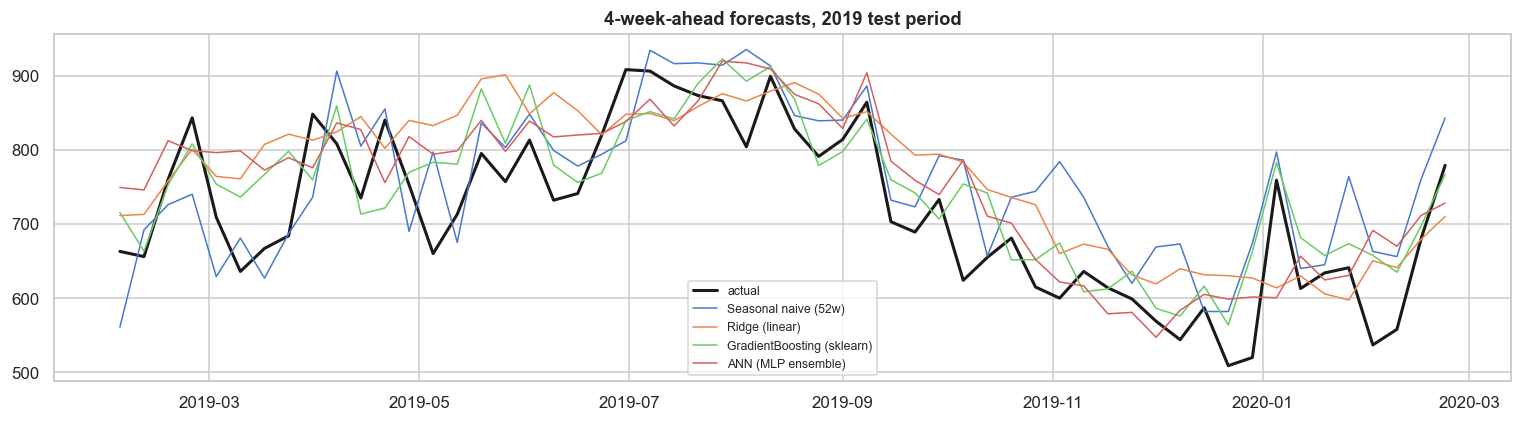

In [66]:
def sup_feats(ls, h, season, freq):
    """Supervised table at origin t -> target ls[t+h]-ls[t]. Returns features, target, seasonal-naive prediction, target dates."""
    X = pd.DataFrame(index=ls.index)
    for k in ((1, 2, 3, 4, 8) if freq == 'W' else (1, 2, 3, 6)): X[f'd{k}'] = ls - ls.shift(k)
    X['dS'] = ls - ls.shift(season)
    for w in ((4, 13, 52) if freq == 'W' else (3, 12)): X[f'm{w}'] = ls - ls.rolling(w).mean()
    td = ls.index + (pd.Timedelta(weeks=h) if freq == 'W' else pd.DateOffset(months=h))
    ph = (td.isocalendar().week.values / 52.18 if freq == 'W' else td.month.values / 12.0)
    X['sin'], X['cos'] = np.sin(2 * np.pi * ph), np.cos(2 * np.pi * ph)
    return X, ls.shift(-h) - ls, ls.shift(season - h) - ls, td

wk = g.set_index('date').resample('W-SUN').size().astype(float).iloc[1:-1]      # drop partial first/last week
lw = np.log1p(wk); HW = 4
Xw, yw, snw, tdw = sup_feats(lw, HW, 52, 'W')
okw = (Xw.notna().all(axis=1) & yw.notna() & snw.notna()).values
trw = okw & (tdw <= pd.Timestamp('2018-12-31')); tew = okw & (Xw.index >= pd.Timestamp('2019-01-01')) & (tdw < COVID_START)
print(f"Weekly series: {len(wk)} weeks | train rows {trw.sum()} | test rows {tew.sum()} | horizon {HW} weeks")
wmods = {'Ridge (linear)': make_pipeline(StandardScaler(), Ridge(alpha=1.0)), f'{GBM_NAME}': make_gbm(), 'ANN (MLP ensemble)': MLPEnsemble()}
pred = {'Seasonal naive (52w)': snw.values[tew]}
for n_, m_ in wmods.items(): pred[n_] = m_.fit(Xw.values[trw], yw.values[trw]).predict(Xw.values[tew])
base = lw.values[tew]; actual_lvl = np.expm1(base + yw.values[tew])
rows = []
for n_, p_ in pred.items():
    lvl = np.expm1(base + p_)
    rows.append(dict(model=n_, MAE_log=np.mean(np.abs(yw.values[tew] - p_)), RMSE_log=np.sqrt(np.mean((yw.values[tew] - p_) ** 2)),
                     MAPE_pct=np.mean(np.abs(actual_lvl - lvl) / actual_lvl) * 100))
wres = pd.DataFrame(rows).set_index('model').sort_values('MAE_log'); wres['skill_vs_snaive'] = 1 - wres['MAE_log'] / wres.loc['Seasonal naive (52w)', 'MAE_log']
RESULTS['ts_weekly_ml'] = wres; display(wres.round(3))
fig, ax = plt.subplots(figsize=(14, 4)); tix = pd.DatetimeIndex(tdw[tew])
ax.plot(tix, actual_lvl, color='k', lw=2, label='actual')
for n_, p_ in pred.items(): ax.plot(tix, np.expm1(base + p_), lw=1, label=n_)
ax.set_title(f'{HW}-week-ahead forecasts, 2019 test period'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 8. Extended social-network analysis

Builds on `G`, `E`, `deg`, `node2comm`, `comms_l`, `cstat`, `adj`, `uid2i`, `net` from sections 4-5. Run time on the full graph is a few minutes per block with `FAST = True`.

**Caveats that apply to everything below.** The graph is a *static* snapshot (no edge timestamps), restricted to the subset, and one-sided friend lists are treated as undirected ties. Influence tests can show that friends' behaviour is *associated* with a user's, but homophily (friends have similar tastes) and shared context (visiting together) cannot be fully separated from social influence with observational data.

Betweenness (k=200 sampled sources) + eigenvector done in 319s


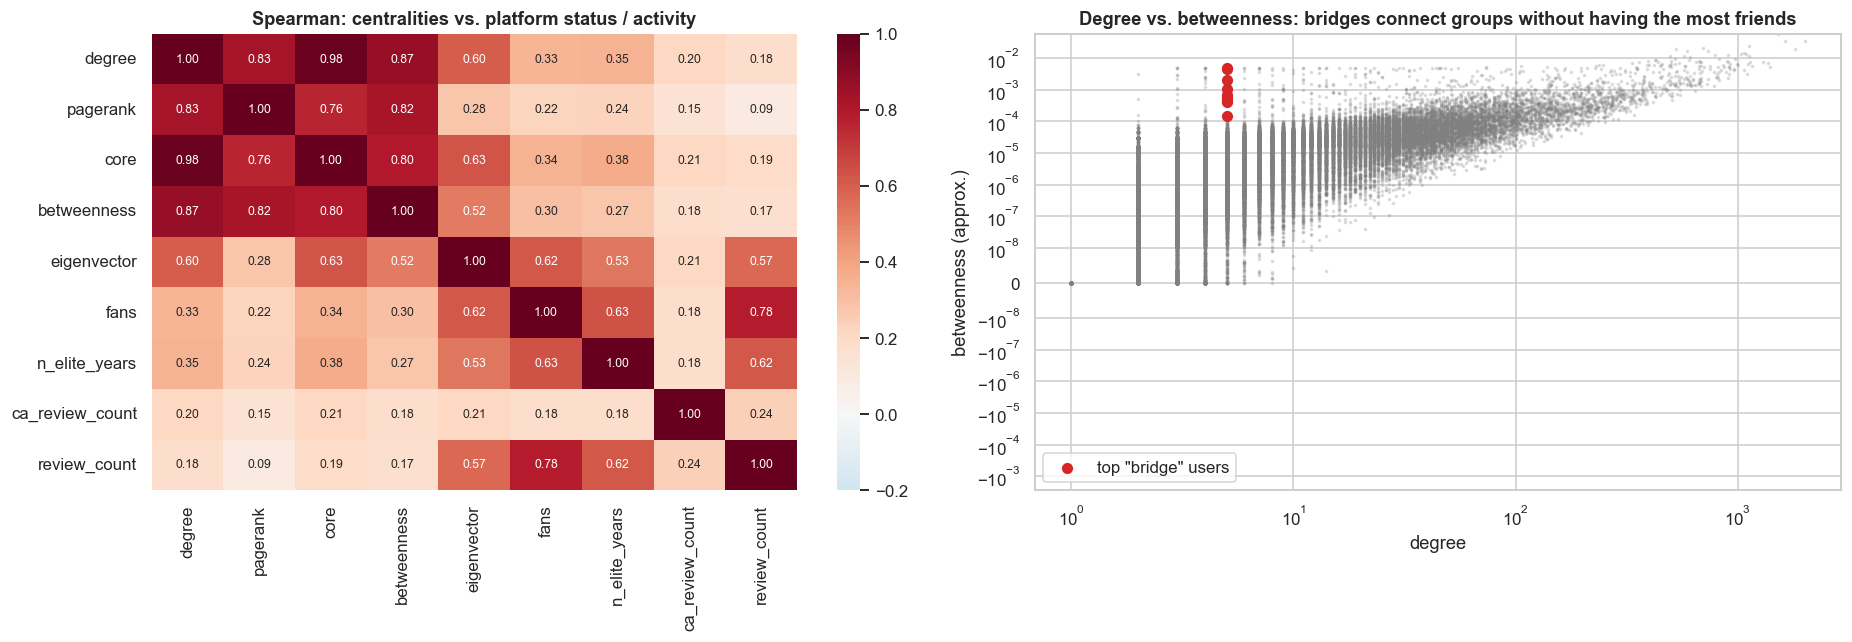

,degree,betweenness,pagerank,core,fans,n_elite_years,ca_review_count,review_count
user_id,,,,,,,,
2rYHYUn9FwZdOW6l7Vs_vQ,5,0.00483,0.00001,4,4,1,7,81
I5tDIEeuWfHzLj7zG3p9Ag,5,0.00437,0.00001,3,10,6,3,217
C9PWgq4G1JrLlxQCfeOLEQ,5,0.00196,0.00001,4,13,2,2,172
SKQtaCP7tUQzT4akRACISw,5,0.00102,0.00002,3,0,0,1,2
Rod3SZ5ukojhSDWccpaPkw,5,0.00066,0.00001,3,2,0,1,39
jhKPeysrFM9ab3KUzXtanw,5,0.00059,0.00001,4,0,0,1,8
4q-CIxesDXijDD91fIOUMg,5,0.00046,0.00001,3,0,0,1,7
jxLdCHFEdUuNxMYkf5YljA,5,0.00044,0.00001,4,2,0,1,54
3acPSgy4Idg4u9NYwX7tOg,5,0.00040,0.00001,4,2,0,1,50


Top-10 overlap between rankings (share of the degree top-10 also in the top-10 of ...): {'pagerank': 0.4, 'betweenness': 0.4, 'eigenvector': 0.7, 'fans': 0.3}


In [67]:
# ---------- 8.1 more centralities: who is *central* depends on the definition ----------
t0 = time.time()
btw = pd.Series(nx.betweenness_centrality(G, k=min(BETW_K, G.number_of_nodes()), seed=SEED))
try:
    eig = pd.Series(nx.eigenvector_centrality_numpy(G.subgraph(lcc), max_iter=500))   # defined on one component only; others get 0
except Exception as ex_:
    print(f"eigenvector centrality failed ({type(ex_).__name__}); column left empty"); eig = pd.Series(dtype=float)
print(f"Betweenness (k={BETW_K} sampled sources) + eigenvector done in {time.time() - t0:.0f}s")
ca_users['betweenness'] = ca_users['user_id'].map(btw).fillna(0); ca_users['eigenvector'] = ca_users['user_id'].map(eig).fillna(0)
cen_cols = ['degree', 'pagerank', 'core', 'betweenness', 'eigenvector']
ext_cols = [c for c in ['fans', 'n_elite_years', 'ca_review_count', 'review_count'] if c in ca_users.columns]
sub = ca_users.loc[in_G].set_index('user_id')[cen_cols + ext_cols]
cor = sub.corr(method='spearman'); RESULTS['centrality_spearman'] = cor
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(cor, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-.2, vmax=1, ax=axes[0], annot_kws={'size': 8}); axes[0].set_title('Spearman: centralities vs. platform status / activity')
# bridges = high betweenness relative to degree
pr_ = sub[['degree', 'betweenness']].rank(pct=True); sub = sub.assign(bridge_score=pr_['betweenness'] - pr_['degree'])
bridges = sub[sub['degree'] >= 5].sort_values('bridge_score', ascending=False).head(10)
axes[1].scatter(sub['degree'], sub['betweenness'], s=2, alpha=.2, color='gray'); axes[1].scatter(bridges['degree'], bridges['betweenness'], s=40, color='tab:red', label='top "bridge" users')
axes[1].set_xscale('log'); axes[1].set_yscale('symlog', linthresh=1e-8); axes[1].set_xlabel('degree'); axes[1].set_ylabel('betweenness (approx.)'); axes[1].legend(); axes[1].set_title('Degree vs. betweenness: bridges connect groups without having the most friends')
plt.tight_layout(); plt.show()
display(bridges[['degree', 'betweenness', 'pagerank', 'core'] + ext_cols].round(5))
print("Top-10 overlap between rankings (share of the degree top-10 also in the top-10 of ...):",
      {c: len(set(sub['degree'].nlargest(10).index) & set(sub[c].nlargest(10).index)) / 10 for c in ['pagerank', 'betweenness', 'eigenvector', 'fans']})

In [68]:
# ---------- 8.2 community validation: do communities just mirror geography? how stable is Louvain? ----------
rc = ca_reviews.loc[ca_reviews['user_id'].isin(node2comm), ['user_id', 'business_id', 'city']]
main_city = rc.groupby(['user_id', 'city']).size().reset_index(name='n').sort_values(['user_id', 'n'], ascending=[True, False]).drop_duplicates('user_id').set_index('user_id')['city']
ug = pd.DataFrame({'comm': pd.Series(node2comm), 'city': main_city}).dropna()
def purity(a, b): return pd.crosstab(a, b).max(axis=1).sum() / len(a)
print(f"Louvain (res={LOUVAIN_RESOLUTION}) vs. user's main city:  NMI = {normalized_mutual_info_score(ug['comm'], ug['city']):.3f} | purity = {purity(ug['comm'], ug['city']):.1%}"
      f"   (purity of an all-in-one-city labelling = {ug['city'].value_counts(normalize=True).iloc[0]:.1%})")

base_labels = pd.Series(node2comm); rows = []
runs = [('resolution 0.5', dict(resolution=0.5, seed=SEED)), ('resolution 2.0', dict(resolution=2.0, seed=SEED)), ('resolution 1.0, other seed', dict(resolution=LOUVAIN_RESOLUTION, seed=SEED + 1))]
t0 = time.time()
for name, kw in runs:
    cs = sorted(louvain_communities(G, **kw), key=len, reverse=True); lab = pd.Series({u: i for i, c in enumerate(cs) for u in c}).reindex(base_labels.index)
    rows.append(dict(run=name, communities=len(cs), modularity=modularity(G, cs), largest=len(cs[0]), ARI_vs_baseline=adjusted_rand_score(base_labels, lab),
                     NMI_vs_baseline=normalized_mutual_info_score(base_labels, lab)))
rows.insert(0, dict(run=f'baseline (res={LOUVAIN_RESOLUTION})', communities=len(comms_l), modularity=Q, largest=len(comms_l[0]), ARI_vs_baseline=1.0, NMI_vs_baseline=1.0))
try:
    import igraph as ig, leidenalg
    nodes_ = list(G.nodes()); ix_ = {u: i for i, u in enumerate(nodes_)}
    Gi = ig.Graph(n=len(nodes_), edges=[(ix_[a], ix_[b]) for a, b in G.edges()])
    part = leidenalg.find_partition(Gi, leidenalg.ModularityVertexPartition, seed=SEED)
    lab = pd.Series(part.membership, index=nodes_).reindex(base_labels.index)
    rows.append(dict(run='Leiden', communities=len(part), modularity=part.modularity, largest=max(part.sizes()), ARI_vs_baseline=adjusted_rand_score(base_labels, lab), NMI_vs_baseline=normalized_mutual_info_score(base_labels, lab)))
except ImportError:
    print("(Leiden skipped: `pip install python-igraph leidenalg` to add it)")
stab = pd.DataFrame(rows).set_index('run'); RESULTS['community_stability'] = stab
display(stab.round(3)); print(f"runtime {time.time() - t0:.0f}s")
print("Reading: ARI/NMI close to 1 = the partition is robust; the *big* communities usually survive resolution changes while the long tail of tiny ones reshuffles.")

Louvain (res=1.0) vs. user's main city:  NMI = 0.032 | purity = 79.0%   (purity of an all-in-one-city labelling = 78.7%)
(Leiden skipped: `pip install python-igraph leidenalg` to add it)


,communities,modularity,largest,ARI_vs_baseline,NMI_vs_baseline
run,,,,,
baseline (res=1.0),1580,0.522,16538,1.000,1.000
resolution 0.5,1439,0.457,29024,0.341,0.523
resolution 2.0,1340,0.485,6483,0.337,0.519
"resolution 1.0, other seed",1625,0.523,17302,0.599,0.635


runtime 110s
Reading: ARI/NMI close to 1 = the partition is robust; the *big* communities usually survive resolution changes while the long tail of tiny ones reshuffles.


,observed,configuration model (same degrees)
avg shortest path (sampled),4.340,3.62
avg clustering,0.103,0.02


Diameter >= 12 (lower bound from sampled sources).  Clustering is 5x the degree-preserving random graph while paths are 1.20x -> small-world  (239s)
(power-law comparison skipped: `pip install powerlaw`)


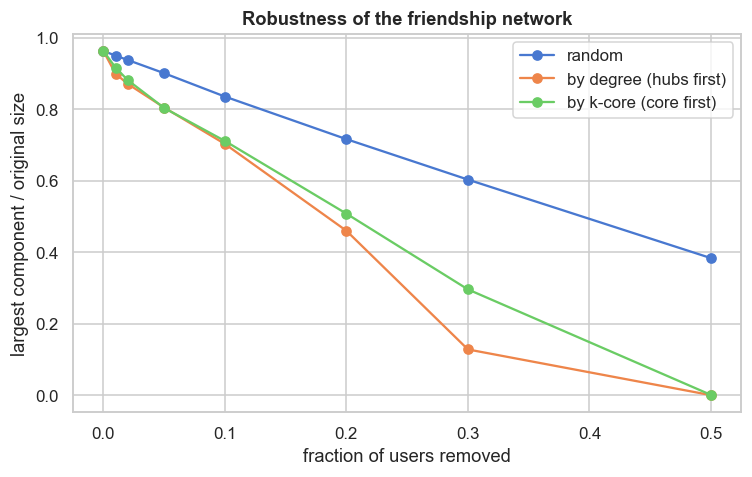

In [69]:
# ---------- 8.3 structural benchmarks: small world?, power law?, robustness ----------
def sampled_path_stats(Gx, nsrc=100, seed=SEED):
    comp = max(nx.connected_components(Gx), key=len); H_ = Gx.subgraph(comp)
    rs = random.Random(seed); srcs = rs.sample(list(H_.nodes()), min(nsrc, len(comp)))
    dists = []; ecc = 0
    for s in srcs:
        dd = nx.single_source_shortest_path_length(H_, s); dists.append(np.mean(list(dd.values()))); ecc = max(ecc, max(dd.values()))
    return float(np.mean(dists)), ecc, nx.approximation.average_clustering(H_, trials=5000, seed=seed)

t0 = time.time()
L_obs, diam_lb, C_obs = sampled_path_stats(G)
deg_seq = [d for _, d in G.degree()]
CM = nx.Graph(nx.configuration_model(deg_seq, seed=SEED)); CM.remove_edges_from(nx.selfloop_edges(CM))
L_rnd, _, C_rnd = sampled_path_stats(CM)
sw = pd.DataFrame({'observed': [L_obs, C_obs], 'configuration model (same degrees)': [L_rnd, C_rnd]}, index=['avg shortest path (sampled)', 'avg clustering'])
RESULTS['small_world'] = sw; display(sw.round(3))
print(f"Diameter >= {diam_lb} (lower bound from sampled sources).  Clustering is {C_obs / C_rnd:.0f}x the degree-preserving random graph while paths are {L_obs / L_rnd:.2f}x -> {'small-world' if C_obs / C_rnd > 3 and L_obs / L_rnd < 1.5 else 'not clearly small-world'}  ({time.time() - t0:.0f}s)")

# degree distribution: power law vs alternatives
try:
    import powerlaw
    fit = powerlaw.Fit(deg.values, discrete=True, verbose=False)
    R1, p1 = fit.distribution_compare('power_law', 'lognormal', normalized_ratio=True)
    R2, p2 = fit.distribution_compare('power_law', 'truncated_power_law', normalized_ratio=True)
    print(f"Power-law fit: alpha = {fit.alpha:.2f}, xmin = {fit.xmin:.0f}  | vs lognormal: R = {R1:.2f} (p = {p1:.3f}) | vs truncated power law: R = {R2:.2f} (p = {p2:.3f})  [R<0 favours the alternative]")
except ImportError:
    print("(power-law comparison skipped: `pip install powerlaw`)")

# robustness: remove nodes randomly vs. targeted by degree / by k-core; track the largest connected component
nodes_ = list(G.nodes()); A = nx.to_scipy_sparse_array(G, nodelist=nodes_, format='csr'); nN = len(nodes_)
dvec = np.asarray(A.sum(axis=1)).ravel(); cvec = np.array([core[u] for u in nodes_]); rs_ = np.random.default_rng(SEED)
orders = {'random': rs_.permutation(nN), 'by degree (hubs first)': np.argsort(-dvec, kind='stable'), 'by k-core (core first)': np.argsort(-cvec, kind='stable')}
fracs = [0, .01, .02, .05, .1, .2, .3, .5]; rob = {}
for nm, order in orders.items():
    out = []
    for f in fracs:
        keep = np.ones(nN, bool); keep[order[:int(f * nN)]] = False
        if keep.sum() < 2: out.append(0.0); continue
        _, lab = connected_components(A[keep][:, keep], directed=False); out.append(np.bincount(lab).max() / nN)
    rob[nm] = out
rob = pd.DataFrame(rob, index=fracs); RESULTS['robustness'] = rob
ax = rob.plot(marker='o', figsize=(7, 4.5)); ax.set_xlabel('fraction of users removed'); ax.set_ylabel('largest component / original size'); ax.set_title('Robustness of the friendship network'); plt.tight_layout(); plt.show()

### 8.4 Social influence on where people review
Three complementary analyses on the same eligible reviews as the exposure screen in section 5:

1. **Matched case-control.** For each sampled review (the *case*: user v reviews business b on day d) draw a *control*: another user who reviewed in the **same city and month**, in the **same degree bucket**, and had **not yet reviewed b** on day d. Compare how often case and control users had a friend who reviewed b earlier, by recency of that friend's review. The odds ratio (OR) > 1 means friends' earlier visits predict one's own visit beyond city, month and sociability.
2. **Rating conformity.** Among reviews preceded by a friend's review of the same business, is the user's rating deviation (stars minus the business mean) correlated with the friend's deviation - more than with a *non-friend* earlier reviewer of the same business (placebo)?
3. **Influencer ranking.** Each review credits the friends who reviewed the same place 1-30 days earlier (credit split equally); users are ranked by credit per review they wrote.

In [ ]:
t0 = time.time()
bmean = ca_reviews.groupby('business_id')['stars'].mean()
dbuck = ca_users.set_index('user_id')['deg_bucket'].astype(str)
net2 = ca_reviews.loc[ca_reviews['user_id'].isin(G.nodes), ['user_id', 'business_id', 'date', 'month', 'stars', 'city']].copy()
net2['u'] = net2['user_id'].map(uid2i).astype(np.int64); net2['b'] = pd.factorize(net2['business_id'])[0]
net2['d'] = (net2['date'].dt.normalize() - pd.Timestamp('2000-01-01')).dt.days.astype(np.int64)
net2['dev'] = net2['stars'] - net2['business_id'].map(bmean); net2['dbucket'] = net2['user_id'].map(dbuck)
net2 = net2.sort_values(['u', 'b', 'd']).drop_duplicates(['u', 'b'], keep='first')
net2 = net2[net2.groupby('b')['u'].transform('size') >= 2].sort_values(['b', 'd']).reset_index(drop=True)
u2, b2, d2, dev2 = net2['u'].values, net2['b'].values, net2['d'].values, net2['dev'].values

def scan_friend_exposure(u, b, d, dev, adj, lo=1, hi=30, seed=SEED):
    rnd = random.Random(seed).random; n = len(u)
    k_win = np.zeros(n, np.int32); g_min = np.full(n, -1, np.int64); fdev = np.full(n, np.nan); pdev = np.full(n, np.nan); credit = defaultdict(float)
    cut = np.flatnonzero(np.diff(b)) + 1; starts = np.r_[0, cut]; ends = np.r_[cut, n]
    for s, e in zip(starts, ends):
        if e - s < 2: continue
        seen = {}; su = []; sd = []; sv = []
        for i in range(s, e):
            v = u[i]; nb = adj.get(v)
            if nb and seen:
                cand = [f for f in (nb if len(nb) <= len(seen) else seen) if f in seen and f in nb]
                best = -1; devs = []; win = []
                for f in cand:
                    gp = d[i] - seen[f][0]
                    if gp >= lo:
                        devs.append(seen[f][1])
                        if best < 0 or gp < best: best = gp
                        if gp <= hi: win.append(f)
                if devs:
                    g_min[i] = best; fdev[i] = np.mean(devs)
                    for _ in range(8):                                   # placebo: a random earlier NON-friend reviewer of the same place
                        j = int(rnd() * len(su)); w = su[j]
                        if w != v and w not in nb and sd[j] < d[i]: pdev[i] = sv[j]; break
                if win:
                    k_win[i] = len(win)
                    for f in win: credit[f] += 1.0 / len(win)
            seen[v] = (d[i], dev[i]); su.append(v); sd.append(d[i]); sv.append(dev[i])
    return k_win, g_min, fdev, pdev, credit

k_win, g_min, fdev, pdev, credit = scan_friend_exposure(u2, b2, d2, dev2, adj)
print(f"Scanned {len(net2):,} reviews in {time.time() - t0:.0f}s")

# ---- (1) matched case-control ----
first_rev = {}
for bb, uu, dd in zip(b2, u2, d2): first_rev.setdefault(bb, {})[uu] = dd
def expo(v, b, d):
    nb = adj.get(v); fr_ = first_rev[b]
    if not nb: return -1
    best = -1
    for f in (nb if len(nb) <= len(fr_) else fr_):
        if f in nb and f in fr_:
            gp = d - fr_[f]
            if gp >= 1 and (best < 0 or gp < best): best = gp
    return best

pools = net2.groupby(['month', 'city', 'dbucket'])['u'].unique().to_dict()
rng = np.random.default_rng(SEED); rnd = random.Random(SEED).random
case_rows = rng.choice(len(net2), size=min(N_CASES, len(net2)), replace=False)
mon, cty, dbk = net2['month'].values, net2['city'].values, net2['dbucket'].values
recs = []
for i in case_rows:
    pool = pools.get((mon[i], cty[i], dbk[i]))
    if pool is None or len(pool) < 2: continue
    for _ in range(10):
        c_ = pool[int(rnd() * len(pool))]
        if c_ != u2[i] and first_rev[b2[i]].get(c_, 10**9) > d2[i]:
            recs.append((g_min[i], expo(c_, b2[i], d2[i]), len(adj.get(u2[i], ())), len(adj.get(c_, ())))); break
cc = np.asarray(recs, dtype=float).reshape(-1, 4); print(f"Matched case-control pairs: {len(cc):,}")
def gap_cat(gm): return np.select([gm < 0, gm <= 7, gm <= 30, gm <= 90], ['none', '1-7 days', '8-30 days', '31-90 days'], '>90 days')
cats = ['1-7 days', '8-30 days', '31-90 days', '>90 days']
if len(cc):
    df_cc = pd.DataFrame({'case': np.r_[np.ones(len(cc)), np.zeros(len(cc))], 'cat': np.r_[gap_cat(cc[:, 0]), gap_cat(cc[:, 1])], 'logdeg': np.log1p(np.r_[cc[:, 2], cc[:, 3]])})
    Xcc = pd.get_dummies(df_cc['cat']).reindex(columns=cats, fill_value=0).astype(float); Xcc['logdeg'] = df_cc['logdeg']
    lg = sm.Logit(df_cc['case'], sm.add_constant(Xcc)).fit(disp=0)
    orr = pd.DataFrame({'OR': np.exp(lg.params[cats]), 'CI_low': np.exp(lg.conf_int().loc[cats, 0]), 'CI_high': np.exp(lg.conf_int().loc[cats, 1]),
                        '%cases_exposed': [(df_cc[df_cc.case == 1]['cat'] == c).mean() * 100 for c in cats], '%controls_exposed': [(df_cc[df_cc.case == 0]['cat'] == c).mean() * 100 for c in cats]})
else:
    print('No matched case-control pairs; skipping the case-control model.')
    orr = pd.DataFrame(columns=['OR', 'CI_low', 'CI_high', '%cases_exposed', '%controls_exposed'], index=cats, dtype=float)
RESULTS['influence_case_control'] = orr; display(orr.round(3))

# ---- (2) rating conformity ----
m_ = ~np.isnan(fdev) & ~np.isnan(pdev); own = dev2[m_]
r_f, r_p = np.corrcoef(own, fdev[m_])[0, 1], np.corrcoef(own, pdev[m_])[0, 1]
bs = []; nn = m_.sum()
for _ in range(300):
    j = rng.integers(0, nn, nn); bs.append(np.corrcoef(own[j], fdev[m_][j])[0, 1] - np.corrcoef(own[j], pdev[m_][j])[0, 1])
print(f"Rating conformity (n = {nn:,}): corr(own, friends' earlier rating deviation) = {r_f:.3f} | corr(own, non-friend placebo) = {r_p:.3f} | difference = {r_f - r_p:+.3f} (95% bootstrap CI {np.percentile(bs, 2.5):+.3f} to {np.percentile(bs, 97.5):+.3f})")

# ---- (3) influencers ----
n_rev = pd.Series(np.bincount(u2, minlength=len(ca_users)), index=ca_users['user_id'].values)
inf = pd.DataFrame({'credit': pd.Series(credit)}); inf.index = ca_users['user_id'].values[inf.index.values.astype(int)]
inf['reviews_in_data'] = n_rev.reindex(inf.index).values; inf['credit_per_review'] = inf['credit'] / inf['reviews_in_data'].clip(lower=1)
inf = inf.join(ca_users.set_index('user_id')[['degree', 'pagerank', 'fans', 'n_elite_years']])
RESULTS['influencers'] = inf.sort_values('credit', ascending=False).head(25)
print("\nTop influencers by follower-review credit:"); display(inf.sort_values('credit', ascending=False).head(10).round(3))
print("Most 'efficient' (credit per review, >=10 reviews, >=20 friends):"); display(inf[(inf['reviews_in_data'] >= 10) & (inf['degree'] >= 20)].sort_values('credit_per_review', ascending=False).head(10).round(3))
print("Spearman of credit with:", {c: round(float(inf['credit'].corr(inf[c], method='spearman')), 2) for c in ['degree', 'pagerank', 'fans', 'n_elite_years', 'reviews_in_data']})
fig, ax = plt.subplots(figsize=(7, 4)); ax.errorbar(range(len(orr)), orr['OR'], yerr=[orr['OR'] - orr['CI_low'], orr['CI_high'] - orr['OR']], fmt='o', capsize=4)
ax.axhline(1, color='k', lw=.8); ax.set_xticks(range(len(orr))); ax.set_xticklabels(orr.index); ax.set_ylabel('odds ratio (log)'); ax.set_yscale('log')
ax.set_xlabel('days since the most recent friend review of the same place'); ax.set_title('Does a friend\'s earlier visit predict yours?'); plt.tight_layout(); plt.show()

Scanned 186,522 reviews in 14s
Matched case-control pairs: 0
No matched case-control pairs; skipping the case-control model.


,OR,CI_low,CI_high,%cases_exposed,%controls_exposed
1-7 days,NaN,NaN,NaN,NaN,NaN
8-30 days,NaN,NaN,NaN,NaN,NaN
31-90 days,NaN,NaN,NaN,NaN,NaN
>90 days,NaN,NaN,NaN,NaN,NaN


### 8.5 Link prediction: which friendships are likely, and what predicts them?
Hold out edges, remove them from the graph, and score the held-out pairs against non-edges. Two negative sets: **random** pairs (easy) and **friend-of-friend** pairs at distance 2 (hard - these are the realistic candidates). Heuristics (common neighbours, Jaccard, Adamic-Adar, preferential attachment) are compared with a gradient-boosting classifier, first with graph features only and then adding **non-graph** features (co-reviewed businesses, same main city, join-year gap). Features are computed on the graph *without* the held-out edges; community membership is deliberately not used because Louvain saw the held-out edges.

In [71]:
t0 = time.time(); rs = random.Random(SEED); rng = np.random.default_rng(SEED)
Gl = G.subgraph(lcc).copy(); edges_ = list(Gl.edges()); n_lp = min(N_LP, int(0.1 * len(edges_)))      # never hold out more than 20% of edges in total
sel = rng.choice(len(edges_), size=2 * n_lp, replace=False)
pos_tr = [edges_[i] for i in sel[:n_lp]]; pos_te = [edges_[i] for i in sel[n_lp:]]
Gl.remove_edges_from(pos_tr + pos_te); nodes_l = list(Gl.nodes())
ub = ca_reviews.loc[ca_reviews['user_id'].isin(Gl.nodes), ['user_id', 'business_id']].groupby('user_id')['business_id'].agg(set).to_dict()
jy = ca_users.set_index('user_id')['join_year']; cityU = ug['city'].to_dict()

def neg_random(n):
    out = set()
    while len(out) < n:
        a, b = rs.sample(nodes_l, 2)
        if not Gl.has_edge(a, b): out.add((a, b))
    return list(out)
def neg_fof(n):
    out = set(); tries = 0
    while len(out) < n and tries < 50 * n:
        tries += 1; a = rs.choice(nodes_l); na = list(Gl[a])
        if not na: continue
        m = rs.choice(na); nm = list(Gl[m]); b = rs.choice(nm)
        if b != a and not Gl.has_edge(a, b): out.add((a, b))
    return list(out)

def lp_feats(pairs):
    rows = []
    for a, b in pairs:
        na, nb_ = set(Gl[a]), set(Gl[b]); cn = na & nb_; da, db = len(na), len(nb_)
        aa = sum(1.0 / np.log(Gl.degree(w)) for w in cn if Gl.degree(w) > 1)
        rows.append(dict(cn=len(cn), jaccard=len(cn) / max(da + db - len(cn), 1), adamic_adar=aa, pref_attach=np.log1p(da * db), deg_min=min(da, db), deg_max=max(da, db),
                         co_reviewed=len(ub.get(a, set()) & ub.get(b, set())), same_city=float(cityU.get(a) == cityU.get(b) and a in cityU), join_gap=abs(jy.get(a, np.nan) - jy.get(b, np.nan))))
    return pd.DataFrame(rows)
GRAPH_F = ['cn', 'jaccard', 'adamic_adar', 'pref_attach', 'deg_min', 'deg_max']; ALL_F = GRAPH_F + ['co_reviewed', 'same_city', 'join_gap']
P_tr, P_te = lp_feats(pos_tr), lp_feats(pos_te)
print(f"Held-out edges that close a triangle in the remaining graph (>=1 common neighbour): {(P_te['cn'] >= 1).mean():.1%}")
lp_res = {}
# friend-of-friend negatives always have >=1 common neighbour, so that regime only scores the held-out edges that also do (triangle-closing links)
for neg_name, neg_fn, need_cn in [('random negatives (all held-out edges)', neg_random, False), ('friend-of-friend negatives (triangle-closing edges only)', neg_fof, True)]:
    Ptr, Pte = (P_tr[P_tr['cn'] >= 1], P_te[P_te['cn'] >= 1]) if need_cn else (P_tr, P_te)
    Ftr = pd.concat([Ptr, lp_feats(neg_fn(len(Ptr)))], ignore_index=True); ytr = np.r_[np.ones(len(Ptr)), np.zeros(len(Ftr) - len(Ptr))]
    Fte = pd.concat([Pte, lp_feats(neg_fn(len(Pte)))], ignore_index=True); yte = np.r_[np.ones(len(Pte)), np.zeros(len(Fte) - len(Pte))]
    r = {c: roc_auc_score(yte, Fte[c].fillna(0)) for c in ['cn', 'jaccard', 'adamic_adar', 'pref_attach', 'co_reviewed']}
    for nm, cols in [(f'{GBM_NAME}: graph features', GRAPH_F), (f'{GBM_NAME}: graph + non-graph', ALL_F)]:
        clf = make_gbm_clf().fit(Ftr[cols].fillna(-1), ytr); r[nm] = roc_auc_score(yte, clf.predict_proba(Fte[cols].fillna(-1))[:, 1])
    lp_res[neg_name] = r
lp = pd.DataFrame(lp_res); RESULTS['link_prediction_auc'] = lp; display(lp.round(3))
print(f"AUC on held-out edges vs. equally many non-edges ({time.time() - t0:.0f}s). The friend-of-friend column is the realistic test; if 'graph + non-graph' beats 'graph' there, co-reviewing behaviour carries signal the topology does not.")

Held-out edges that close a triangle in the remaining graph (>=1 common neighbour): 76.6%


,random negatives (all held-out edges),friend-of-friend negatives (triangle-closing edges only)
cn,0.879,0.871
jaccard,0.877,0.550
adamic_adar,0.880,0.812
pref_attach,0.900,0.881
co_reviewed,0.531,0.525
GradientBoosting (sklearn): graph features,0.949,0.917
GradientBoosting (sklearn): graph + non-graph,0.952,0.918


AUC on held-out edges vs. equally many non-edges (28s). The friend-of-friend column is the realistic test; if 'graph + non-graph' beats 'graph' there, co-reviewing behaviour carries signal the topology does not.


### 8.6 User-business (bipartite) view: do co-review patterns recover categories and cities?
Project the user-business network onto the busiest businesses: two businesses are similar if many of the same users reviewed both (cosine similarity). Keep each business's 10 nearest neighbours, run Louvain and compare the clusters with macro-category and city. Then a quick **cohort effect**: do early joiners have more friends (first-mover / preferential-attachment signature)?

Co-review graph: 1,500 businesses, 11,349 edges | 10 clusters | modularity = 0.487
NMI(cluster, city) = 0.248 | NMI(cluster, macro-category) = 0.132


,businesses,top_city,top_category,top_cat_share
0,248,Santa Barbara,Restaurants,0.399194
1,246,Santa Barbara,Restaurants,0.231707
2,238,Santa Barbara,Beauty & Spas,0.315126
3,209,Santa Barbara,Nightlife & Bars,0.358852
4,166,Goleta,Restaurants,0.63253
5,146,Santa Barbara,Restaurants,0.547945


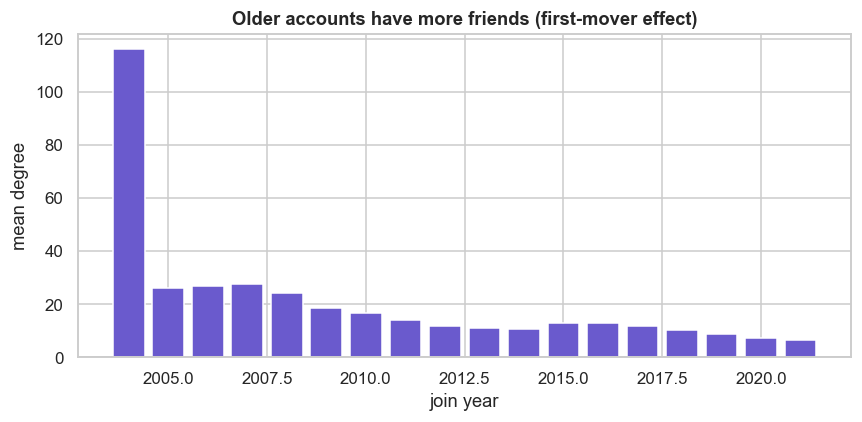

Spearman(degree, join_year) among networked users: -0.048


In [72]:
top_b = ca_reviews['business_id'].value_counts().head(N_BIZ_GRAPH).index
rb = ca_reviews.loc[ca_reviews['business_id'].isin(top_b), ['user_id', 'business_id']].drop_duplicates()
ui, ulab = pd.factorize(rb['user_id']); bi, blab = pd.factorize(rb['business_id'])
B = sparse.csr_matrix((np.ones(len(rb)), (ui, bi)), shape=(len(ulab), len(blab)))
B = B[np.asarray(B.sum(axis=1)).ravel() >= 2]                      # users who link at least two businesses
S = (B.T @ B).toarray(); dg = np.diag(S).copy(); np.fill_diagonal(S, 0)
cos = S / np.sqrt(np.outer(dg, dg).clip(min=1)); K = 10
Gb = nx.Graph()
for i in range(len(blab)):
    for j in np.argsort(-cos[i])[:K]:
        if cos[i, j] > 0: Gb.add_edge(blab[i], blab[j], weight=float(cos[i, j]))
cb = sorted(louvain_communities(Gb, weight='weight', resolution=1.0, seed=SEED), key=len, reverse=True)
lab_b = pd.Series({n: i for i, c in enumerate(cb) for n in c})
bz = ca_biz.set_index('business_id').reindex(lab_b.index)[['city', 'macro_cat']].assign(comm=lab_b)
print(f"Co-review graph: {Gb.number_of_nodes():,} businesses, {Gb.number_of_edges():,} edges | {len(cb)} clusters | modularity = {modularity(Gb, cb, weight='weight'):.3f}")
print(f"NMI(cluster, city) = {normalized_mutual_info_score(bz['comm'], bz['city']):.3f} | NMI(cluster, macro-category) = {normalized_mutual_info_score(bz['comm'], bz['macro_cat']):.3f}")
big = bz['comm'].value_counts().head(6).index
comp_tab = pd.concat({c: pd.Series({'businesses': int((bz['comm'] == c).sum()), 'top_city': bz.loc[bz['comm'] == c, 'city'].mode()[0], 'top_category': bz.loc[bz['comm'] == c, 'macro_cat'].mode()[0],
                       'top_cat_share': bz.loc[bz['comm'] == c, 'macro_cat'].value_counts(normalize=True).iloc[0]}) for c in big}, axis=1).T
RESULTS['bipartite_clusters'] = comp_tab; display(comp_tab)

# cohort / first-mover effect
cohort = ca_users[in_G].groupby('join_year')['degree'].agg(['size', 'mean', 'median']).rename(columns={'size': 'users'})
fig, ax = plt.subplots(figsize=(8, 4)); ax.bar(cohort.index, cohort['mean'], color='slateblue'); ax.set_xlabel('join year'); ax.set_ylabel('mean degree'); ax.set_title('Older accounts have more friends (first-mover effect)'); plt.tight_layout(); plt.show()
print("Spearman(degree, join_year) among networked users:", round(float(ca_users.loc[in_G, 'degree'].corr(ca_users.loc[in_G, 'join_year'], method='spearman')), 3))

## 9. Where the two analyses meet: network-aware forecasting

Questions: (a) does a **global model across communities** beat per-series seasonal naive, and do **network features** (friend exposure, degree structure of the authors) add anything beyond plain autoregressive/behavioural features? (b) is it better to forecast the total **bottom-up** (sum of community forecasts) or **directly**? (c) do communities **lead or lag** each other (Granger)?

Panel = communities with a median of >= 10 reviews/month (at most 12). Evaluation is pre-COVID and strictly out-of-sample: training rows are those whose *target month* is before `PRE_TEST_START`. With ~10 series the differences between models are small and noisy - read them as indicative, not conclusive.

Panel: 8 communities -> [0, 5, 1, 2, 4, 3, 6, 7]
h= 1: train rows 720 | test rows 392
h= 3: train rows 704 | test rows 376
h= 6: train rows 680 | test rows 352
h=12: train rows 632 | test rows 304


,h=1,h=3,h=6,h=12,mean,skill_vs_snaive
Seasonal naive,0.227,0.224,0.220,0.219,0.223,0.000
GradientBoosting (sklearn): autoregressive,0.185,0.220,0.248,0.349,0.250,-0.124
GradientBoosting (sklearn): + behaviour,0.188,0.211,0.243,0.316,0.239,-0.076
GradientBoosting (sklearn): + network,0.185,0.210,0.234,0.307,0.234,-0.051
GradientBoosting (sklearn): + behaviour + network,0.190,0.203,0.220,0.290,0.226,-0.014
ANN (MLP): all features,0.174,0.190,0.232,0.252,0.212,0.047


MAE is on the log1p scale (~ relative error of the level forecast). skill_vs_snaive > 0 = better than seasonal naive.


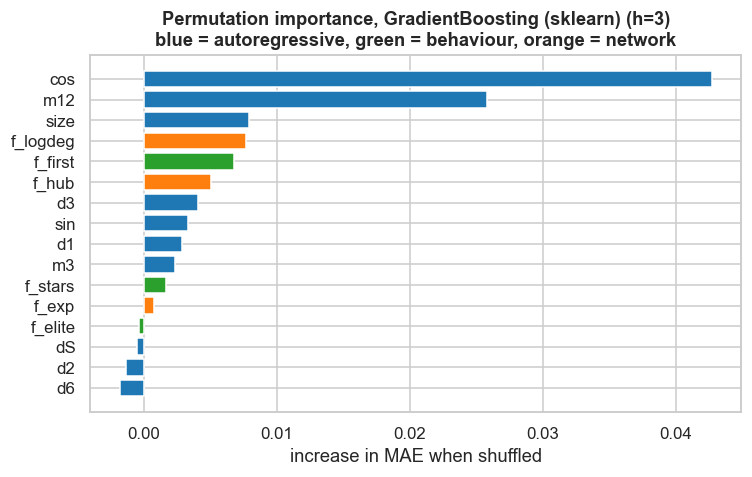

In [73]:
panel = [c for c in cstat.sort_values('reviews_in_window', ascending=False).index if cstat.loc[c, 'median_monthly'] >= 10][:12]
if len(panel) < 3: panel = list(topk[:8])
print(f"Panel: {len(panel)} communities -> {panel}")

# ---- monthly network / behavioural features per community (smoothed over 3 months) ----
g_net['deg'] = g_net['user_id'].map(deg).fillna(0); g_net['logdeg'] = np.log1p(g_net['deg']); g_net['hub'] = (g_net['deg'] >= 20).astype(float)
for c_ in ['is_elite_at_review', 'first_time']: g_net[c_] = g_net[c_].astype(float)
grp = g_net[g_net['community'].isin(panel)].groupby(['month', 'community'])
netc = net.assign(community=net['community'].astype(int)); netc = netc[netc['community'].isin(panel)]
raw = {'f_logdeg': grp['logdeg'].mean().unstack(), 'f_hub': grp['hub'].mean().unstack(), 'f_exp': netc.groupby(['month', 'community'])['exp_1_30'].mean().unstack(),
       'f_stars': grp['stars'].mean().unstack(), 'f_elite': grp['is_elite_at_review'].mean().unstack(), 'f_first': grp['first_time'].mean().unstack()}
feat_frames = {k: v.reindex(index=idx, columns=panel).rolling(3, min_periods=1).mean().ffill().bfill().fillna(0) for k, v in raw.items()}
AR  = ['d1', 'd2', 'd3', 'd6', 'dS', 'm3', 'm12', 'sin', 'cos', 'size']
BEH = ['f_stars', 'f_elite', 'f_first']; NETF = ['f_logdeg', 'f_hub', 'f_exp']

def panel_table(h):
    parts = []
    for c in panel:
        ls = np.log1p(cm[c].astype(float)); X_, y_, sn_, td_ = sup_feats(ls, h, 12, 'M')
        X_['size'] = ls.rolling(12, min_periods=1).mean()
        for k, F in feat_frames.items(): X_[k] = F[c]
        X_['y'], X_['sn'], X_['tdate'], X_['sid'] = y_, sn_, td_, c
        parts.append(X_.dropna())
    return pd.concat(parts)

sets = {'Seasonal naive': None, f'{GBM_NAME}: autoregressive': AR, f'{GBM_NAME}: + behaviour': AR + BEH, f'{GBM_NAME}: + network': AR + NETF,
        f'{GBM_NAME}: + behaviour + network': AR + BEH + NETF, 'ANN (MLP): all features': AR + BEH + NETF}
res_h = {}; last_model = None
for h in (1, 3, 6, 12):
    T = panel_table(h); trn = T[T['tdate'] < PRE_TEST_START]; tst = T[(T.index >= PRE_TEST_START) & (T['tdate'] <= last_pre)]
    r = {'Seasonal naive': np.mean(np.abs(tst['y'] - tst['sn']))}
    for nm, cols in sets.items():
        if cols is None: continue
        m_ = MLPEnsemble() if nm.startswith('ANN') else make_gbm()
        m_.fit(trn[cols].values, trn['y'].values); r[nm] = np.mean(np.abs(tst['y'] - m_.predict(tst[cols].values)))
        if h == 3 and nm.endswith('behaviour + network'): last_model = (m_, tst[cols], tst['y'])
    res_h[f'h={h}'] = r
    print(f"h={h:>2}: train rows {len(trn):,} | test rows {len(tst):,}")
pt = pd.DataFrame(res_h); pt['mean'] = pt.mean(axis=1); pt['skill_vs_snaive'] = 1 - pt['mean'] / pt.loc['Seasonal naive', 'mean']
RESULTS['panel_forecast_mae_log'] = pt; display(pt.round(3))
print("MAE is on the log1p scale (~ relative error of the level forecast). skill_vs_snaive > 0 = better than seasonal naive.")

if last_model is not None:
    m_, Xte_, yte_ = last_model
    pi = permutation_importance(m_, Xte_.values, yte_.values, n_repeats=10, random_state=SEED, scoring='neg_mean_absolute_error')
    imp = pd.Series(pi.importances_mean, index=Xte_.columns).sort_values()
    fig, ax = plt.subplots(figsize=(7, 4.5)); ax.barh(imp.index, imp.values, color=['tab:orange' if c in NETF else 'tab:green' if c in BEH else 'tab:blue' for c in imp.index])
    ax.set_title(f'Permutation importance, {GBM_NAME} (h=3)\nblue = autoregressive, green = behaviour, orange = network'); ax.set_xlabel('increase in MAE when shuffled'); plt.tight_layout(); plt.show()

,RMSE,MAE,MAPE_pct,MASE,MASE h1-3,MASE h4-6,MASE h7-12
model,,,,,,,
Direct seasonal naive + drift,206.719,170.811,11.602,0.988,0.774,0.990,1.094
Bottom-up seasonal naive + drift,229.106,190.289,12.912,1.099,0.841,1.064,1.245
Bottom-up SARIMA (sum of communities),272.652,213.198,14.658,1.235,0.720,1.105,1.556
Direct SARIMA (total),280.608,226.617,15.465,1.314,0.722,1.147,1.693


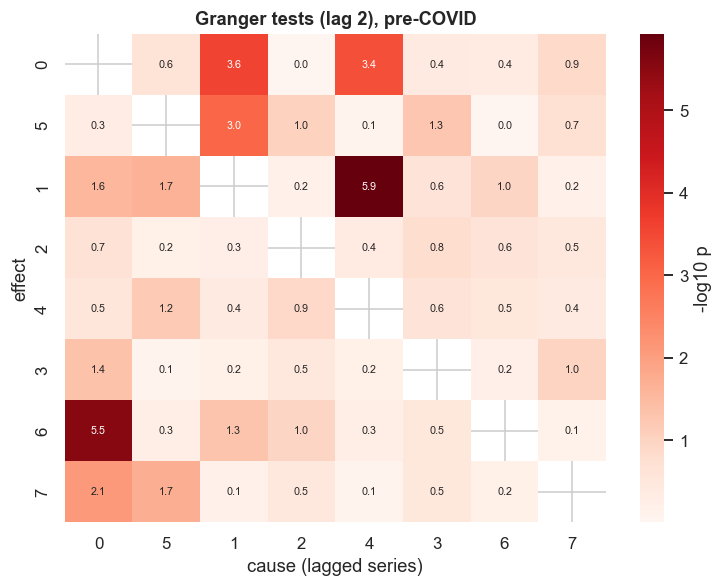

Directed pairs significant after Holm correction (56 tests): 5


,effect,cause,p,p_holm
17,1,4,0.000001,0.000066
42,6,0,0.000003,0.000163
1,0,1,0.000259,0.013978
3,0,4,0.000396,0.021007
8,5,1,0.000940,0.048856


In [74]:
# ---------- bottom-up vs. direct forecast of the panel total ----------
Tot = cm[panel].sum(axis=1).astype(float); fa = make_f_sarima((1, 1, 1), (0, 1, 1, 12)); rows = []
for o in origins:
    trainT = Tot.loc[:o]; testT = Tot.loc[o + pd.DateOffset(months=1): o + pd.DateOffset(months=H)]
    add_rows(rows, 'Direct SARIMA (total)', o, trainT, testT, np.exp(fa(np.log(trainT.clip(lower=1)), H))[:len(testT)])
    add_rows(rows, 'Bottom-up SARIMA (sum of communities)', o, trainT, testT, sum(np.expm1(fa(np.log1p(cm[c].loc[:o].astype(float)), H)) for c in panel)[:len(testT)])
    add_rows(rows, 'Direct seasonal naive + drift', o, trainT, testT, np.exp(f_snaive_drift(np.log(trainT.clip(lower=1)), H))[:len(testT)])
    add_rows(rows, 'Bottom-up seasonal naive + drift', o, trainT, testT, sum(np.expm1(f_snaive_drift(np.log1p(cm[c].loc[:o].astype(float)), H)) for c in panel)[:len(testT)])
bu = summarise(pd.DataFrame(rows)); RESULTS['bottom_up_vs_direct'] = bu; display(bu.round(3))

# ---------- Granger causality between communities (pre-COVID, seasonally differenced log1p) ----------
D = np.log1p(cm.loc[y_pre.index, panel].astype(float)).diff().diff(12).dropna(); LAG = 2; pv = pd.DataFrame(np.nan, index=panel, columns=panel)
for a in panel:
    for b in panel:
        if a == b: continue
        try: pv.loc[a, b] = grangercausalitytests(D[[a, b]], maxlag=LAG, verbose=False)[LAG][0]['ssr_ftest'][1]       # does b help predict a?
        except Exception: pass
flat = pv.stack().rename('p').reset_index(); flat.columns = ['effect', 'cause', 'p']
flat['p_holm'] = multipletests(flat['p'].values, method='holm')[1]; sig = flat[flat['p_holm'] < .05].sort_values('p')
RESULTS['granger_significant'] = sig
fig, ax = plt.subplots(figsize=(7, 5.5)); sns.heatmap(-np.log10(pv.astype(float)), annot=True, fmt='.1f', cmap='Reds', ax=ax, annot_kws={'size': 7}, cbar_kws={'label': '-log10 p'})
ax.set_xlabel('cause (lagged series)'); ax.set_ylabel('effect'); ax.set_title(f'Granger tests (lag {LAG}), pre-COVID'); plt.tight_layout(); plt.show()
print(f"Directed pairs significant after Holm correction ({len(flat)} tests): {len(sig)}")
display(sig.head(10)) if len(sig) else print("No community 'leads' another once multiple testing is accounted for -> communities move together (shared seasonality/shocks) rather than in sequence.")

## 10. Summary of results and next steps
All result tables of sections 7-9 are collected in `RESULTS` and saved to `modelling_results/` (one CSV per table). Suggested write-up order: (1) baselines vs. SARIMA back-test, (2) COVID counterfactual and category recovery, (3) weekly ML vs ANN, (4) network structure and robustness, (5) influence case-control, (6) panel forecast with/without network features.

**Ideas not implemented here:** change-point detection (`ruptures`) to date the COVID break from the data; LSTM / N-BEATS on the weekly or panel data (needs `torch`); hierarchical reconciliation (MinT) across category -> total; independent-cascade simulation using the influence estimates; graph neural networks on the community graph.

In [75]:
out_dir = os.path.join(target_path, 'modelling_results'); os.makedirs(out_dir, exist_ok=True)
for name, tbl in RESULTS.items():
    try: pd.DataFrame(tbl).to_csv(os.path.join(out_dir, f'{name}.csv'))
    except Exception as ex_: print(f"could not save {name}: {ex_}")
print(f"Saved {len(RESULTS)} tables to {out_dir}\n")
for key in ['ts_monthly_backtest', 'ts_weekly_ml', 'panel_forecast_mae_log', 'bottom_up_vs_direct', 'influence_case_control', 'link_prediction_auc']:
    if key in RESULTS: print(f"--- {key} ---"); display(RESULTS[key].round(3))

Saved 13 tables to c:\Users\iscap\Desktop\FEUP\ADC\ADC\modelling_results

--- ts_monthly_backtest ---


,RMSE,MAE,MAPE_pct,MASE,MASE h1-3,MASE h4-6,MASE h7-12
model,,,,,,,
Seasonal naive,285.178,223.702,7.356,0.657,0.559,0.788,0.640
Seasonal naive + drift,381.842,304.980,10.209,0.886,0.650,0.876,1.009
"ETS (damped trend, additive seasonal)",386.120,312.966,10.299,0.915,0.622,0.793,1.123
"SARIMA(0, 1, 2)x(0, 1, 1, 12)",501.109,424.731,13.932,1.242,0.739,1.128,1.550
"SARIMA airline (0,1,1)x(0,1,1,12)",510.298,432.535,14.190,1.263,0.746,1.144,1.581
Naive,722.828,598.643,19.631,1.761,1.226,2.616,1.600
"STL + ARIMA(1,1,1) with drift",903.338,753.390,24.510,2.199,0.886,1.616,3.146


--- ts_weekly_ml ---


,MAE_log,RMSE_log,MAPE_pct,skill_vs_snaive
model,,,,
GradientBoosting (sklearn),0.073,0.090,7.619,0.194
ANN (MLP ensemble),0.085,0.105,8.949,0.057
Seasonal naive (52w),0.091,0.113,9.548,0.000
Ridge (linear),0.099,0.118,10.507,-0.093


--- panel_forecast_mae_log ---


,h=1,h=3,h=6,h=12,mean,skill_vs_snaive
Seasonal naive,0.227,0.224,0.220,0.219,0.223,0.000
GradientBoosting (sklearn): autoregressive,0.185,0.220,0.248,0.349,0.250,-0.124
GradientBoosting (sklearn): + behaviour,0.188,0.211,0.243,0.316,0.239,-0.076
GradientBoosting (sklearn): + network,0.185,0.210,0.234,0.307,0.234,-0.051
GradientBoosting (sklearn): + behaviour + network,0.190,0.203,0.220,0.290,0.226,-0.014
ANN (MLP): all features,0.174,0.190,0.232,0.252,0.212,0.047


--- bottom_up_vs_direct ---


,RMSE,MAE,MAPE_pct,MASE,MASE h1-3,MASE h4-6,MASE h7-12
model,,,,,,,
Direct seasonal naive + drift,206.719,170.811,11.602,0.988,0.774,0.990,1.094
Bottom-up seasonal naive + drift,229.106,190.289,12.912,1.099,0.841,1.064,1.245
Bottom-up SARIMA (sum of communities),272.652,213.198,14.658,1.235,0.720,1.105,1.556
Direct SARIMA (total),280.608,226.617,15.465,1.314,0.722,1.147,1.693


--- link_prediction_auc ---


,random negatives (all held-out edges),friend-of-friend negatives (triangle-closing edges only)
cn,0.879,0.871
jaccard,0.877,0.550
adamic_adar,0.880,0.812
pref_attach,0.900,0.881
co_reviewed,0.531,0.525
GradientBoosting (sklearn): graph features,0.949,0.917
GradientBoosting (sklearn): graph + non-graph,0.952,0.918
